CELL 1 — INSTALL & IMPORT LIBRARY

In [ ]:
import warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from openpyxl import load_workbook, Workbook
from google.colab import files

warnings.filterwarnings('ignore')

print("✅ Library siap.")

✅ Library siap.


CELL 2 — UPLOAD FILE EXCEL


In [ ]:
"""
FORMAT A — File Referensi (R1, R2 diambil bersamaan):
  Sheet: Ringkasan, R1, R2
  Nama contoh: data_Skenario1_LOS_Referensi_*.xlsx

FORMAT A — File Referensi (R1, R2, R3 diambil bersamaan):
  Sheet: Ringkasan, R1, R2, R3
  Nama contoh: data_Skenario2_LOS_Referensi_*.xlsx

FORMAT B — File Target (R1+R2+Target bersamaan):
  Sheet: Ringkasan, Target, R1, R2
  Nama contoh: data_Skenario1_LOS_Target_80cm_*.xlsx

FORMAT B — File Target (R1+R2+R3+Target bersamaan):
  Sheet: Ringkasan, Target, R1, R2, R3
  Nama contoh: data_Skenario2_LOS_Target_80cm_*.xlsx
"""

print("Upload file Excel (referensi atau target, bisa sekaligus banyak):")
uploaded = files.upload()
filenames = list(uploaded.keys())

print(f"\n✅ File diupload ({len(filenames)} file):")
for fname in filenames:
    print(f"   → {fname}")

Upload file Excel (referensi atau target, bisa sekaligus banyak):


Saving data_Skenario2_LOS_Referensi_20260511_123032.xlsx to data_Skenario2_LOS_Referensi_20260511_123032.xlsx
Saving data_Skenario2_LOS_Target_80cm_20260511_123901.xlsx to data_Skenario2_LOS_Target_80cm_20260511_123901.xlsx
Saving data_Skenario2_LOS_Target_90cm_20260511_131200.xlsx to data_Skenario2_LOS_Target_90cm_20260511_131200.xlsx
Saving data_Skenario2_LOS_Target_100cm_20260511_124629.xlsx to data_Skenario2_LOS_Target_100cm_20260511_124629.xlsx
Saving data_Skenario2_LOS_Target_110cm_20260511_131954.xlsx to data_Skenario2_LOS_Target_110cm_20260511_131954.xlsx
Saving data_Skenario2_LOS_Target_140cm_20260511_125405.xlsx to data_Skenario2_LOS_Target_140cm_20260511_125405.xlsx
Saving data_Skenario2_LOS_Target_170cm_20260511_130502.xlsx to data_Skenario2_LOS_Target_170cm_20260511_130502.xlsx
Saving data_Skenario2_NLOS_Banyak_Referensi_20260511_011823.xlsx to data_Skenario2_NLOS_Banyak_Referensi_20260511_011823.xlsx
Saving data_Skenario2_NLOS_Banyak_Target_80cm_20260511_012539.xlsx to da

CELL 3 — BACA FILE EXCEL

In [ ]:
def deteksi_kondisi(fname: str) -> str:
    fname_norm = fname.replace('_', '').lower()
    condition_map = {
        'NLOS_Sedikit': 'NLOS_Satu_Halangan',
        'NLOS_Sedang': 'NLOS_Tiga_Halangan',
        'NLOS_Banyak': 'NLOS_Lima_Halangan'
    }

    for nama_file, kondisi_baru in condition_map.items():
        nama_norm = nama_file.replace('_', '').lower()
        if nama_norm in fname_norm:
            return kondisi_baru
    return 'LOS'

"""Referensi tidak memiliki sheet Target; target memiliki sheet Target."""
def deteksi_tipe_file(wb) -> str:
    sheets_lower = [sheet.lower() for sheet in wb.sheetnames]
    return 'target' if 'target' in sheets_lower else 'referensi'

"""Baca satu sheet menjadi DataFrame dengan RSSI numerik."""
def baca_sheet(ws) -> pd.DataFrame:
    rows = list(ws.iter_rows(values_only=True))
    if len(rows) < 2:
        return pd.DataFrame()

    df = pd.DataFrame(rows[1:], columns=rows[0])
    df['RSSI (dBm)'] = pd.to_numeric(df['RSSI (dBm)'], errors='coerce')
    return df.dropna(subset=['RSSI (dBm)'])

def baca_semua_file(filenames: list) -> dict:
    hasil = {'referensi': [], 'target': []}

    for fname in filenames:
        wb = load_workbook(fname)
        tipe = deteksi_tipe_file(wb)

        parts = fname.replace('.xlsx', '').split('_')
        skenario = next((p for p in parts if 'Skenario' in p), 'Skenario1')
        kondisi = deteksi_kondisi(fname)

        sheets = {}
        for sheet_name in wb.sheetnames:
            if sheet_name.lower() == 'ringkasan':
                continue

            df = baca_sheet(wb[sheet_name])
            if not df.empty:
                sheets[sheet_name] = df

        if tipe == 'referensi':
            hasil['referensi'].append({
                'filename': fname,
                'skenario': skenario,
                'kondisi': kondisi,
                'sheets': sheets
            })
        else:
            jarak_cm = 0.0
            if 'Target' in sheets and 'Jarak Aktual (cm)' in sheets['Target'].columns:
                jarak_cm = float(sheets['Target']['Jarak Aktual (cm)'].iloc[0])

            hasil['target'].append({
                'filename': fname,
                'skenario': skenario,
                'kondisi': kondisi,
                'jarak_cm': jarak_cm,
                'sheets': sheets
            })

    return hasil

semua_file = baca_semua_file(filenames)

print("\n✅ Hasil deteksi tipe file:")
print(f"   File Referensi : {len(semua_file['referensi'])} file")
for f in semua_file['referensi']:
    sheets_str = ', '.join(f['sheets'].keys())
    print(f"   → {f['filename']} | {f['skenario']} | {f['kondisi']} | sheets: [{sheets_str}]")

print(f"\n   File Target    : {len(semua_file['target'])} file")
for f in semua_file['target']:
    sheets_str = ', '.join(f['sheets'].keys())
    print(f"   → {f['filename']} | {f['skenario']} | {f['kondisi']} | jarak: {f['jarak_cm']} cm | sheets: [{sheets_str}]")


✅ Hasil deteksi tipe file:
   File Referensi : 4 file
   → data_Skenario2_LOS_Referensi_20260511_123032.xlsx | Skenario2 | LOS | sheets: [R1, R2, R3]
   → data_Skenario2_NLOS_Banyak_Referensi_20260511_011823.xlsx | Skenario2 | NLOS_Lima_Halangan | sheets: [R1, R2, R3]
   → data_Skenario2_NLOS_Sedang_Referensi_20260511_021945.xlsx | Skenario2 | NLOS_Tiga_Halangan | sheets: [R1, R2, R3]
   → data_Skenario2_NLOS_Sedikit_Referensi_20260511_113828.xlsx | Skenario2 | NLOS_Satu_Halangan | sheets: [R1, R2, R3]

   File Target    : 24 file
   → data_Skenario2_LOS_Target_80cm_20260511_123901.xlsx | Skenario2 | LOS | jarak: 80.0 cm | sheets: [Target, R1, R2, R3]
   → data_Skenario2_LOS_Target_90cm_20260511_131200.xlsx | Skenario2 | LOS | jarak: 90.0 cm | sheets: [Target, R1, R2, R3]
   → data_Skenario2_LOS_Target_100cm_20260511_124629.xlsx | Skenario2 | LOS | jarak: 100.0 cm | sheets: [Target, R1, R2, R3]
   → data_Skenario2_LOS_Target_110cm_20260511_131954.xlsx | Skenario2 | LOS | jarak: 110.0 

CELL 4 — GAUSSIAN FILTER

In [ ]:
"""
    Gaussian Filter — Persamaan 3.1, 3.2, 2.3, 3.3, 3.4.

    Args:
        rssi_array   : array RSSI mentah
        k            : koefisien interval awal
        q_threshold  : batas minimum persentase data yang dipertahankan

    Returns: dict hasil filtering
"""
def gaussian_filter(rssi_array: np.ndarray, k: float = 1.0, q_threshold: float = 0.5) -> dict:
    n = len(rssi_array)
    k_used = k

    while True:
        xe = np.mean(rssi_array)                          # Persamaan 3.1
        omega = np.sqrt(np.mean((rssi_array - xe) ** 2))  # Persamaan 3.2
        mask = np.abs(rssi_array - xe) < k_used * omega   # Persamaan 2.3
        data_bersih = rssi_array[mask]
        P = (len(data_bersih) / n) * 100                  # Persamaan 3.3

        if P >= q_threshold * 100 or k_used >= 3:
            break
        k_used += 1

    xe_bersih = np.mean(data_bersih) if len(data_bersih) > 0 else xe # Persamaan 3.4

    return {
        'xe': xe,
        'omega': omega,
        'k_used': k_used,
        'mask': mask,
        'data_bersih': data_bersih,
        'data_buang': rssi_array[~mask],
        'xe_bersih': xe_bersih,
        'P': P,
        'n_asli': n,
        'n_bersih': len(data_bersih),
        'n_buang': n - len(data_bersih)
    }

CELL 5 — KALMAN FILTER

In [ ]:
"""
    Kalman Filter — Persamaan 2.4 s/d 2.9.

    Args:
        rssi_array : array RSSI bersih dari Gaussian Filter
        phi        : faktor transisi state (default=1)
        Q          : process noise covariance (default=0.01)
        Rv         : measurement noise covariance (default=0.1)
        P0         : estimasi kovarians awal (default=1.0)

    Returns: dict hasil estimasi
"""
def kalman_filter(rssi_array: np.ndarray, phi: float = 1.0, Q: float = 0.01, Rv: float = 0.1, P0: float = 1.0) -> dict:
    x_est = rssi_array[0]
    P_est = P0
    x_update_list = []
    kalman_gain_list = []

    for zk in rssi_array:
        x_pred = phi * x_est                         # Persamaan 2.4
        P_pred = (phi * P_est * phi) + Q             # Persamaan 2.5
        Kk     = P_pred / (P_pred + Rv)              # Persamaan 2.7
        x_est  = x_pred + Kk * (zk - x_pred)         # Persamaan 2.8
        P_est  = (1 - Kk) * P_pred                   # Persamaan 2.9
        x_update_list.append(x_est)
        kalman_gain_list.append(Kk)

    return {
        'xk_final'   : x_est,
        'Pk_final'   : P_est,
        'x_update'   : np.array(x_update_list),
        'kalman_gain': np.array(kalman_gain_list),
    }

CELL 6 — PIPELINE PREPROCESSING LENGKAP

In [ ]:
def preprocessing_pipeline(rssi_array: np.ndarray, label: str = "") -> dict:
    g = gaussian_filter(rssi_array)
    k = kalman_filter(g['data_bersih'])
    return {
        'label': label,
        'rssi_mentah': rssi_array,
        'xe_asli': g['xe'],
        'omega': g['omega'],
        'xe_bersih': g['xe_bersih'],
        'mask_gauss': g['mask'],
        'n_asli': g['n_asli'],
        'n_bersih': g['n_bersih'],
        'n_buang': g['n_buang'],
        'P_retensi': g['P'],
        'xk_final': k['xk_final'],
        'Pk_final': k['Pk_final'],
        'x_update_seq': k['x_update'],
        'kalman_gain': k['kalman_gain']
    }

print("✅ Fungsi preprocessing siap.")

✅ Fungsi preprocessing siap.


CELL 7 — JALANKAN PREPROCESSING SEMUA FILE

In [ ]:
def proses_semua_file(semua_file: dict) -> dict:
    output = {'referensi': [], 'target': []}

    for f in semua_file['referensi']:
        hasil_sheets = {}
        for sheet_name, df in f['sheets'].items():
            hasil_sheets[sheet_name] = preprocessing_pipeline(df['RSSI (dBm)'].values, label=sheet_name)

        output['referensi'].append({
            'filename': f['filename'],
            'skenario': f['skenario'],
            'kondisi': f['kondisi'],
            'hasil': hasil_sheets
        })

    for f in semua_file['target']:
        hasil_sheets = {}
        for sheet_name, df in f['sheets'].items():
            hasil_sheets[sheet_name] = preprocessing_pipeline(df['RSSI (dBm)'].values, label=sheet_name)

        output['target'].append({
            'filename': f['filename'],
            'skenario': f['skenario'],
            'kondisi': f['kondisi'],
            'jarak_cm': f['jarak_cm'],
            'hasil': hasil_sheets
        })

    return output

print("=" * 60)
print("  MENJALANKAN PREPROCESSING SEMUA FILE")
print("=" * 60)

hasil_preprocessing = proses_semua_file(semua_file)

print("\n── FILE REFERENSI ──")
for f in hasil_preprocessing['referensi']:
    print(f"\n📄 {f['filename']}")
    print(f"   {f['skenario']} | {f['kondisi']}")
    print(f"   {'Sheet':<8} {'N asli':>8} {'N bersih':>10} {'P(%)':>7} {'xe bersih':>11} {'xk final':>11}")
    print(f"   {'-' * 8} {'-' * 8} {'-' * 10} {'-' * 7} {'-' * 11} {'-' * 11}")

    for sheet_name, h in f['hasil'].items():
        print(f"   {sheet_name:<8} {h['n_asli']:>8} {h['n_bersih']:>10} {h['P_retensi']:>6.1f}% {h['xe_bersih']:>11.4f} {h['xk_final']:>11.5f}")

print("\n── FILE TARGET ──")
for f in hasil_preprocessing['target']:
    print(f"\n📄 {f['filename']}")
    print(f"   {f['skenario']} | {f['kondisi']} | Jarak target: {f['jarak_cm']} cm")
    print(f"   {'Sheet':<8} {'N asli':>8} {'N bersih':>10} {'P(%)':>7} {'xe bersih':>11} {'xk final':>11}")
    print(f"   {'-' * 8} {'-' * 8} {'-' * 10} {'-' * 7} {'-' * 11} {'-' * 11}")

    for sheet_name, h in f['hasil'].items():
        print(f"   {sheet_name:<8} {h['n_asli']:>8} {h['n_bersih']:>10} {h['P_retensi']:>6.1f}% {h['xe_bersih']:>11.4f} {h['xk_final']:>11.5f}")

print("\n✅ Preprocessing selesai.")

  MENJALANKAN PREPROCESSING SEMUA FILE

── FILE REFERENSI ──

📄 data_Skenario2_LOS_Referensi_20260511_123032.xlsx
   Skenario2 | LOS
   Sheet      N asli   N bersih    P(%)   xe bersih    xk final
   -------- -------- ---------- ------- ----------- -----------
   R1            100         61   61.0%    -42.0000   -42.00000
   R2            100         93   93.0%    -51.5591   -51.48016
   R3            100         56   56.0%    -61.0000   -61.00000

📄 data_Skenario2_NLOS_Banyak_Referensi_20260511_011823.xlsx
   Skenario2 | NLOS_Lima_Halangan
   Sheet      N asli   N bersih    P(%)   xe bersih    xk final
   -------- -------- ---------- ------- ----------- -----------
   R1            100         86   86.0%    -53.0000   -53.00000
   R2            100         94   94.0%    -59.3404   -59.09457
   R3            100         53   53.0%    -67.0000   -67.00000

📄 data_Skenario2_NLOS_Sedang_Referensi_20260511_021945.xlsx
   Skenario2 | NLOS_Tiga_Halangan
   Sheet      N asli   N bersih    P(

CELL 8 — VISUALISASI

  VISUALISASI PREPROCESSING

📊 data_Skenario2_LOS_Referensi_20260511_123032.xlsx → R1


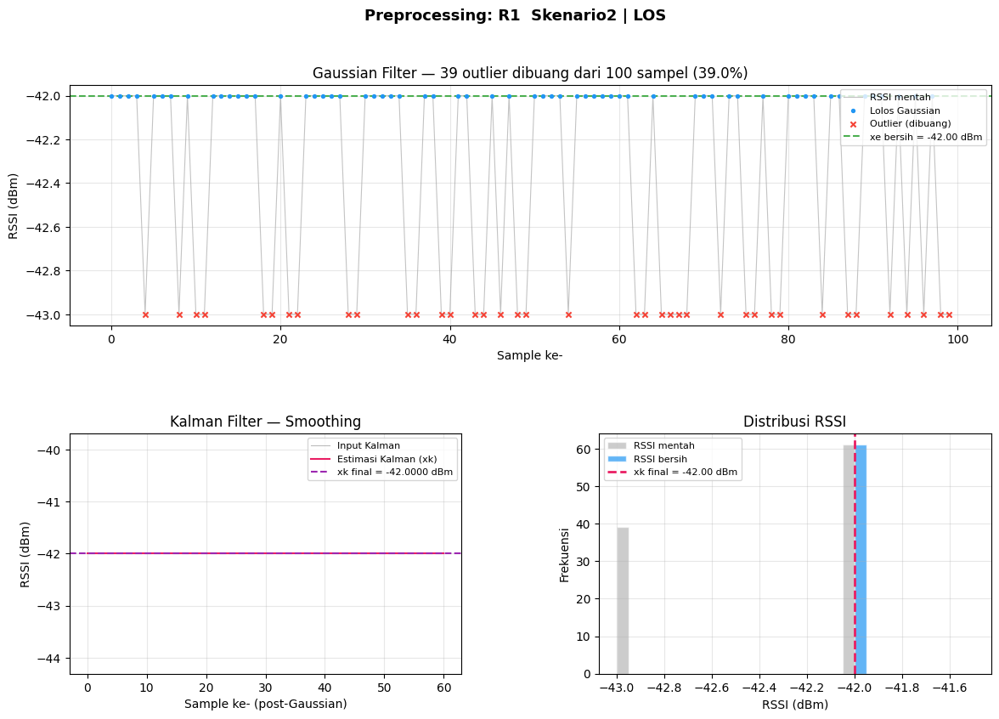

  ✅ Plot disimpan: preprocessing_R1_Skenario2__LOS.png

📊 data_Skenario2_LOS_Referensi_20260511_123032.xlsx → R2


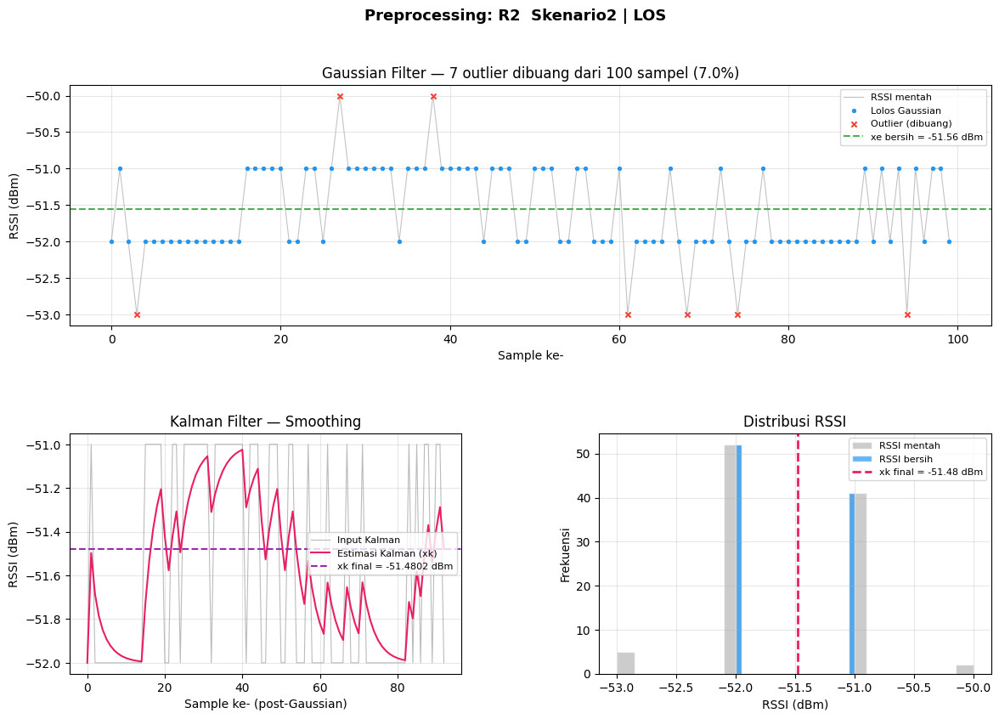

  ✅ Plot disimpan: preprocessing_R2_Skenario2__LOS.png

📊 data_Skenario2_LOS_Referensi_20260511_123032.xlsx → R3


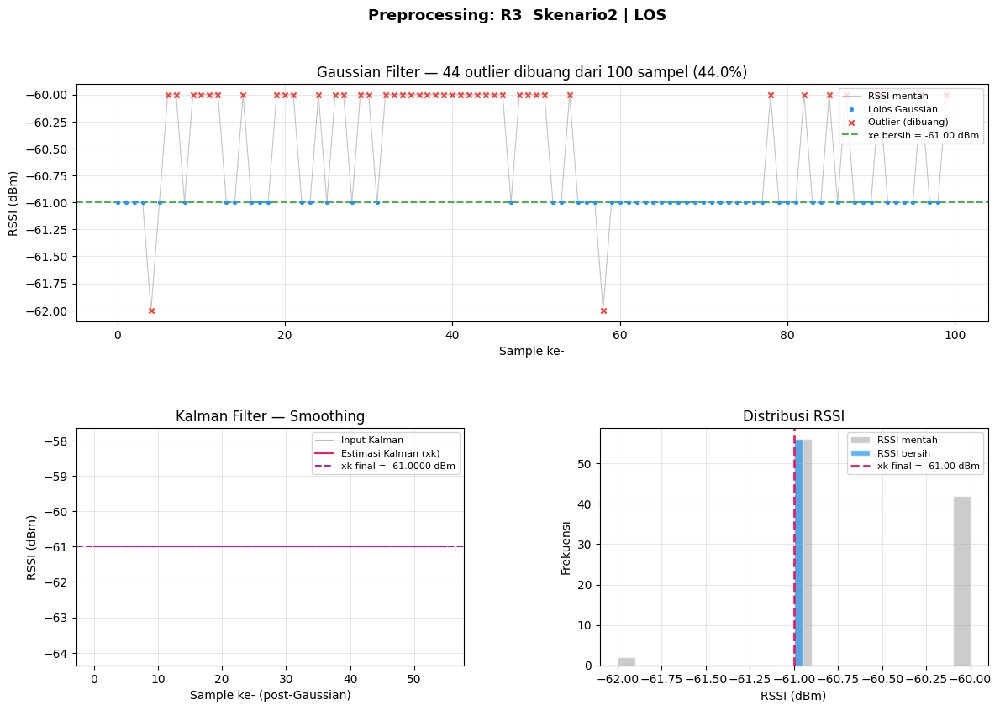

  ✅ Plot disimpan: preprocessing_R3_Skenario2__LOS.png

📊 data_Skenario2_NLOS_Banyak_Referensi_20260511_011823.xlsx → R1


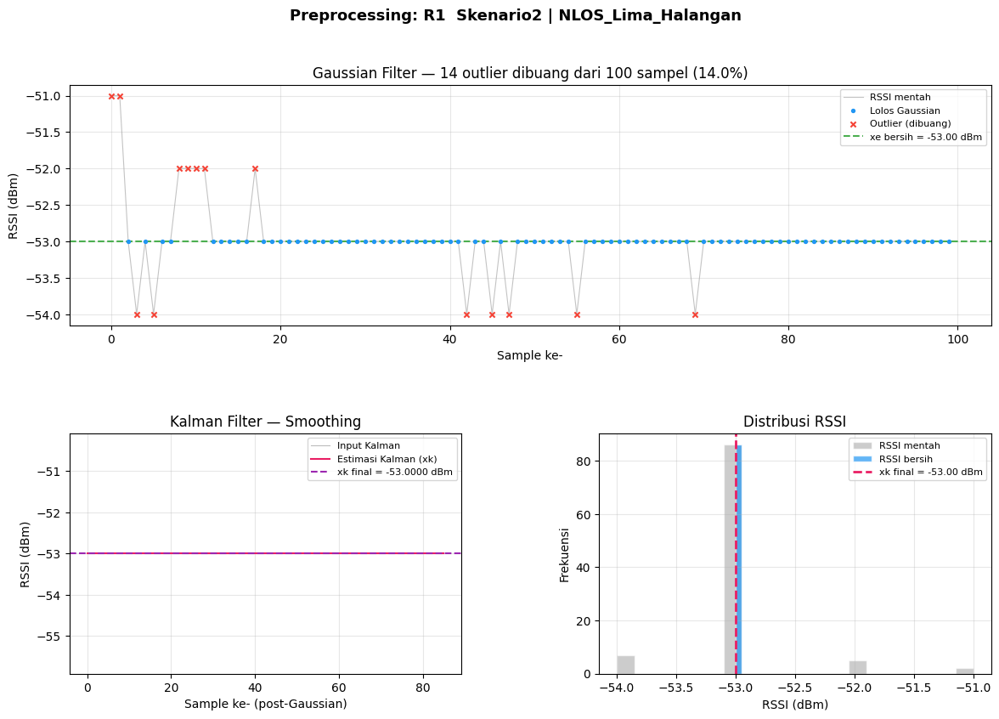

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Lima_Halangan.png

📊 data_Skenario2_NLOS_Banyak_Referensi_20260511_011823.xlsx → R2


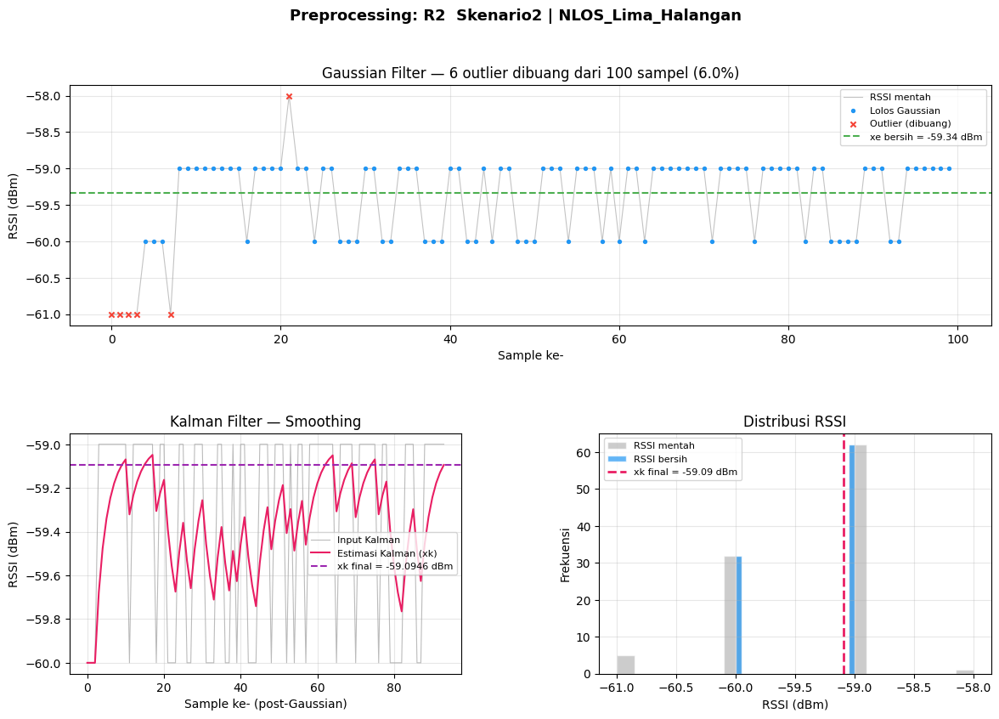

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Lima_Halangan.png

📊 data_Skenario2_NLOS_Banyak_Referensi_20260511_011823.xlsx → R3


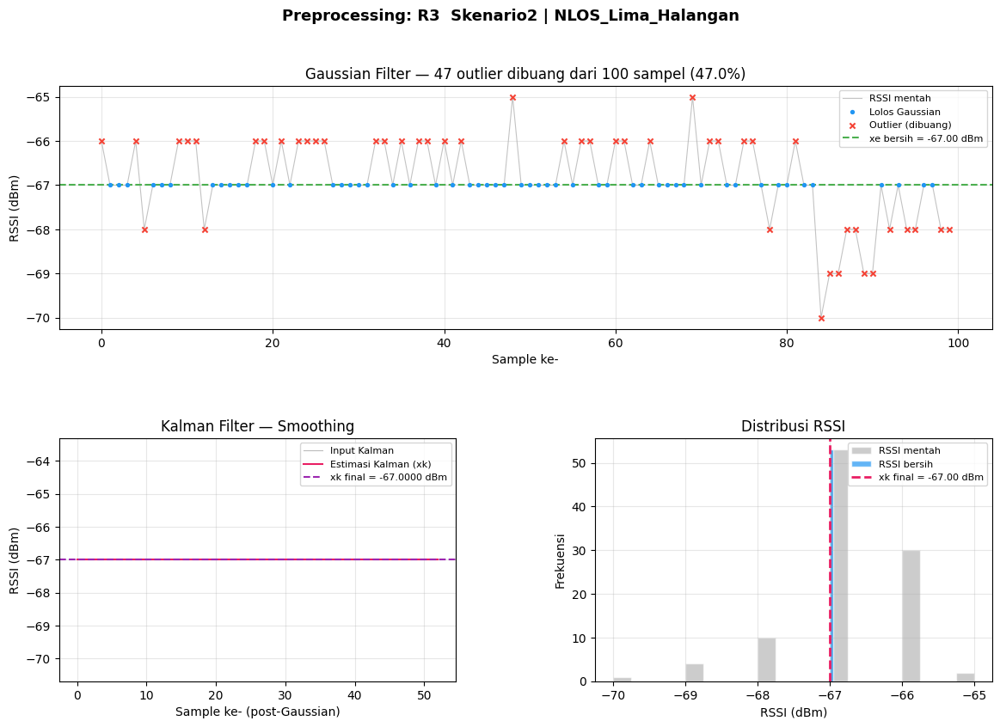

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Lima_Halangan.png

📊 data_Skenario2_NLOS_Sedang_Referensi_20260511_021945.xlsx → R1


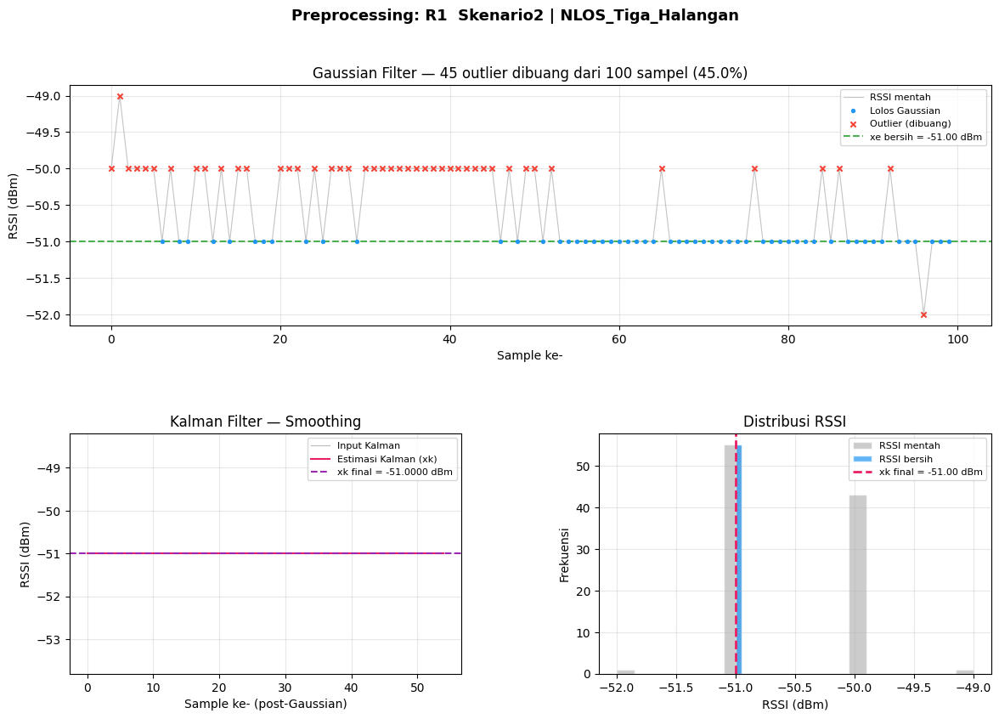

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Tiga_Halangan.png

📊 data_Skenario2_NLOS_Sedang_Referensi_20260511_021945.xlsx → R2


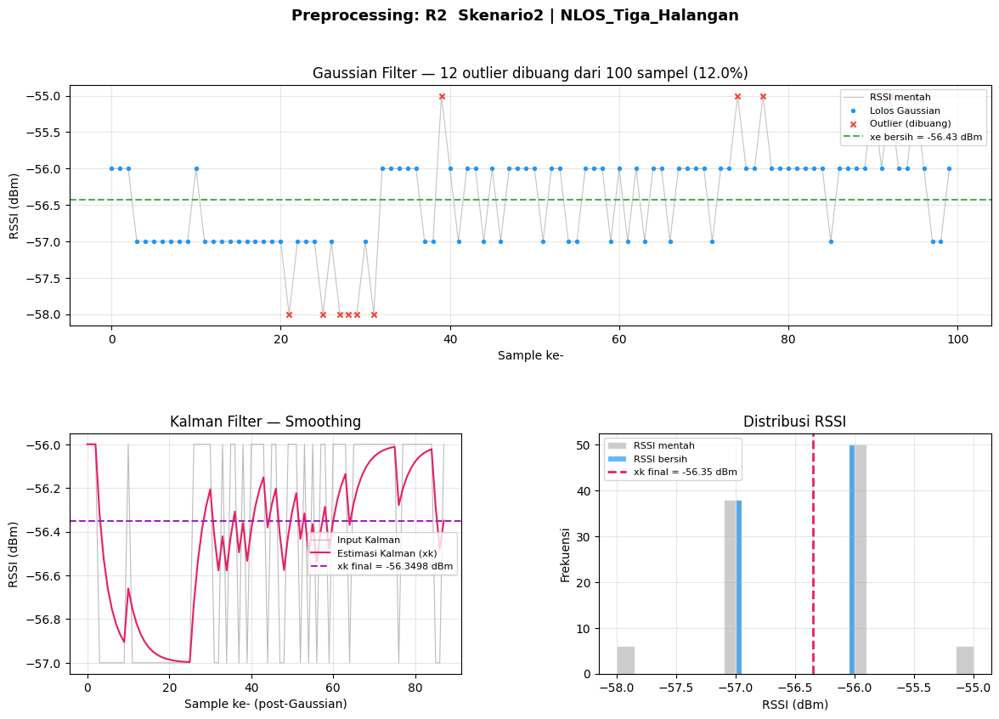

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Tiga_Halangan.png

📊 data_Skenario2_NLOS_Sedang_Referensi_20260511_021945.xlsx → R3


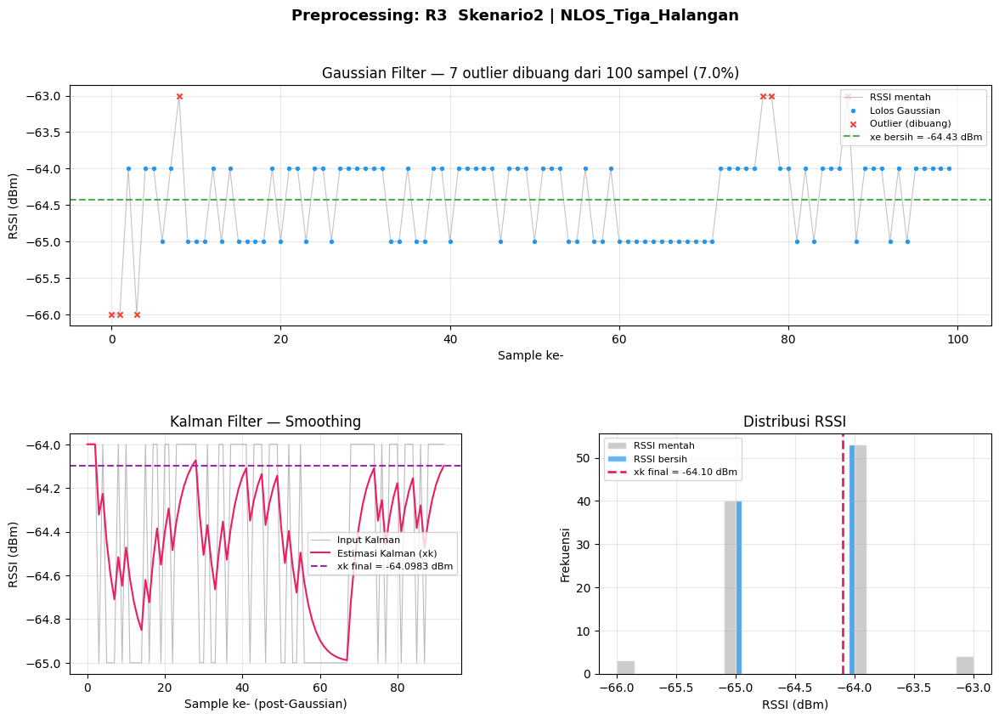

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Tiga_Halangan.png

📊 data_Skenario2_NLOS_Sedikit_Referensi_20260511_113828.xlsx → R1


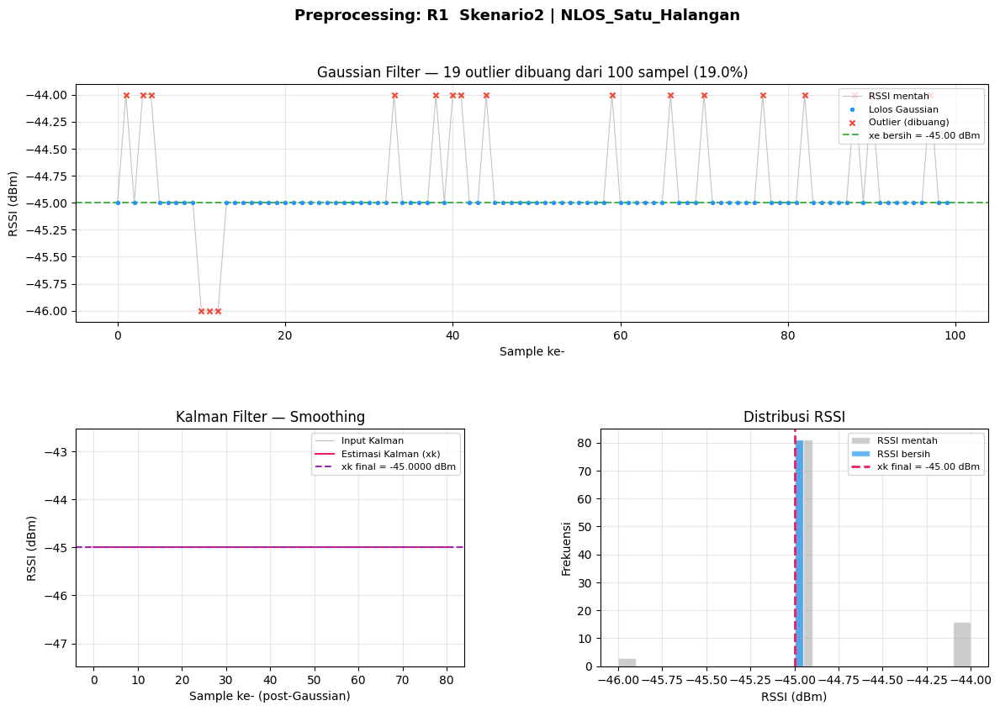

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Satu_Halangan.png

📊 data_Skenario2_NLOS_Sedikit_Referensi_20260511_113828.xlsx → R2


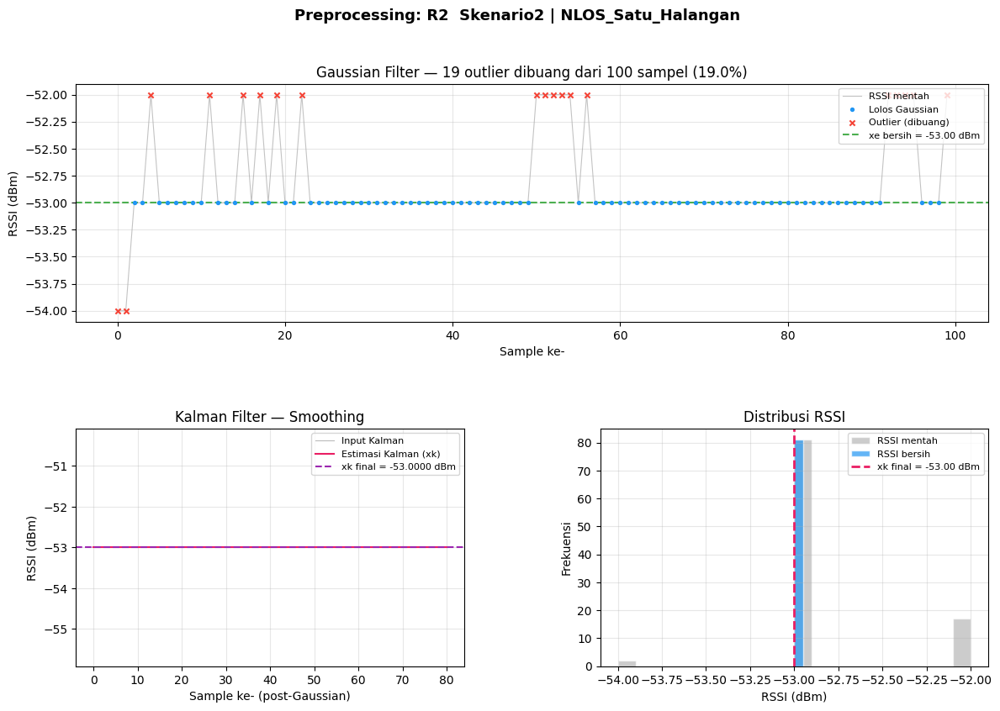

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Satu_Halangan.png

📊 data_Skenario2_NLOS_Sedikit_Referensi_20260511_113828.xlsx → R3


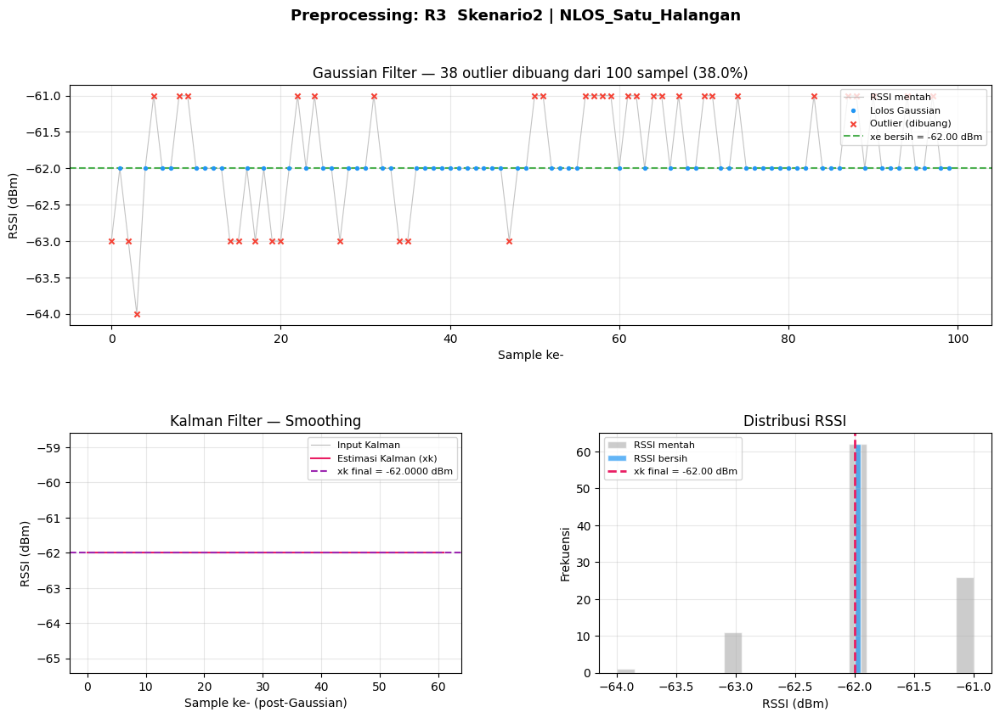

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Satu_Halangan.png

📊 data_Skenario2_LOS_Target_80cm_20260511_123901.xlsx → Target


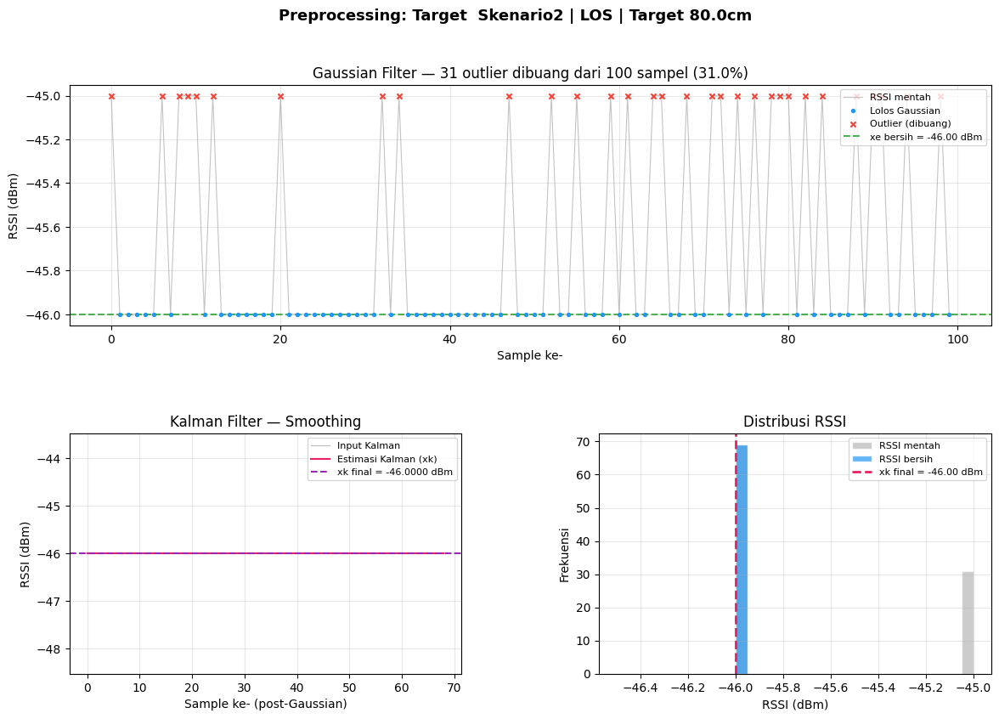

  ✅ Plot disimpan: preprocessing_Target_Skenario2__LOS__Target_80.0cm.png

📊 data_Skenario2_LOS_Target_80cm_20260511_123901.xlsx → R1


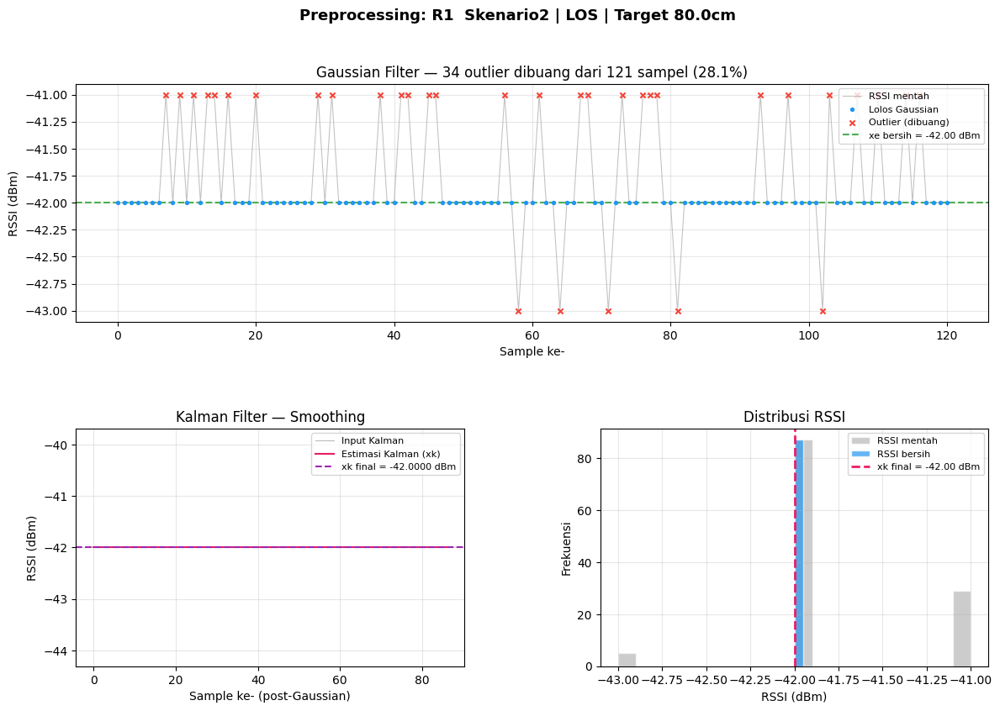

  ✅ Plot disimpan: preprocessing_R1_Skenario2__LOS__Target_80.0cm.png

📊 data_Skenario2_LOS_Target_80cm_20260511_123901.xlsx → R2


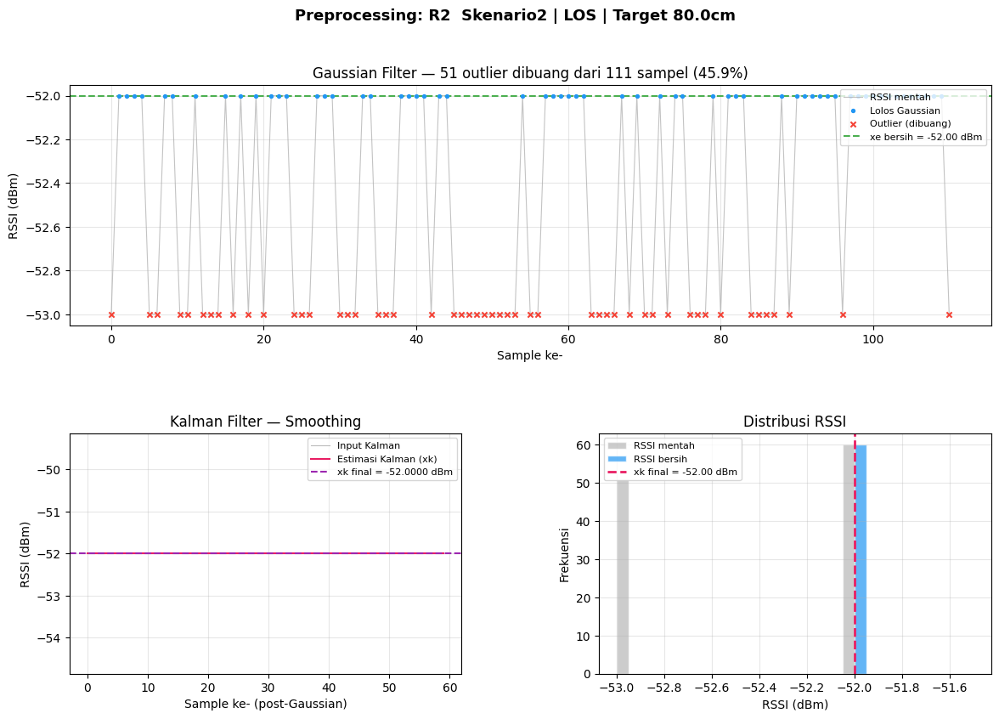

  ✅ Plot disimpan: preprocessing_R2_Skenario2__LOS__Target_80.0cm.png

📊 data_Skenario2_LOS_Target_80cm_20260511_123901.xlsx → R3


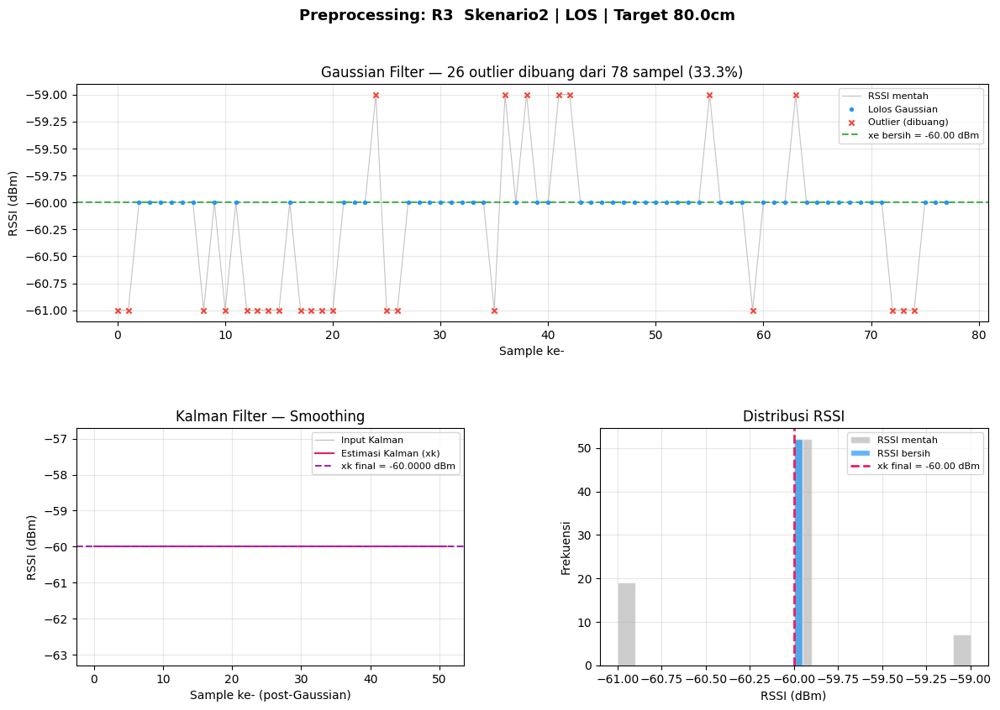

  ✅ Plot disimpan: preprocessing_R3_Skenario2__LOS__Target_80.0cm.png

📊 data_Skenario2_LOS_Target_90cm_20260511_131200.xlsx → Target


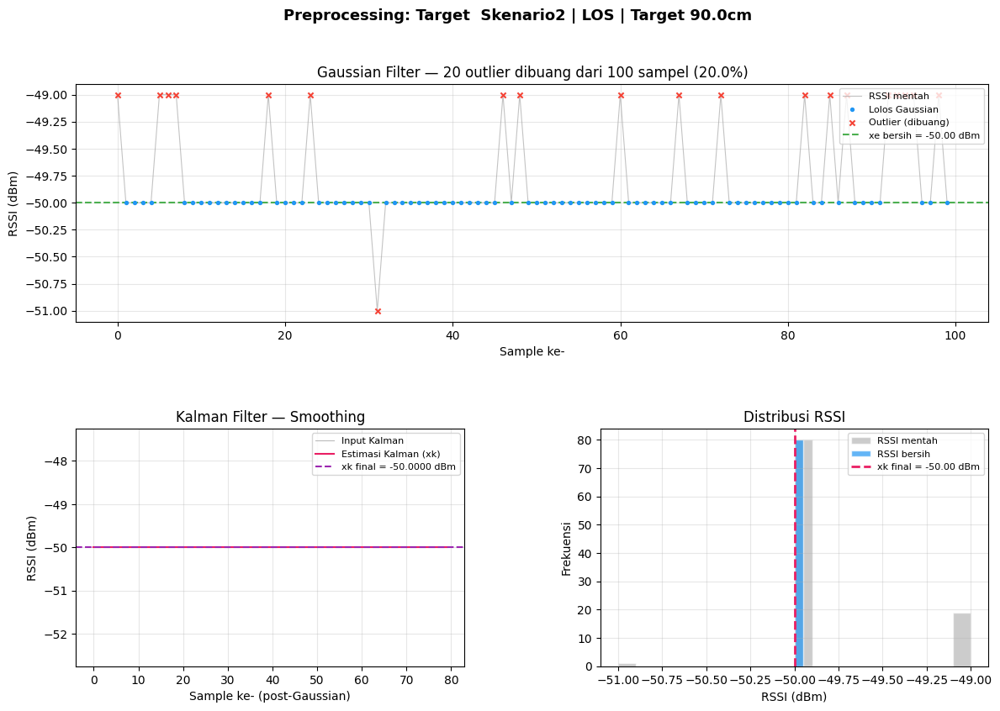

  ✅ Plot disimpan: preprocessing_Target_Skenario2__LOS__Target_90.0cm.png

📊 data_Skenario2_LOS_Target_90cm_20260511_131200.xlsx → R1


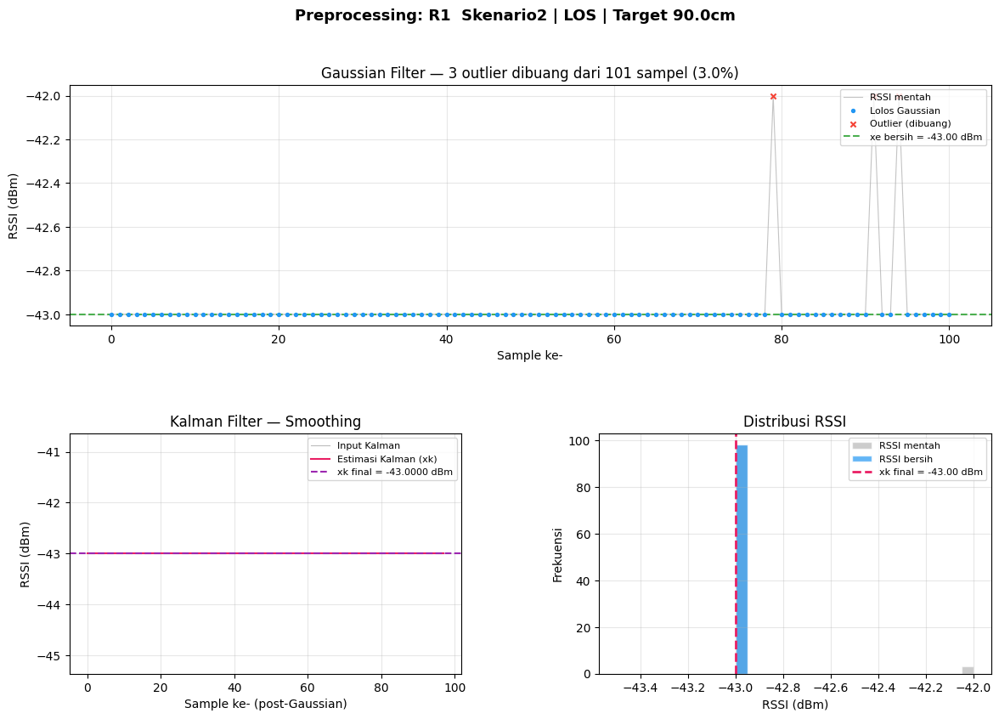

  ✅ Plot disimpan: preprocessing_R1_Skenario2__LOS__Target_90.0cm.png

📊 data_Skenario2_LOS_Target_90cm_20260511_131200.xlsx → R2


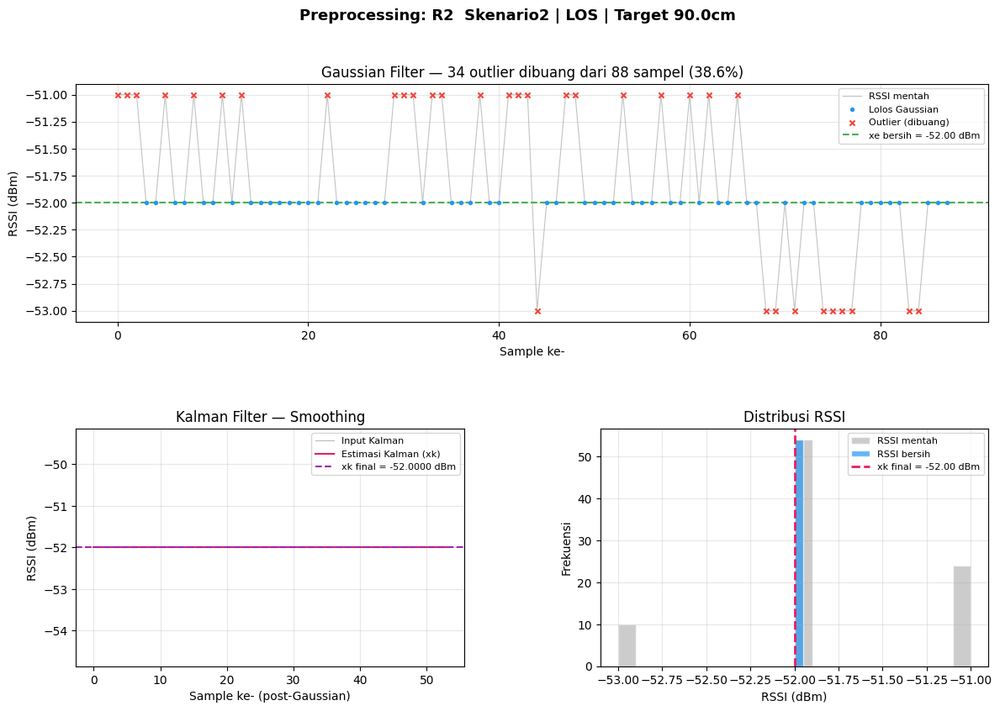

  ✅ Plot disimpan: preprocessing_R2_Skenario2__LOS__Target_90.0cm.png

📊 data_Skenario2_LOS_Target_90cm_20260511_131200.xlsx → R3


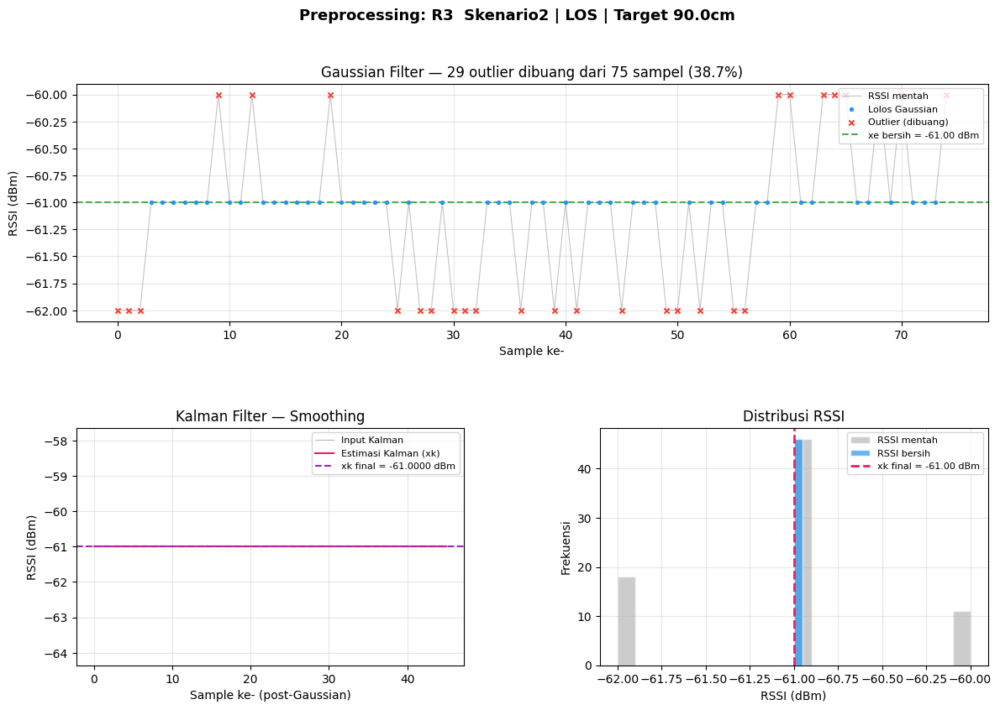

  ✅ Plot disimpan: preprocessing_R3_Skenario2__LOS__Target_90.0cm.png

📊 data_Skenario2_LOS_Target_100cm_20260511_124629.xlsx → Target


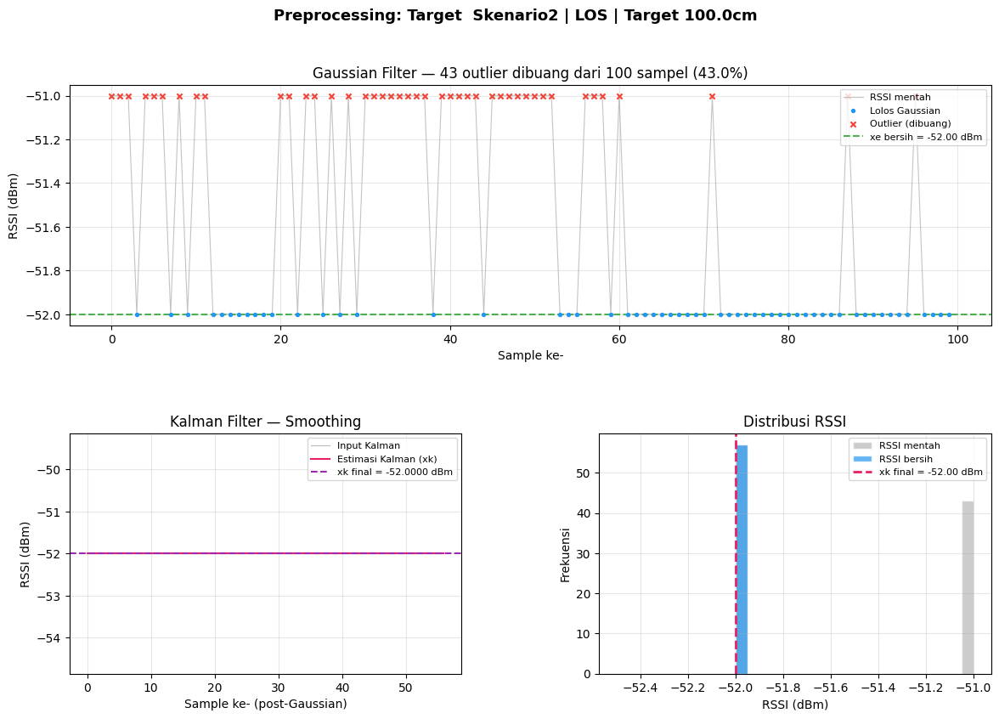

  ✅ Plot disimpan: preprocessing_Target_Skenario2__LOS__Target_100.0cm.png

📊 data_Skenario2_LOS_Target_100cm_20260511_124629.xlsx → R1


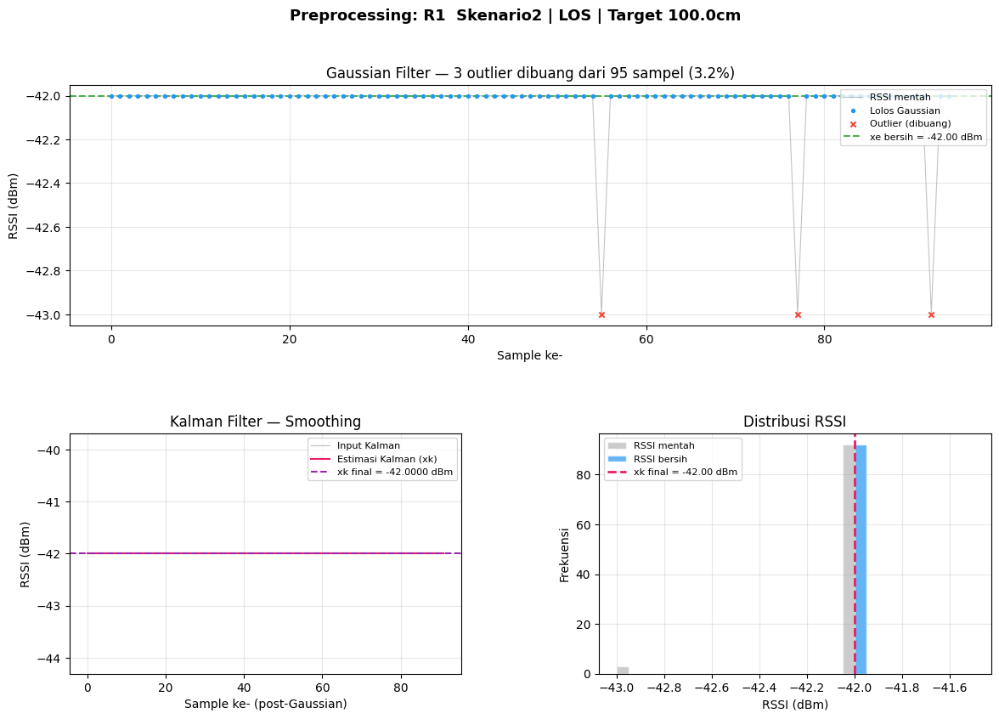

  ✅ Plot disimpan: preprocessing_R1_Skenario2__LOS__Target_100.0cm.png

📊 data_Skenario2_LOS_Target_100cm_20260511_124629.xlsx → R2


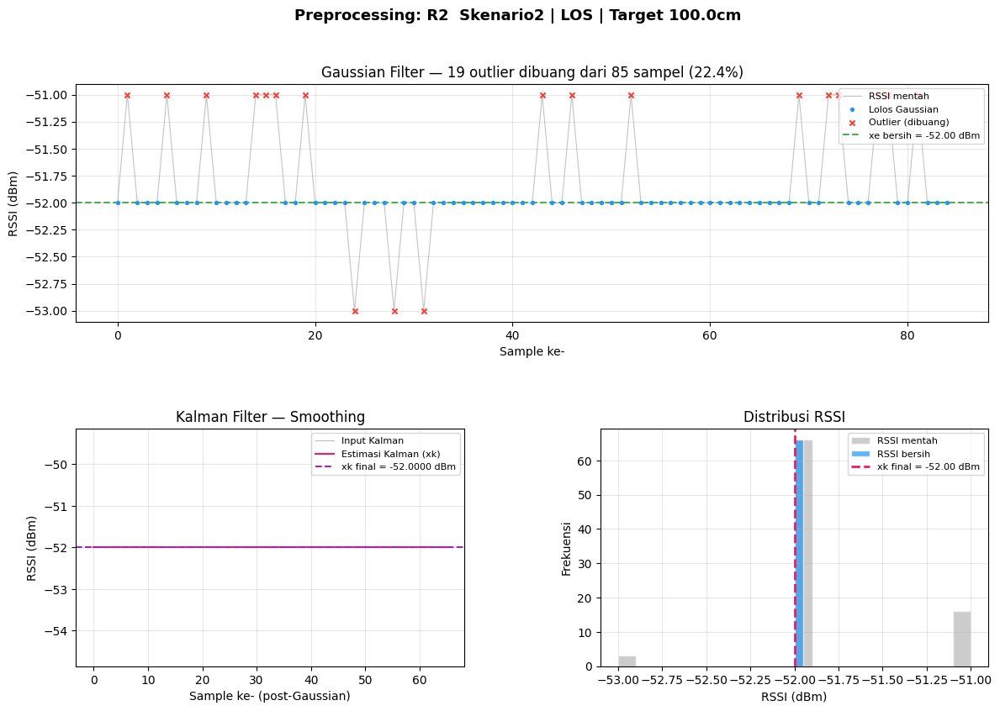

  ✅ Plot disimpan: preprocessing_R2_Skenario2__LOS__Target_100.0cm.png

📊 data_Skenario2_LOS_Target_100cm_20260511_124629.xlsx → R3


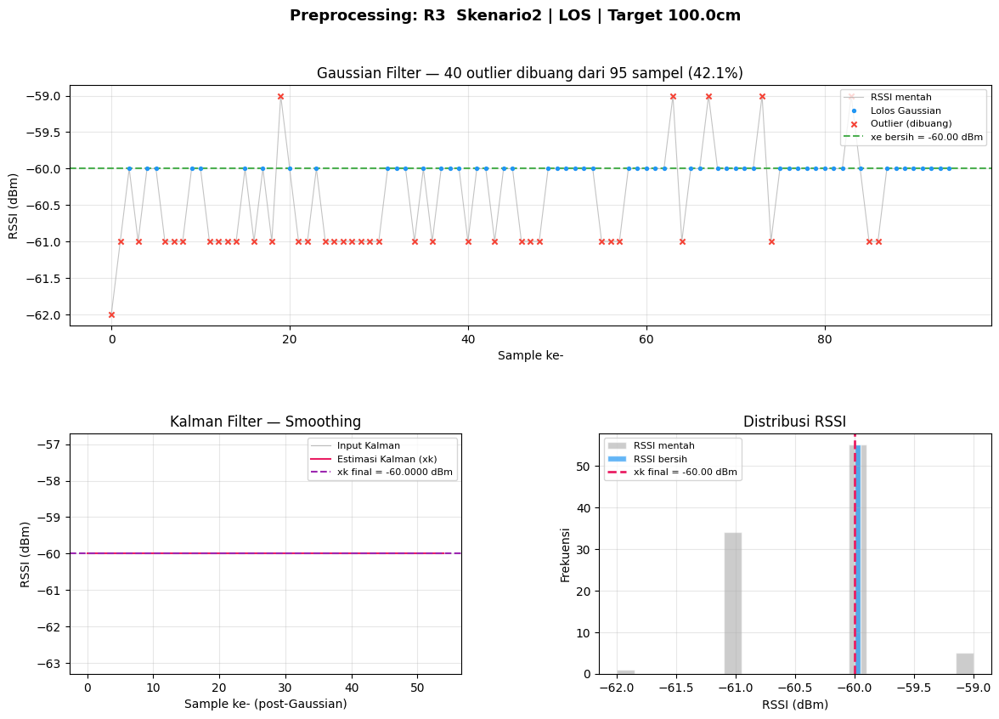

  ✅ Plot disimpan: preprocessing_R3_Skenario2__LOS__Target_100.0cm.png

📊 data_Skenario2_LOS_Target_110cm_20260511_131954.xlsx → Target


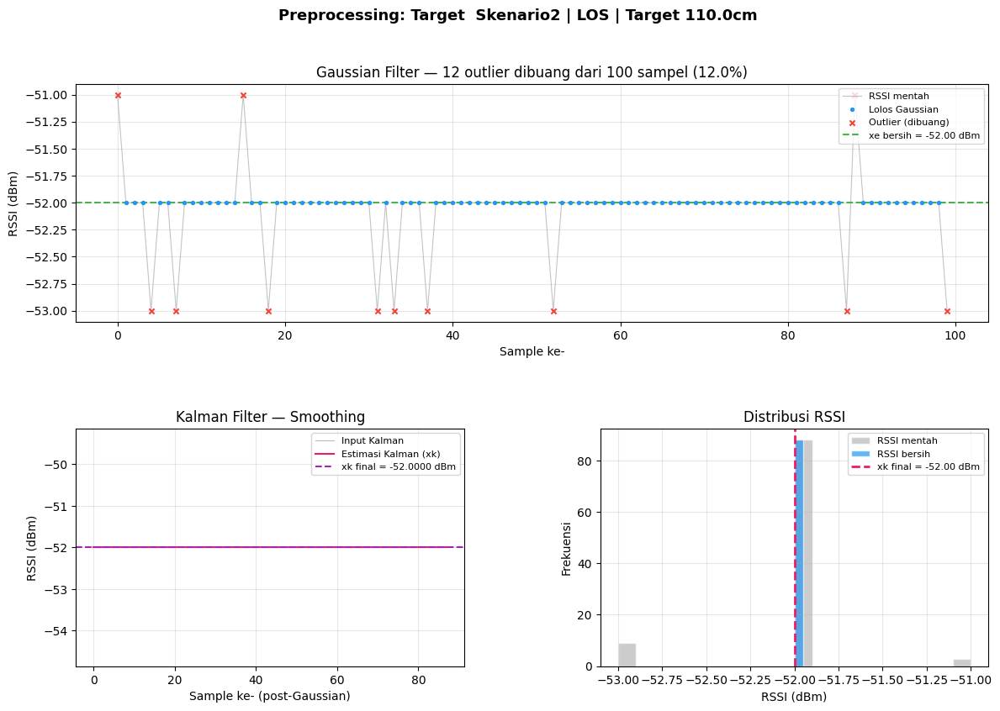

  ✅ Plot disimpan: preprocessing_Target_Skenario2__LOS__Target_110.0cm.png

📊 data_Skenario2_LOS_Target_110cm_20260511_131954.xlsx → R1


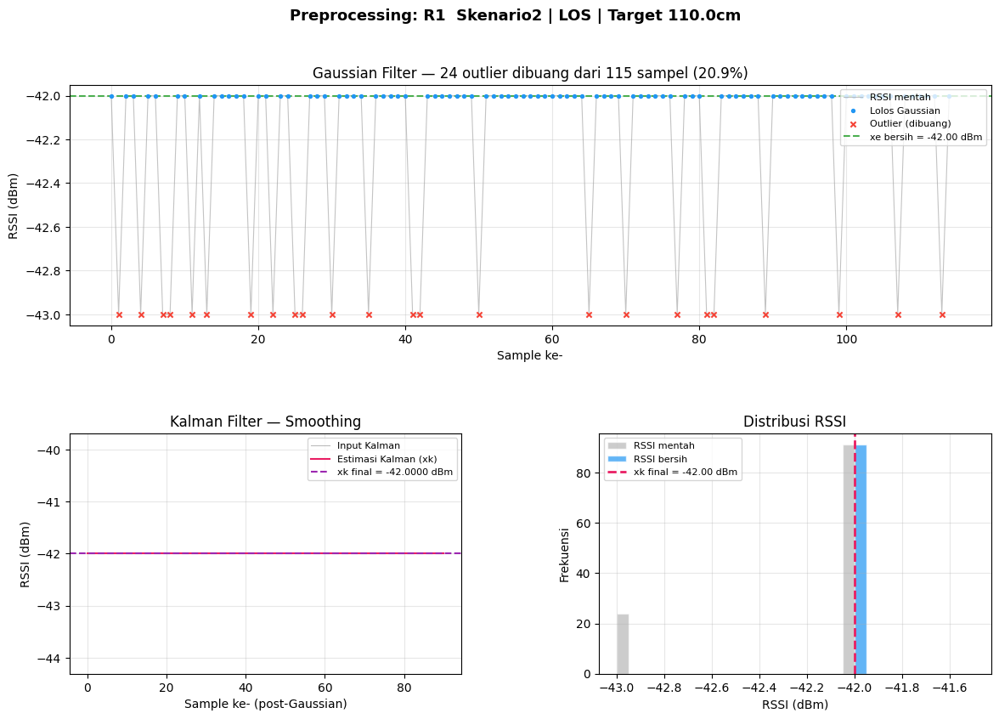

  ✅ Plot disimpan: preprocessing_R1_Skenario2__LOS__Target_110.0cm.png

📊 data_Skenario2_LOS_Target_110cm_20260511_131954.xlsx → R2


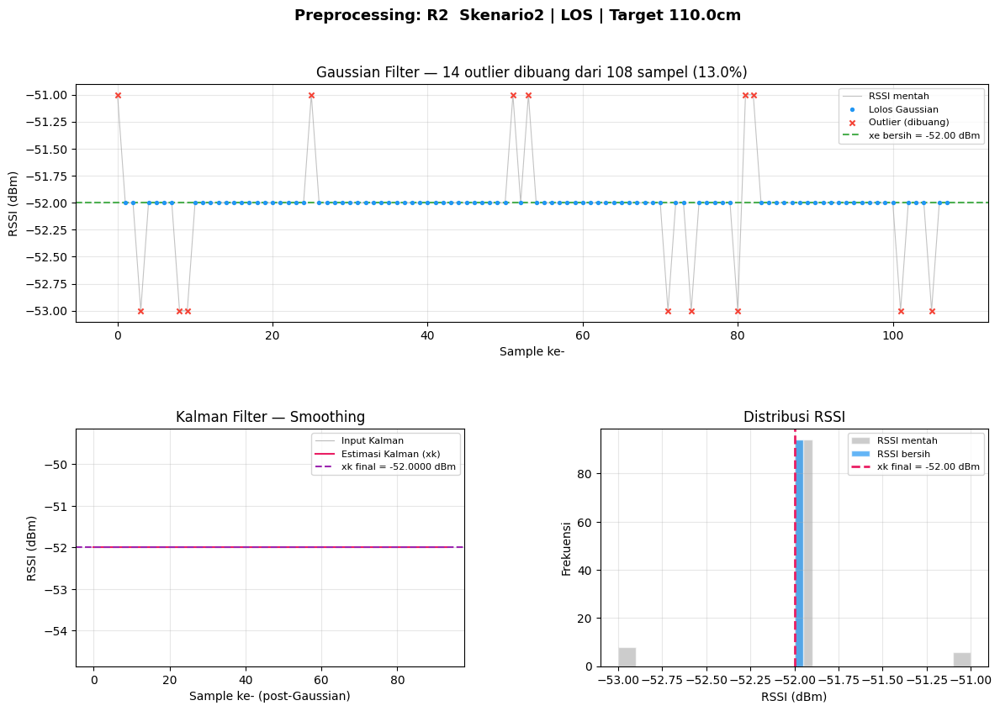

  ✅ Plot disimpan: preprocessing_R2_Skenario2__LOS__Target_110.0cm.png

📊 data_Skenario2_LOS_Target_110cm_20260511_131954.xlsx → R3


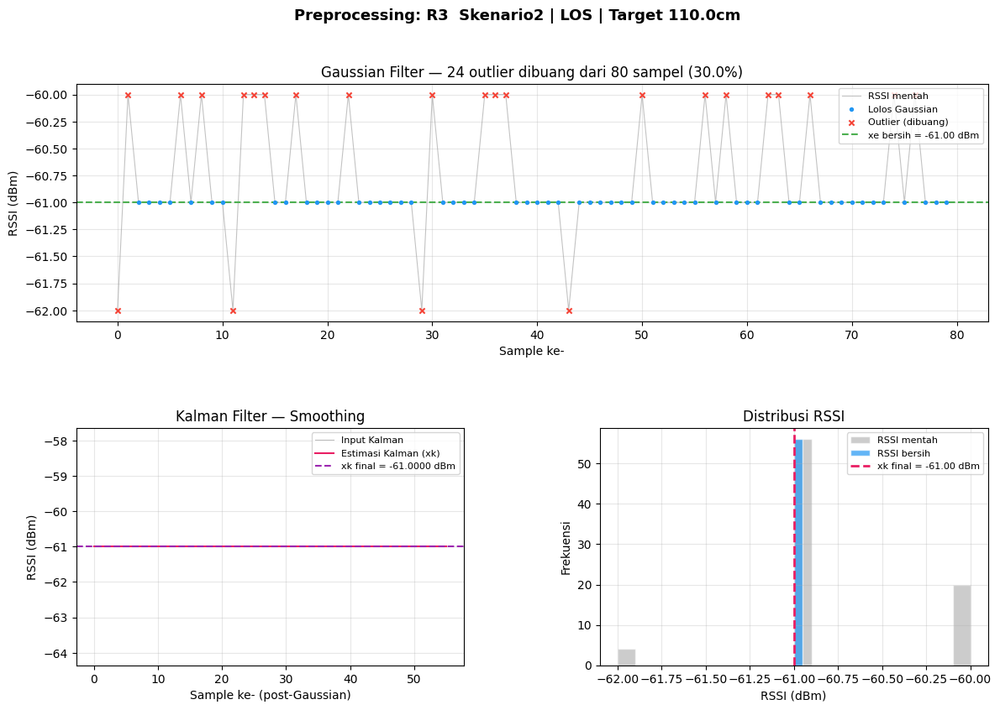

  ✅ Plot disimpan: preprocessing_R3_Skenario2__LOS__Target_110.0cm.png

📊 data_Skenario2_LOS_Target_140cm_20260511_125405.xlsx → Target


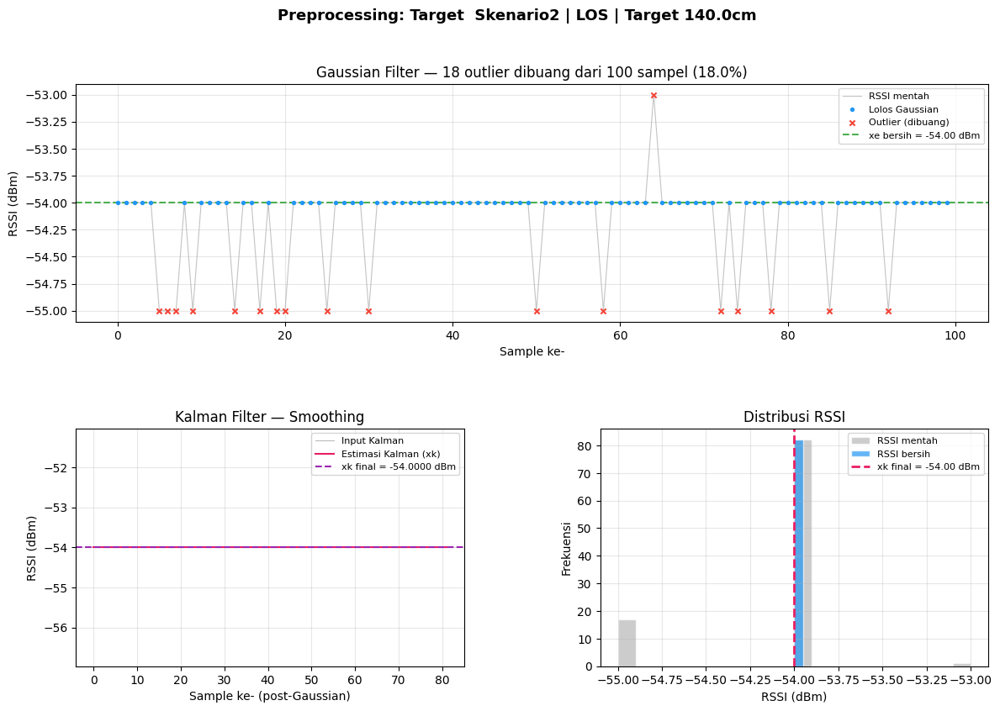

  ✅ Plot disimpan: preprocessing_Target_Skenario2__LOS__Target_140.0cm.png

📊 data_Skenario2_LOS_Target_140cm_20260511_125405.xlsx → R1


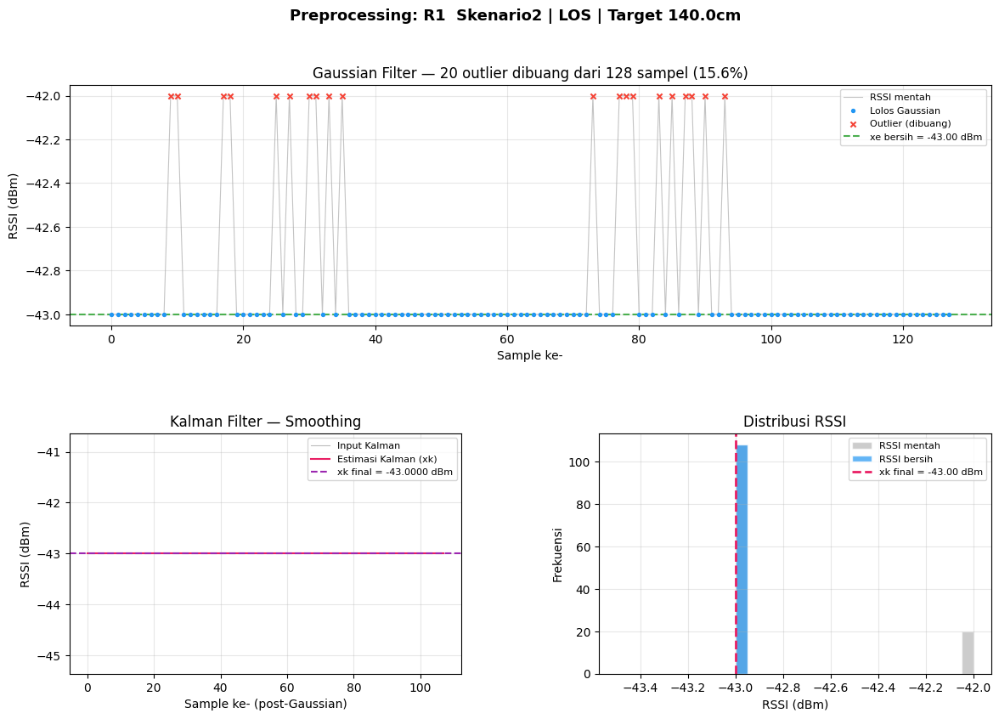

  ✅ Plot disimpan: preprocessing_R1_Skenario2__LOS__Target_140.0cm.png

📊 data_Skenario2_LOS_Target_140cm_20260511_125405.xlsx → R2


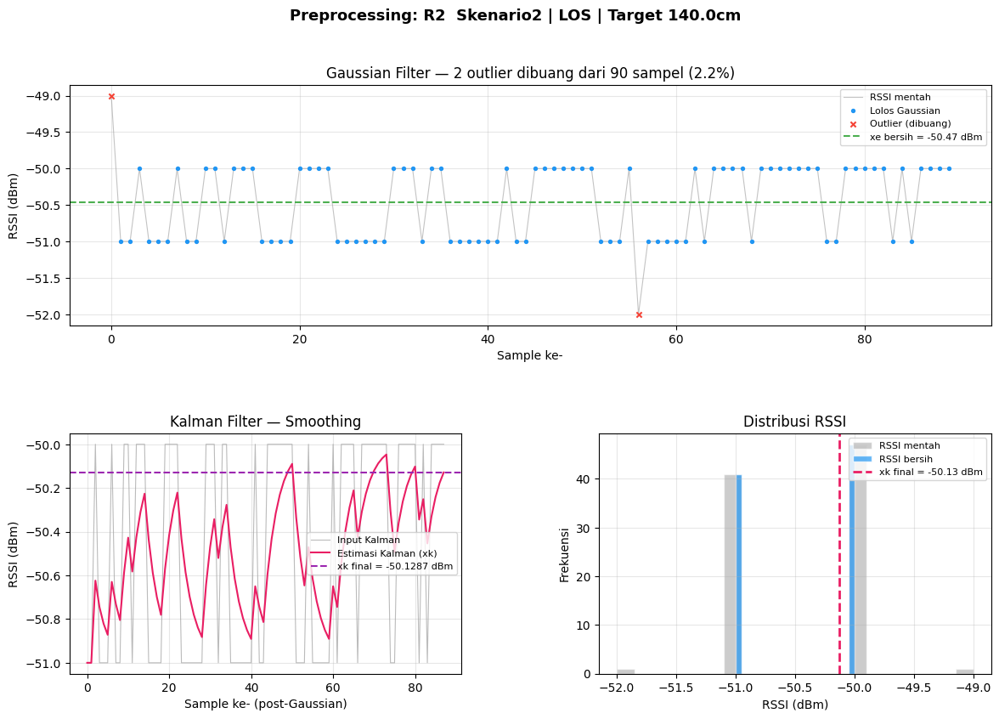

  ✅ Plot disimpan: preprocessing_R2_Skenario2__LOS__Target_140.0cm.png

📊 data_Skenario2_LOS_Target_140cm_20260511_125405.xlsx → R3


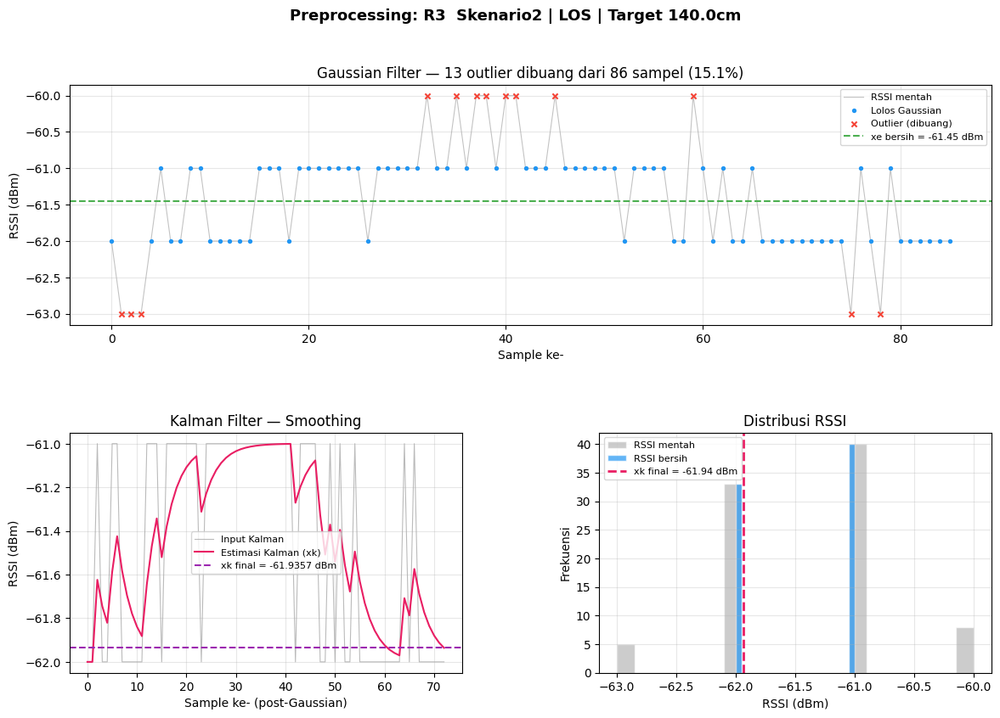

  ✅ Plot disimpan: preprocessing_R3_Skenario2__LOS__Target_140.0cm.png

📊 data_Skenario2_LOS_Target_170cm_20260511_130502.xlsx → Target


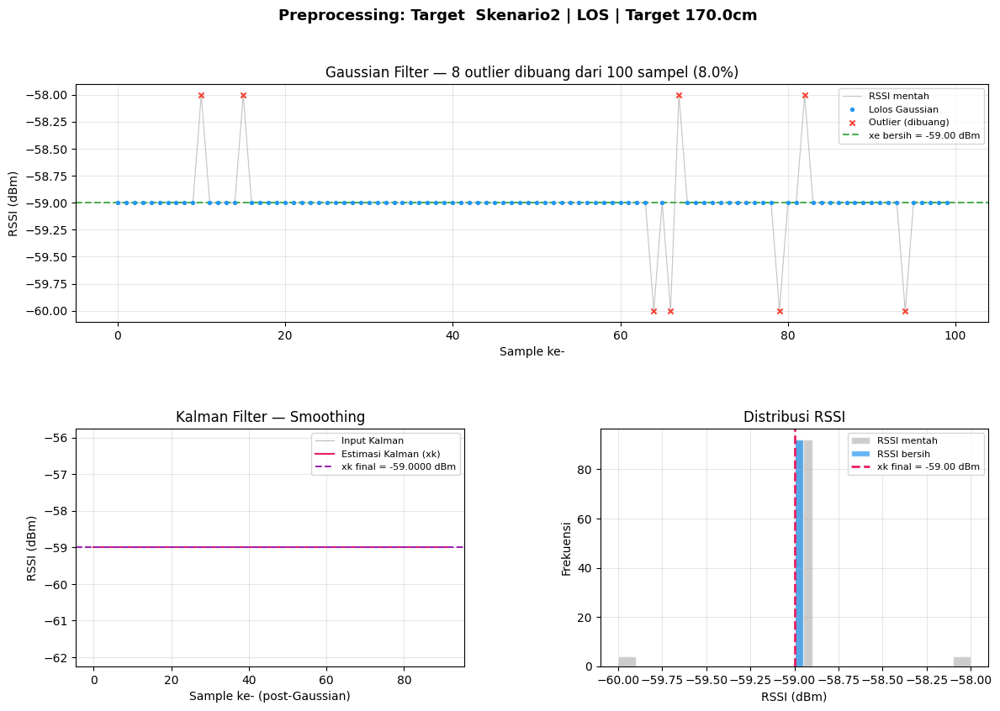

  ✅ Plot disimpan: preprocessing_Target_Skenario2__LOS__Target_170.0cm.png

📊 data_Skenario2_LOS_Target_170cm_20260511_130502.xlsx → R1


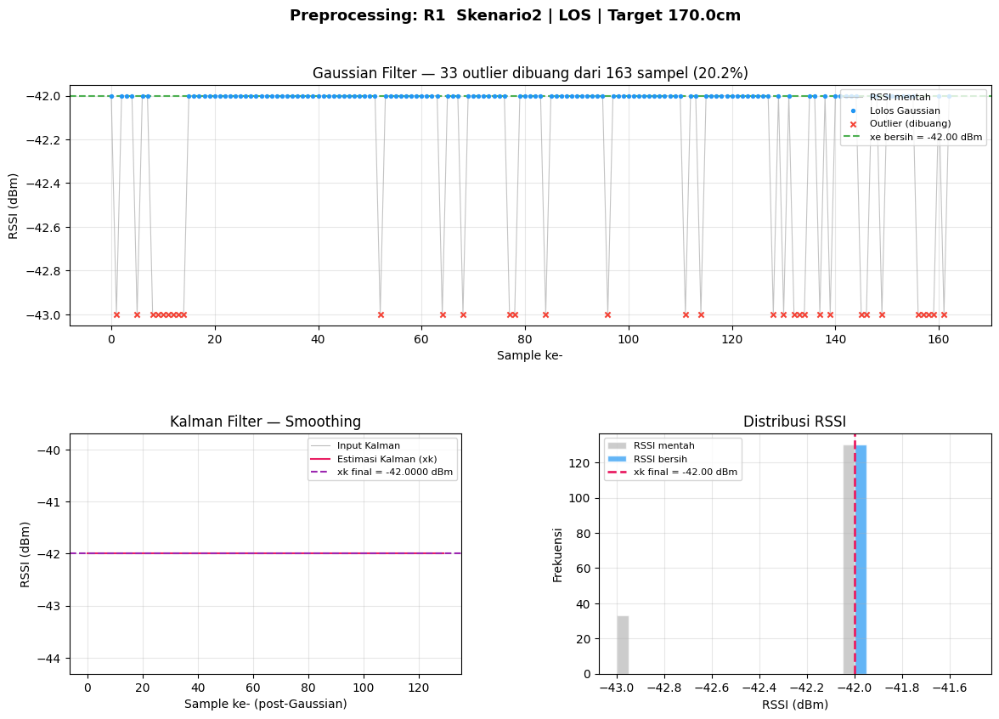

  ✅ Plot disimpan: preprocessing_R1_Skenario2__LOS__Target_170.0cm.png

📊 data_Skenario2_LOS_Target_170cm_20260511_130502.xlsx → R2


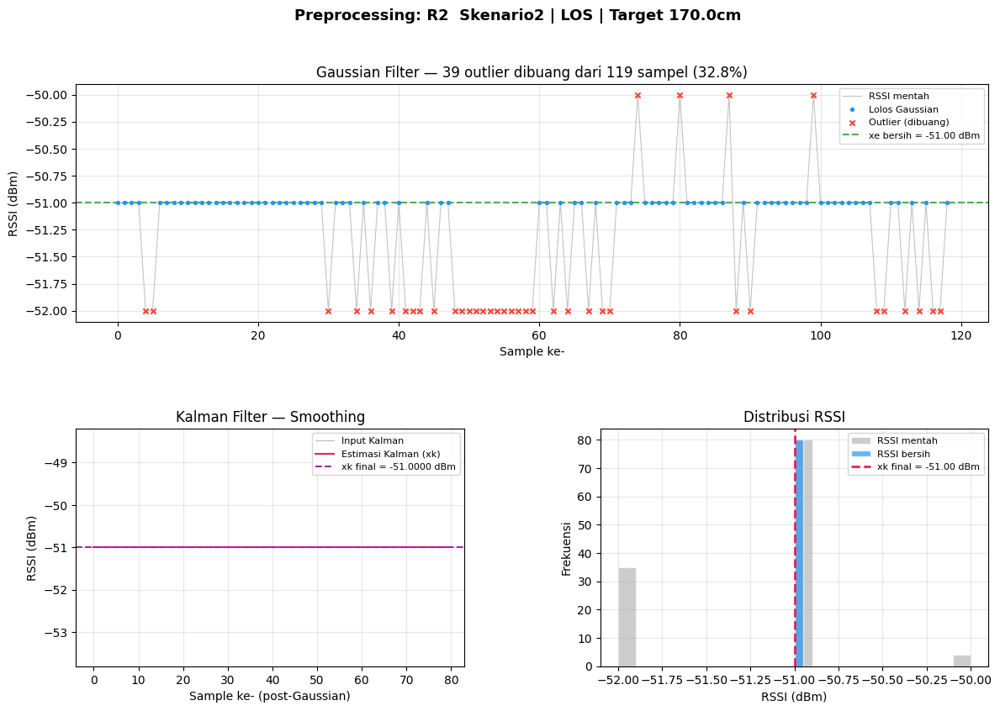

  ✅ Plot disimpan: preprocessing_R2_Skenario2__LOS__Target_170.0cm.png

📊 data_Skenario2_LOS_Target_170cm_20260511_130502.xlsx → R3


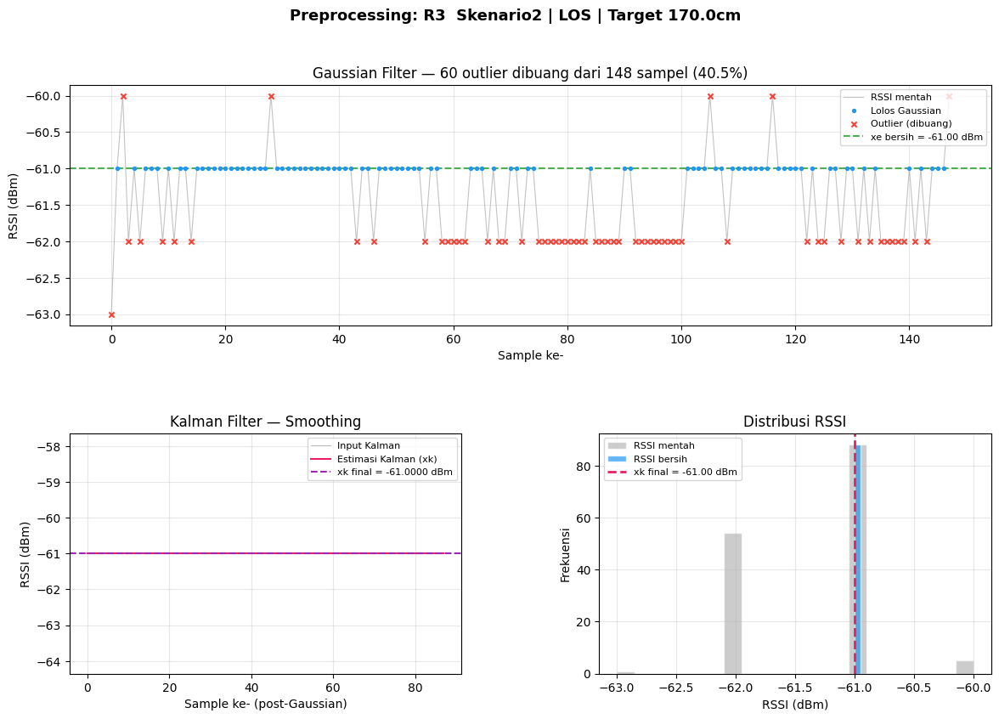

  ✅ Plot disimpan: preprocessing_R3_Skenario2__LOS__Target_170.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_80cm_20260511_012539.xlsx → Target


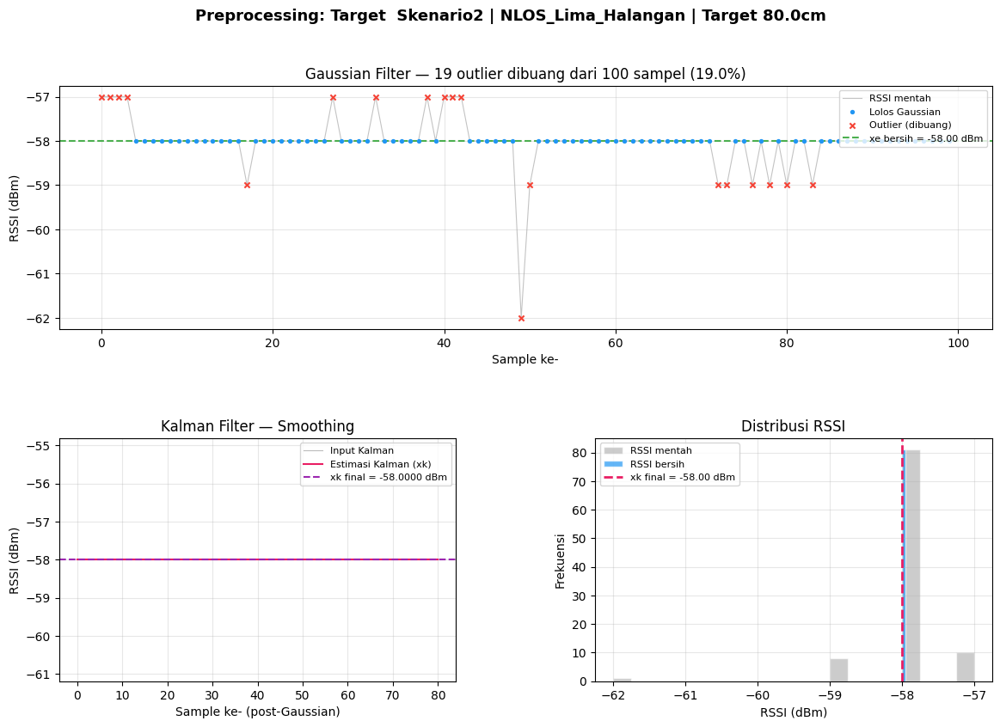

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Lima_Halangan__Target_80.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_80cm_20260511_012539.xlsx → R1


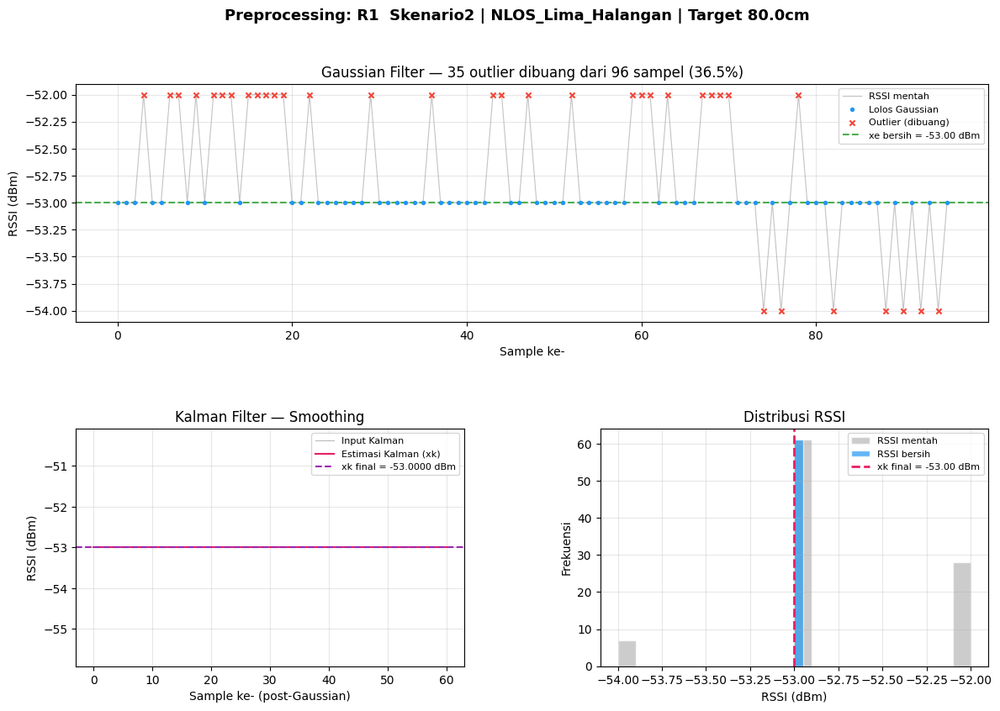

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Lima_Halangan__Target_80.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_80cm_20260511_012539.xlsx → R2


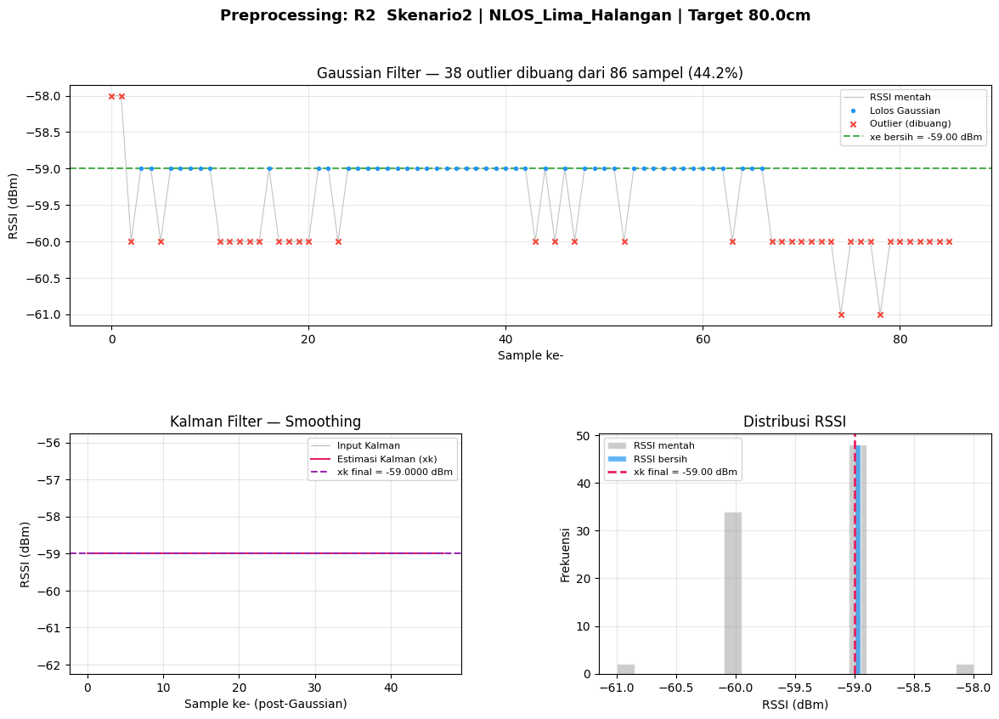

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Lima_Halangan__Target_80.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_80cm_20260511_012539.xlsx → R3


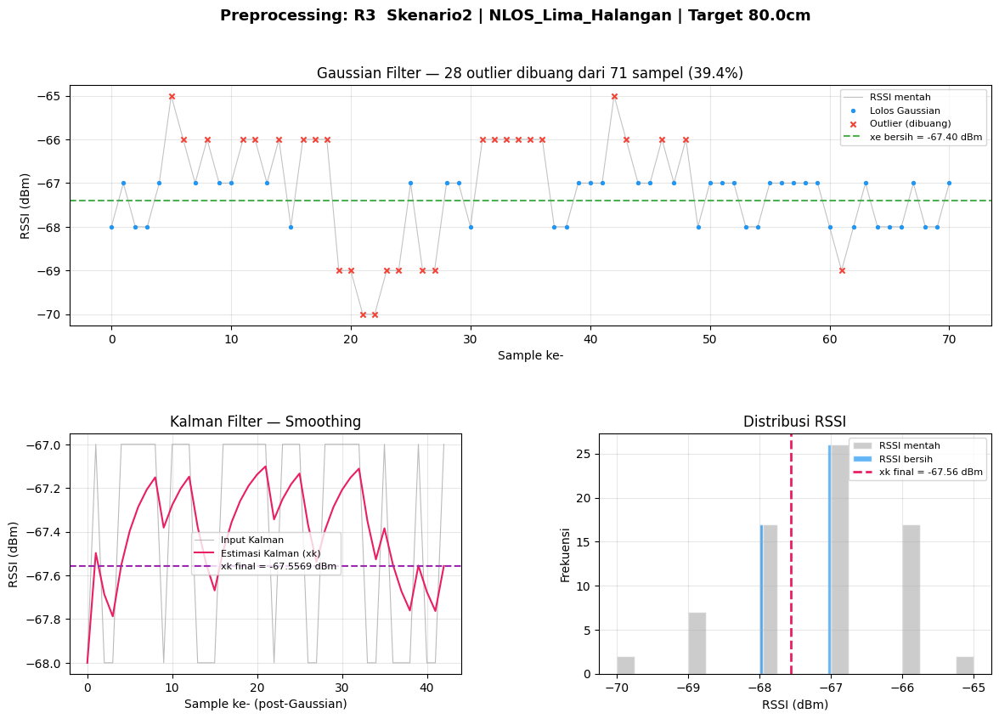

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Lima_Halangan__Target_80.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_90cm_20260511_015751.xlsx → Target


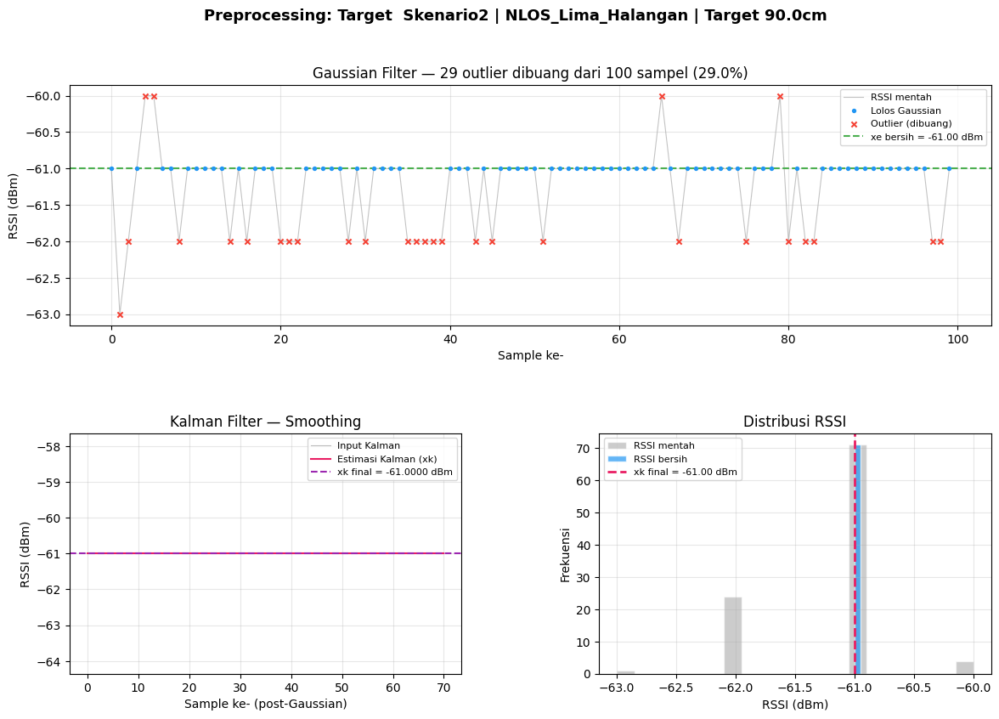

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Lima_Halangan__Target_90.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_90cm_20260511_015751.xlsx → R1


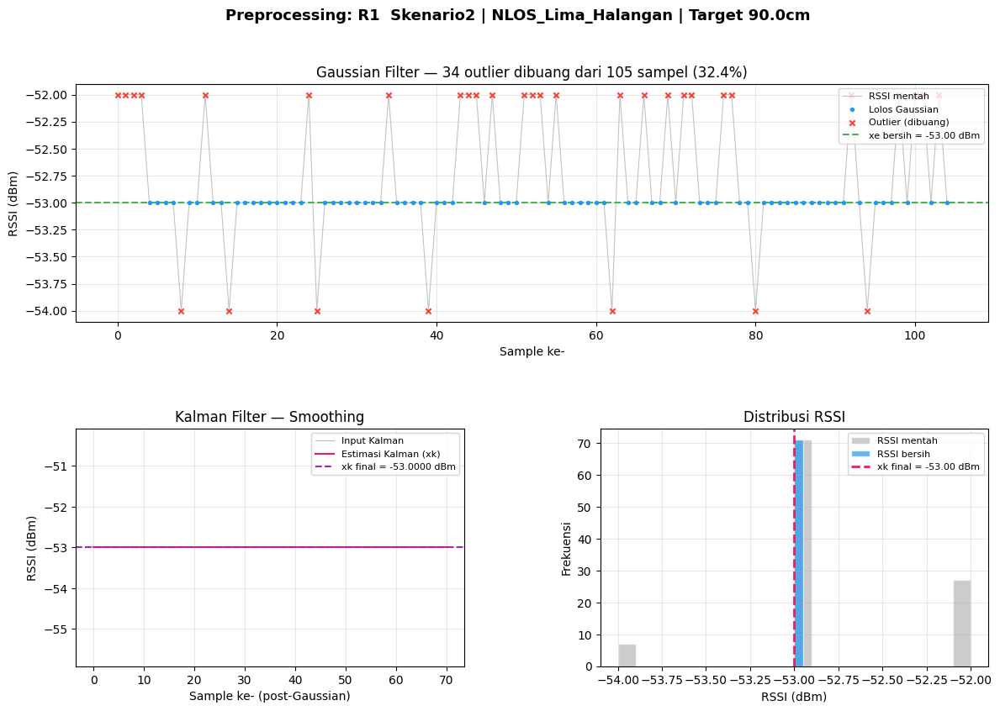

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Lima_Halangan__Target_90.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_90cm_20260511_015751.xlsx → R2


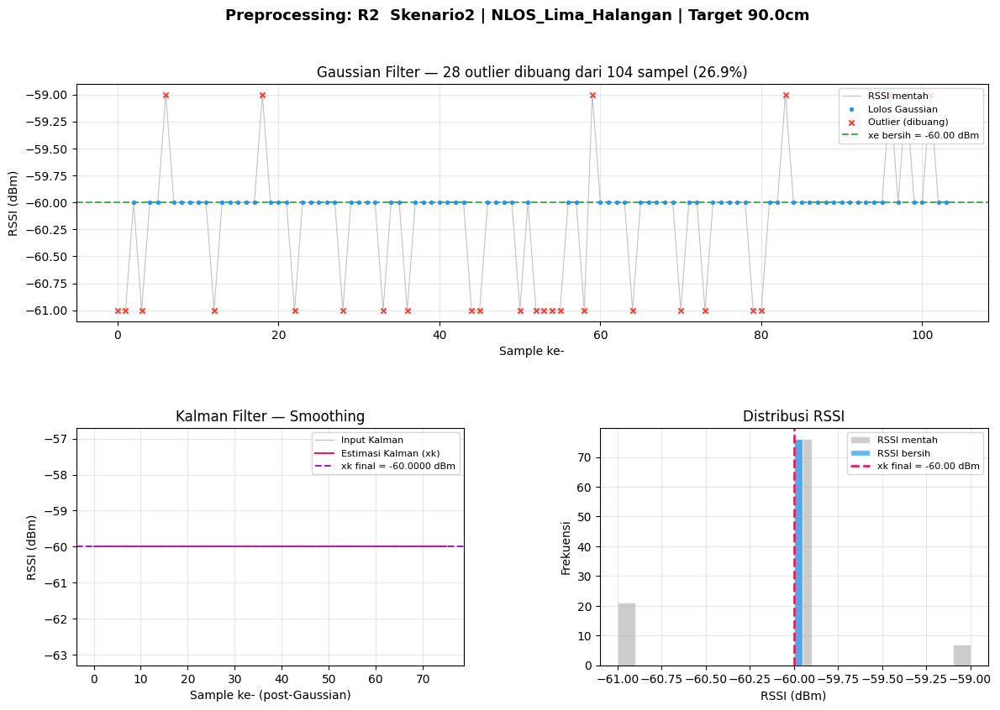

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Lima_Halangan__Target_90.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_90cm_20260511_015751.xlsx → R3


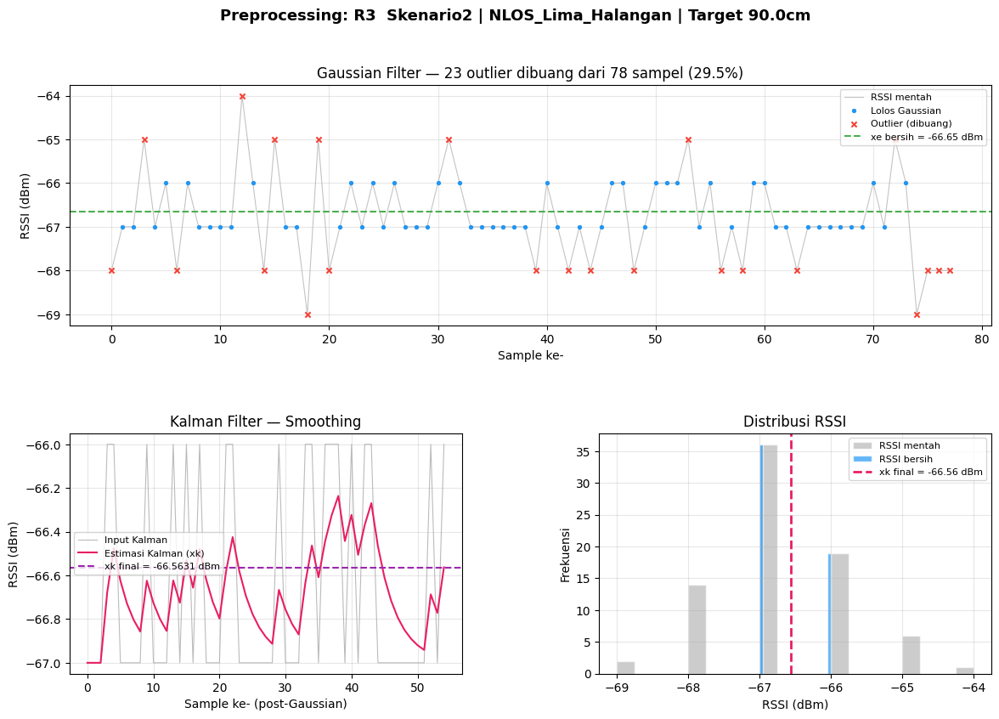

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Lima_Halangan__Target_90.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_100cm_20260511_013438.xlsx → Target


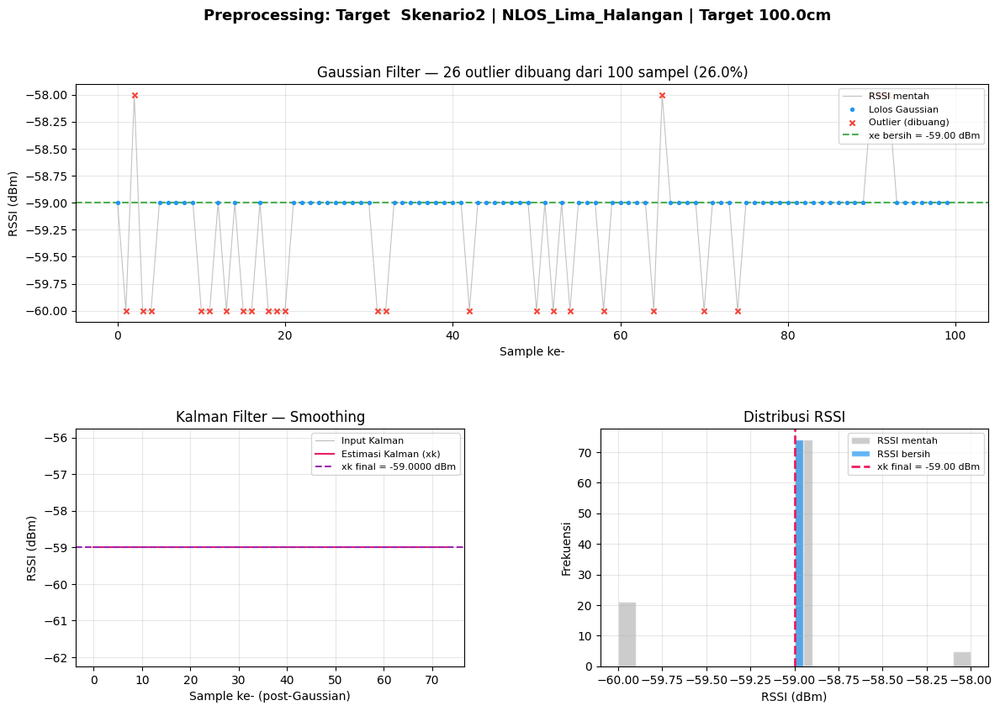

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Lima_Halangan__Target_100.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_100cm_20260511_013438.xlsx → R1


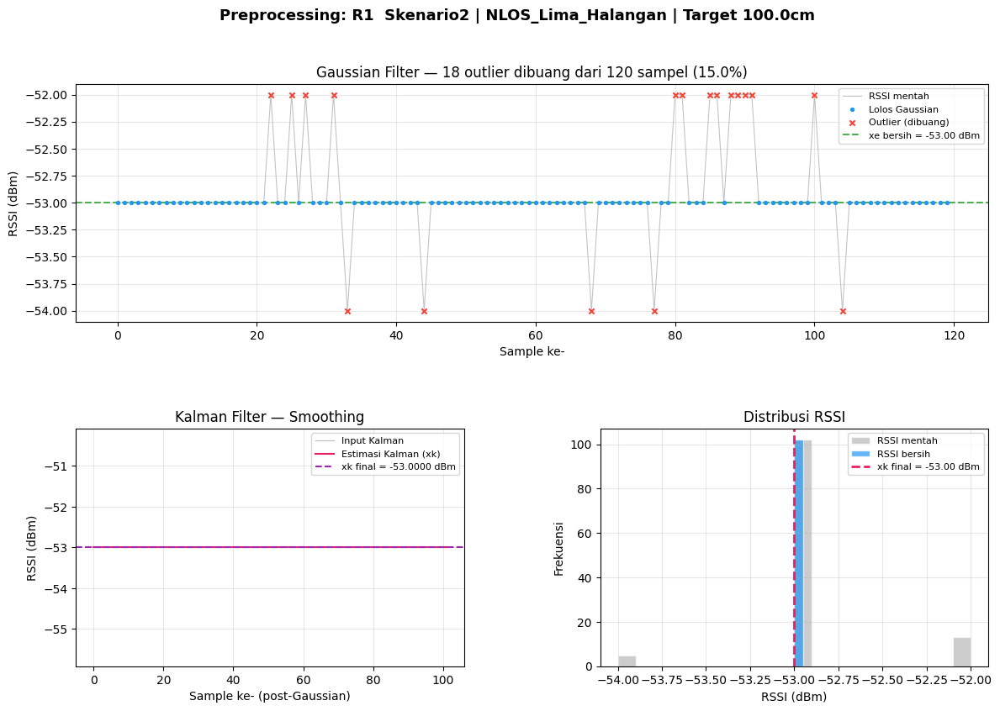

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Lima_Halangan__Target_100.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_100cm_20260511_013438.xlsx → R2


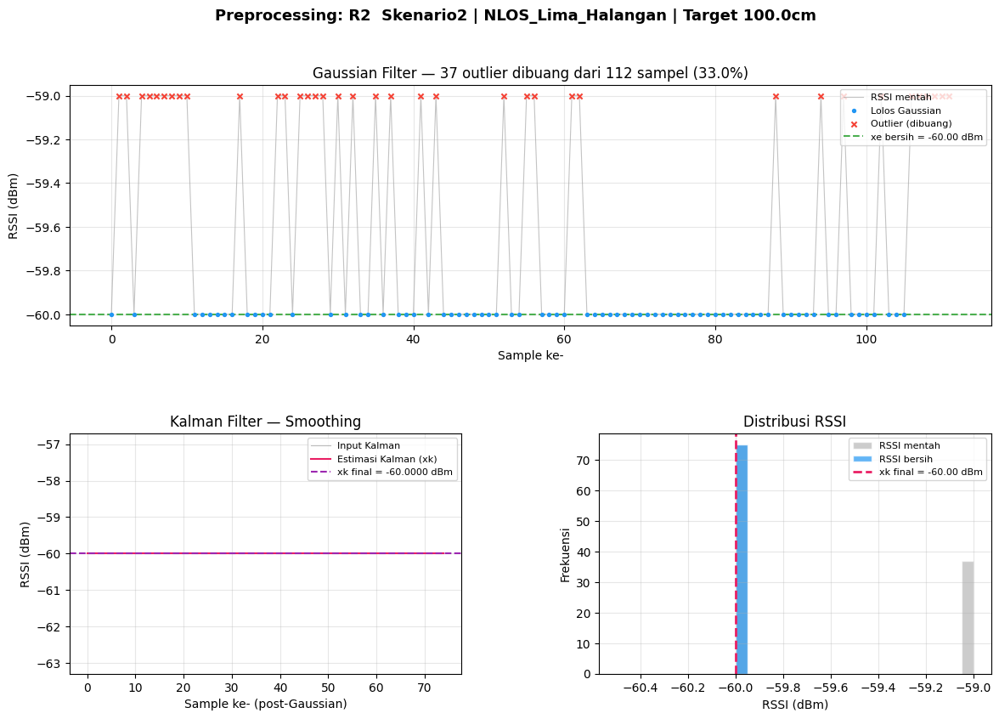

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Lima_Halangan__Target_100.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_100cm_20260511_013438.xlsx → R3


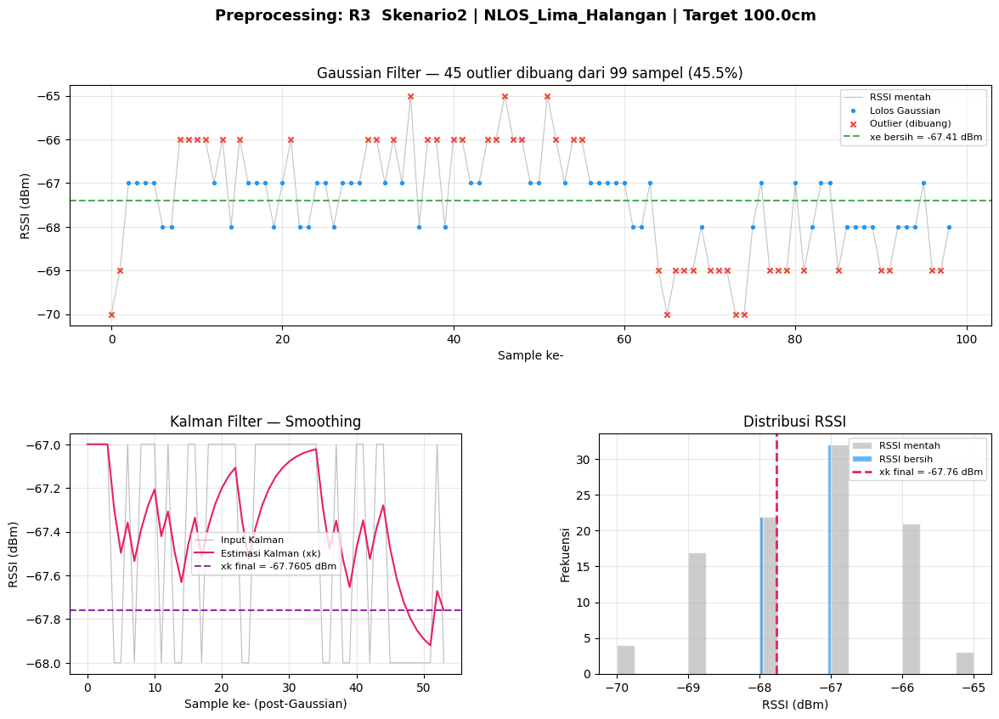

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Lima_Halangan__Target_100.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_110cm_20260511_020503.xlsx → Target


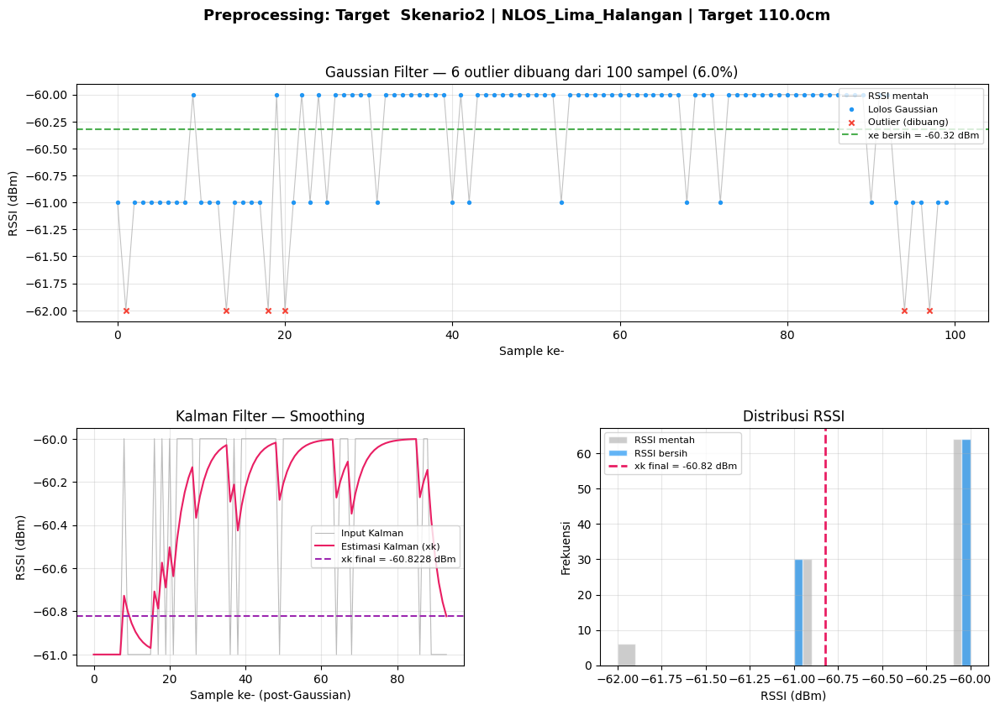

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Lima_Halangan__Target_110.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_110cm_20260511_020503.xlsx → R1


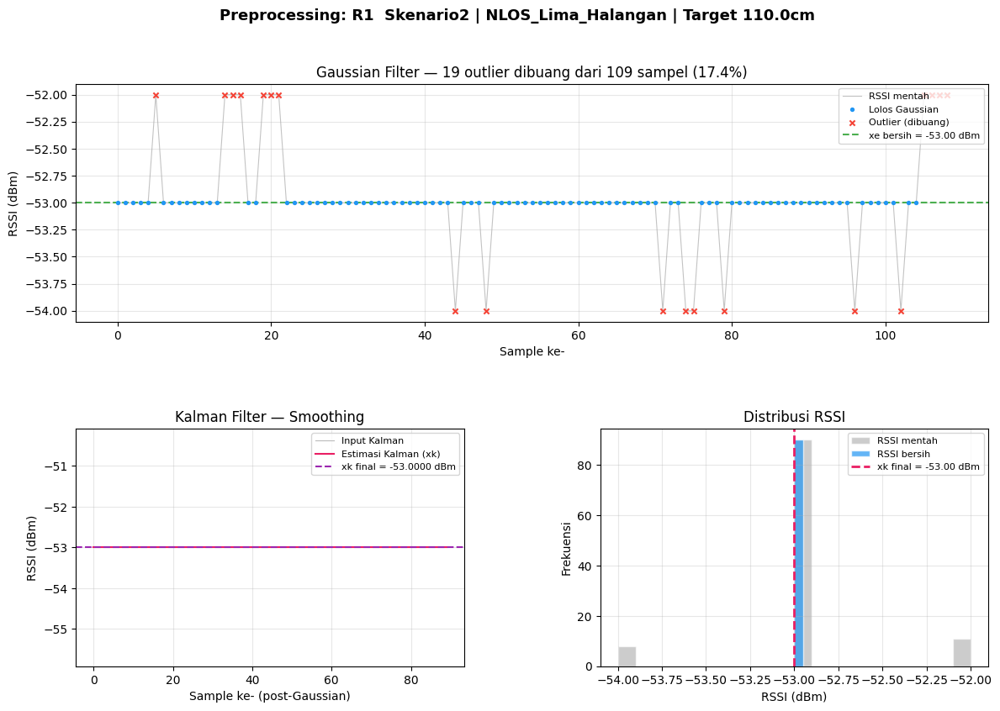

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Lima_Halangan__Target_110.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_110cm_20260511_020503.xlsx → R2


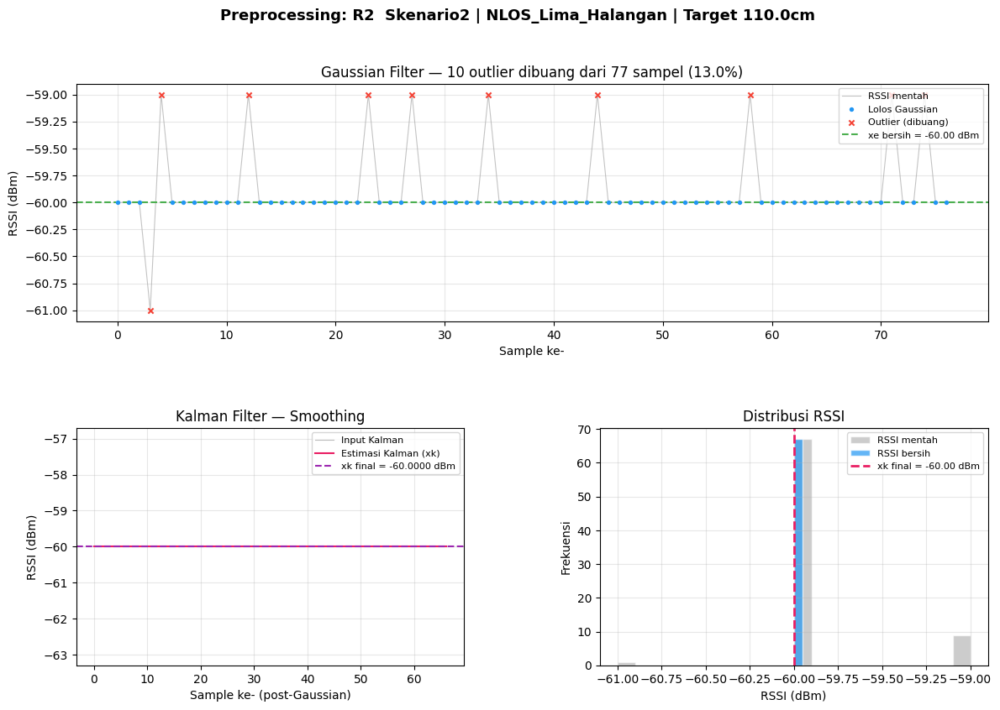

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Lima_Halangan__Target_110.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_110cm_20260511_020503.xlsx → R3


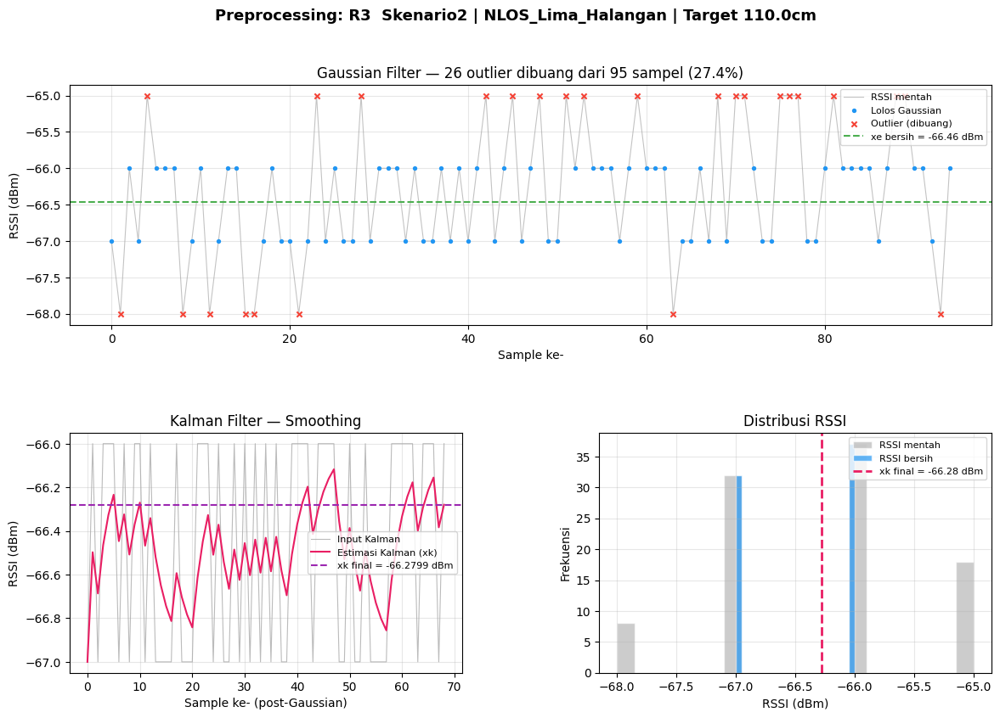

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Lima_Halangan__Target_110.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_140cm_20260511_014331.xlsx → Target


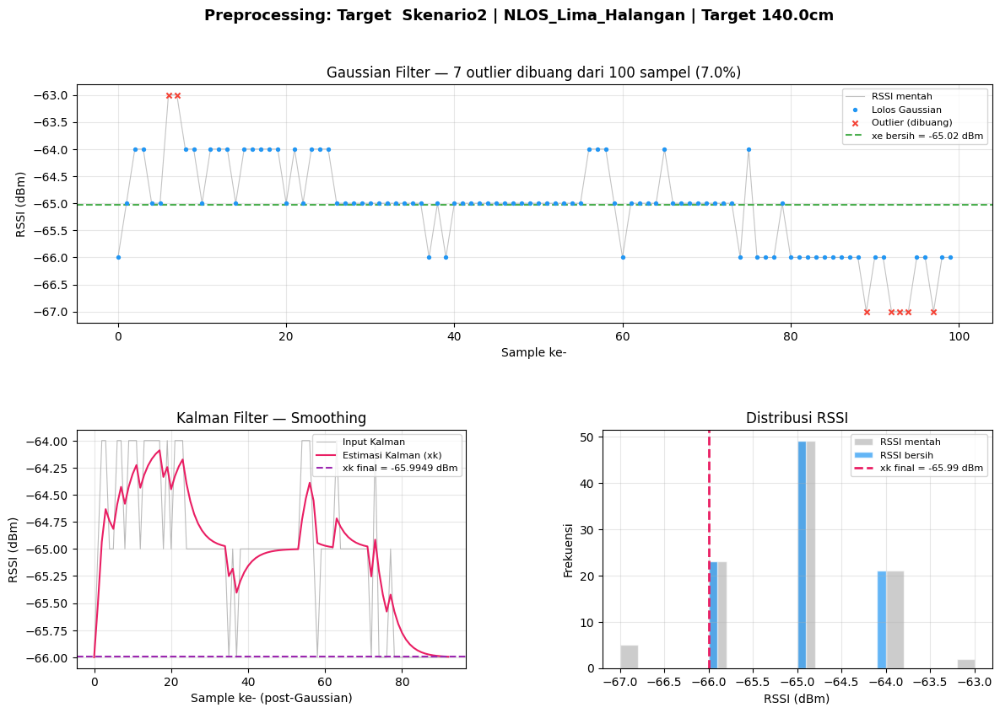

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Lima_Halangan__Target_140.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_140cm_20260511_014331.xlsx → R1


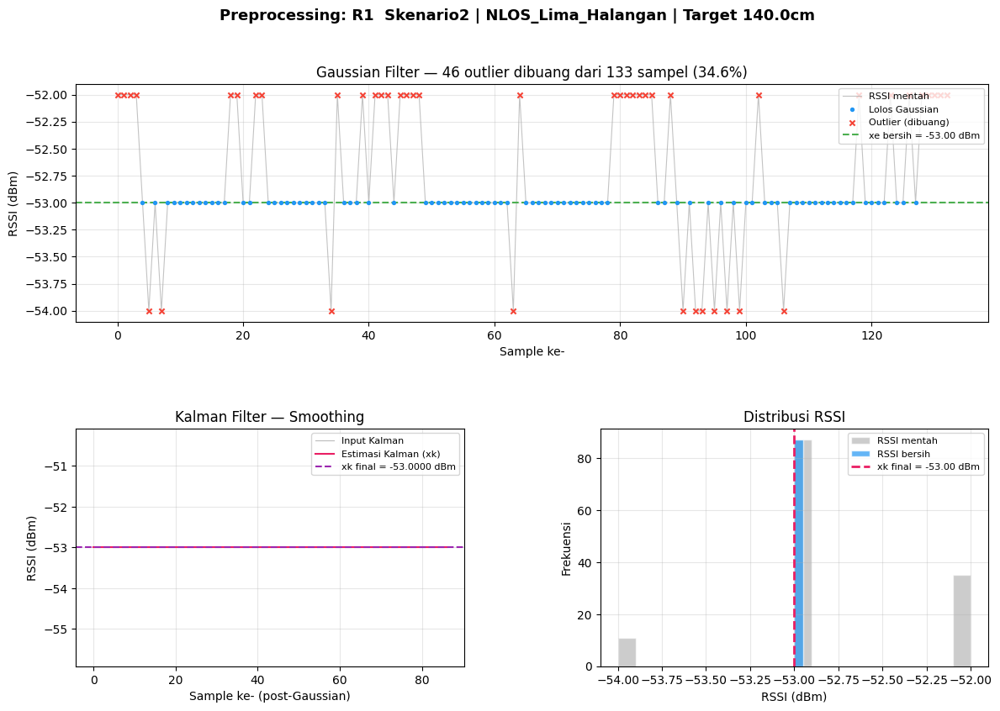

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Lima_Halangan__Target_140.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_140cm_20260511_014331.xlsx → R2


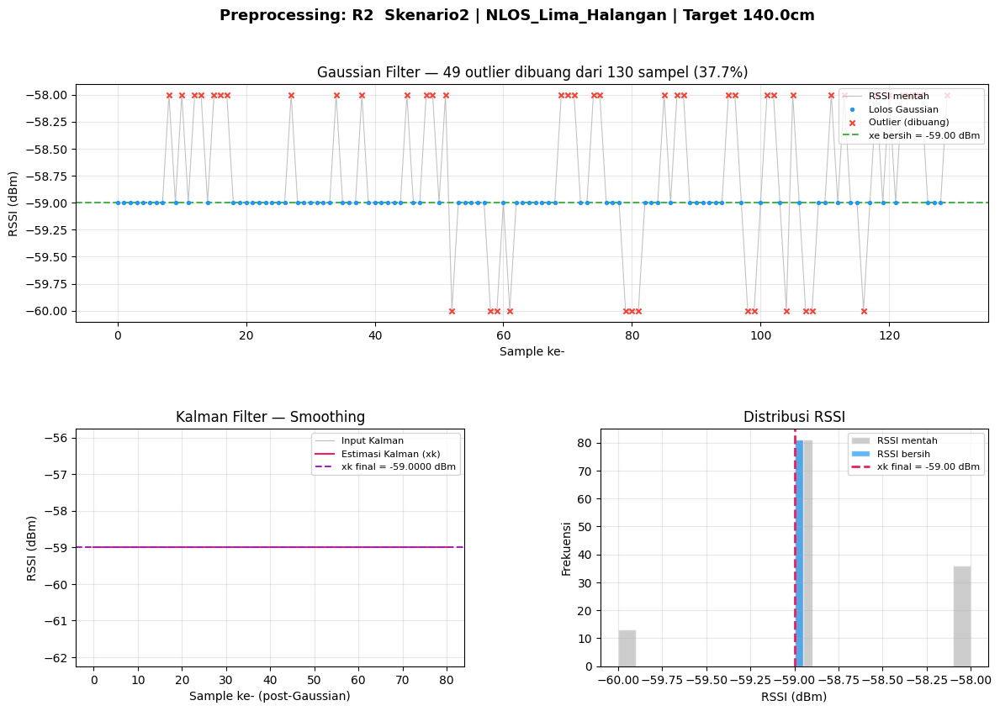

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Lima_Halangan__Target_140.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_140cm_20260511_014331.xlsx → R3


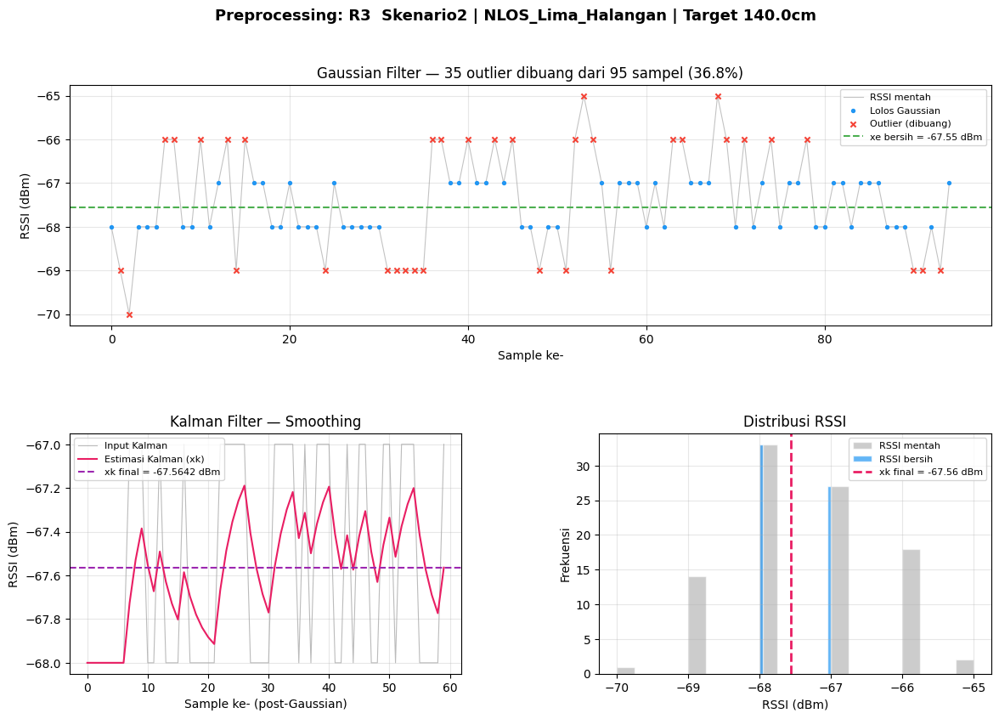

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Lima_Halangan__Target_140.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_170cm_20260511_015044.xlsx → Target


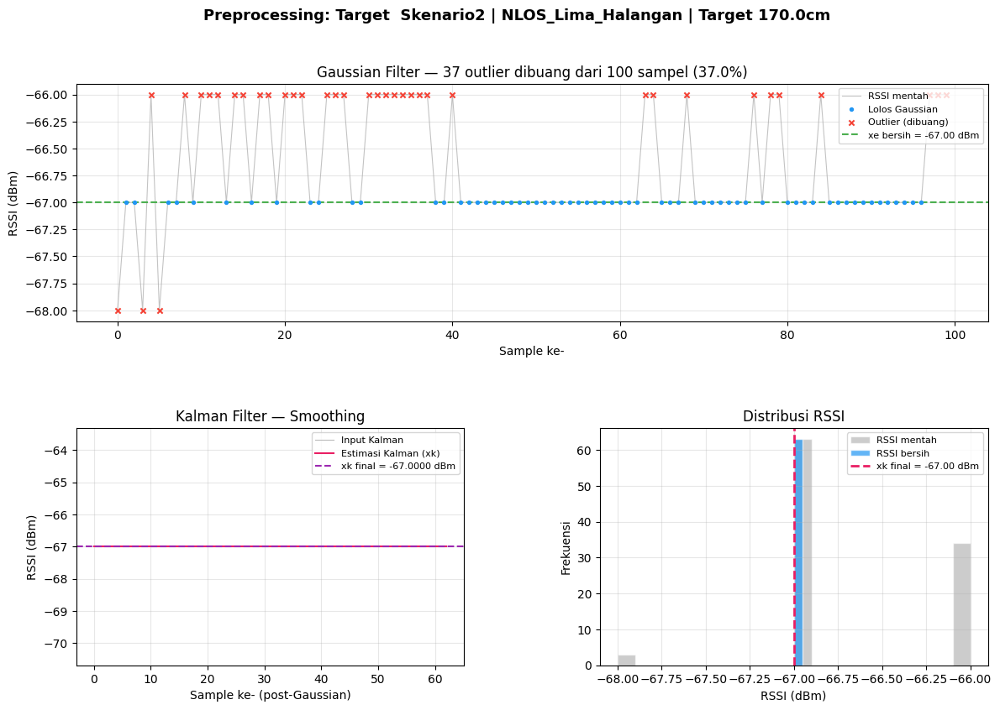

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Lima_Halangan__Target_170.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_170cm_20260511_015044.xlsx → R1


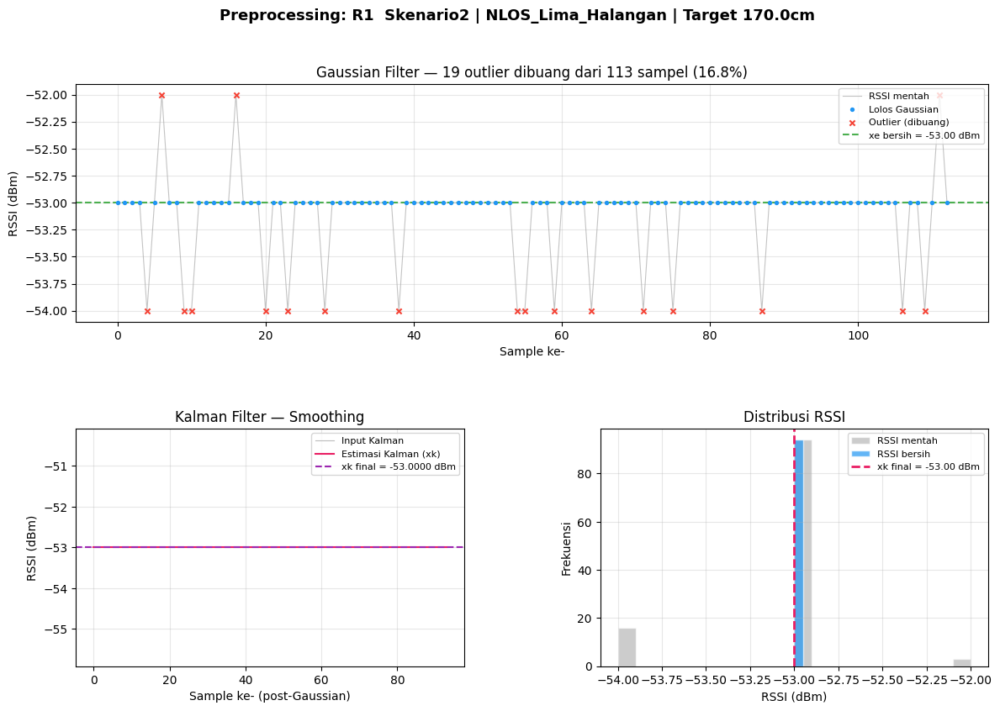

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Lima_Halangan__Target_170.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_170cm_20260511_015044.xlsx → R2


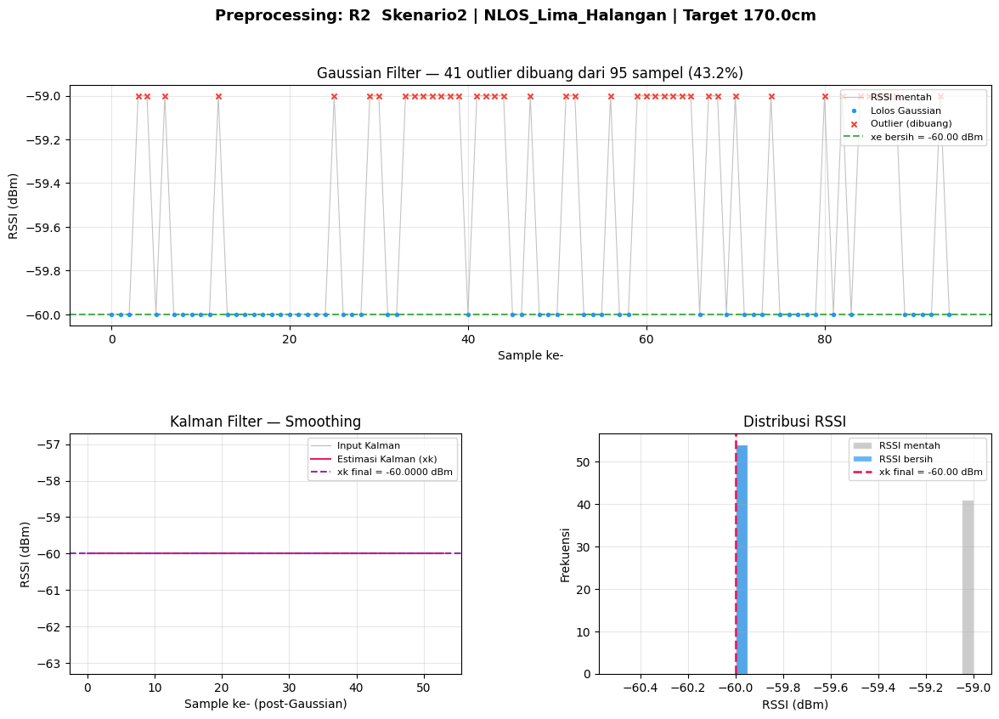

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Lima_Halangan__Target_170.0cm.png

📊 data_Skenario2_NLOS_Banyak_Target_170cm_20260511_015044.xlsx → R3


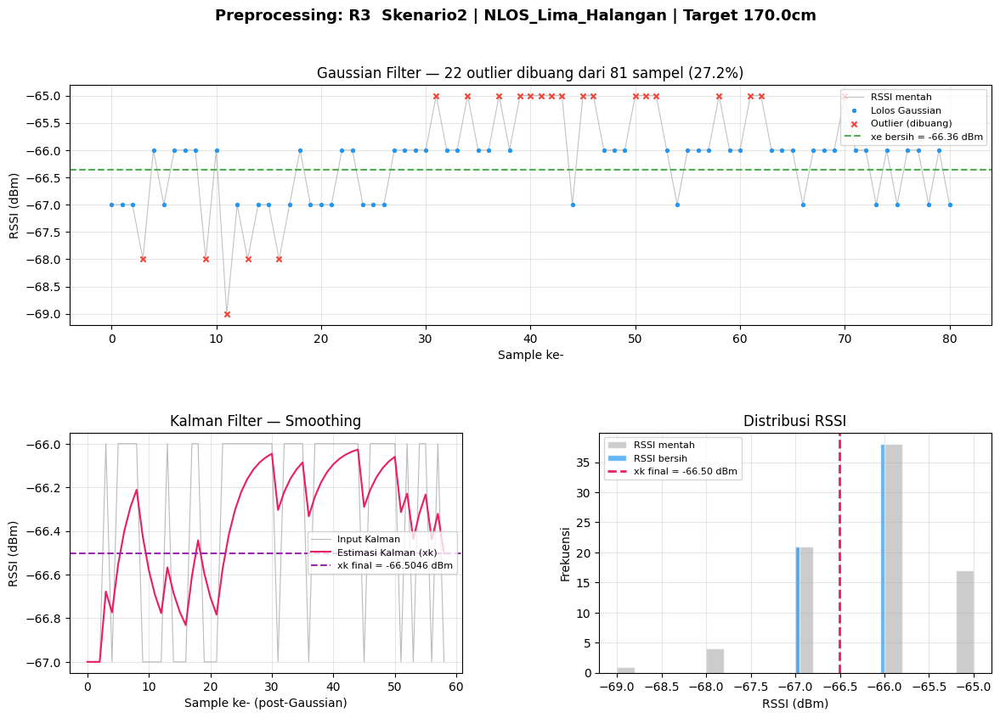

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Lima_Halangan__Target_170.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_80cm_20260511_022739.xlsx → Target


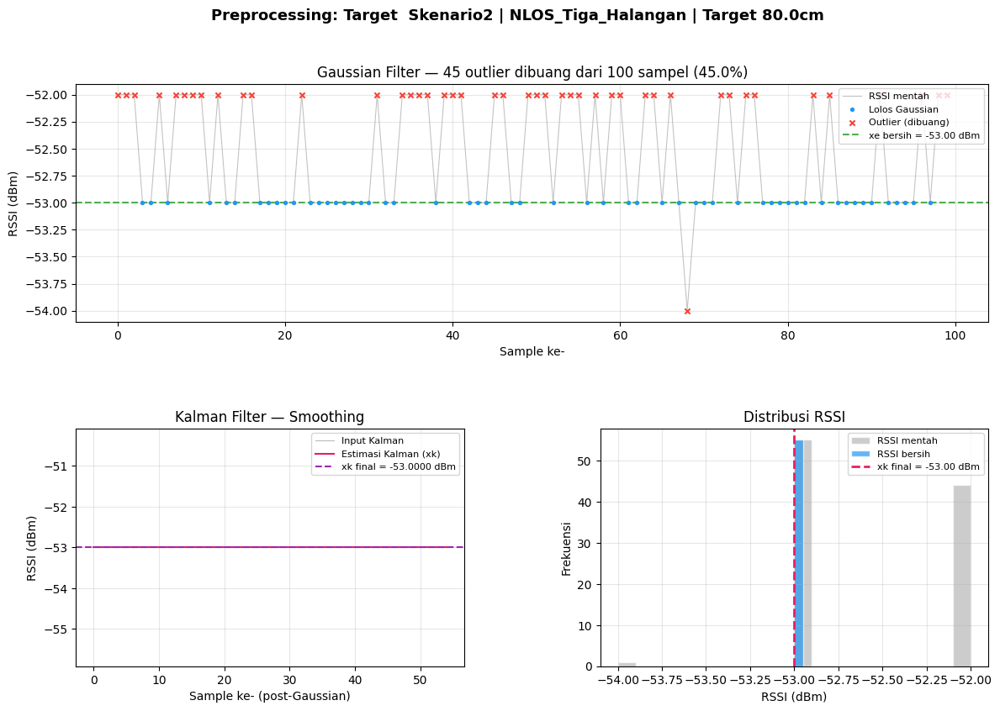

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Tiga_Halangan__Target_80.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_80cm_20260511_022739.xlsx → R1


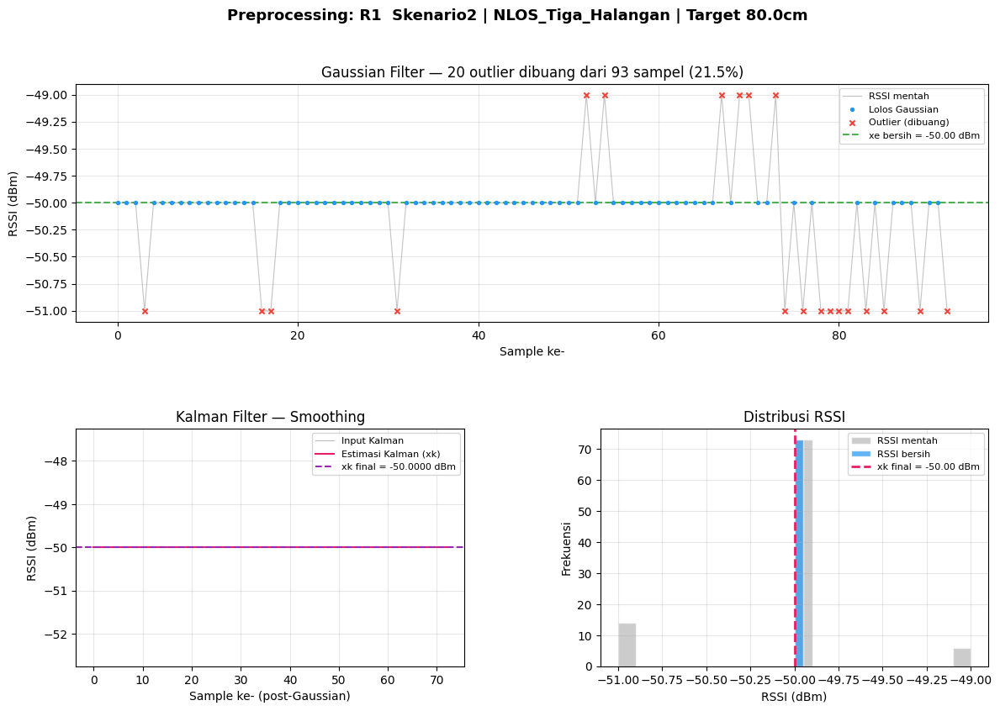

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Tiga_Halangan__Target_80.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_80cm_20260511_022739.xlsx → R2


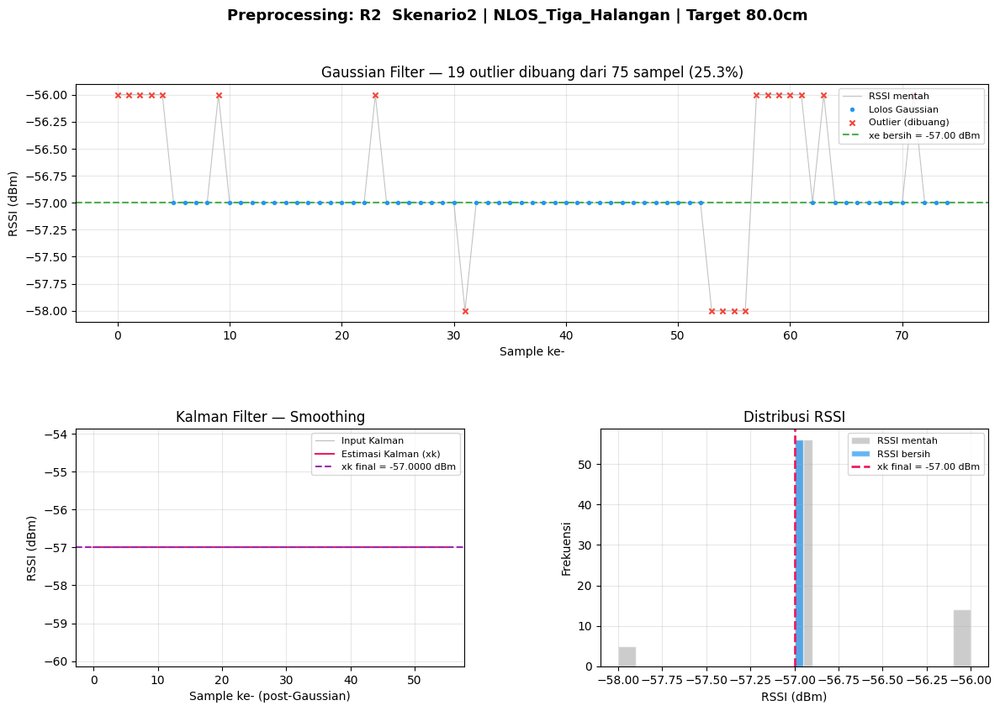

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Tiga_Halangan__Target_80.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_80cm_20260511_022739.xlsx → R3


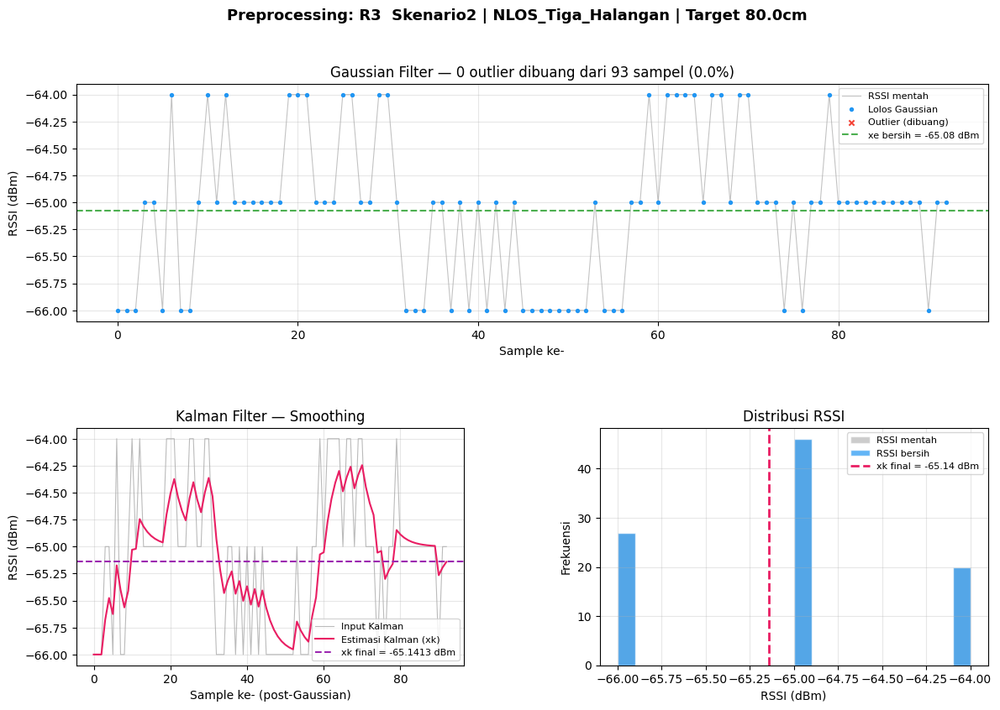

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Tiga_Halangan__Target_80.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_90cm_20260511_111045.xlsx → Target


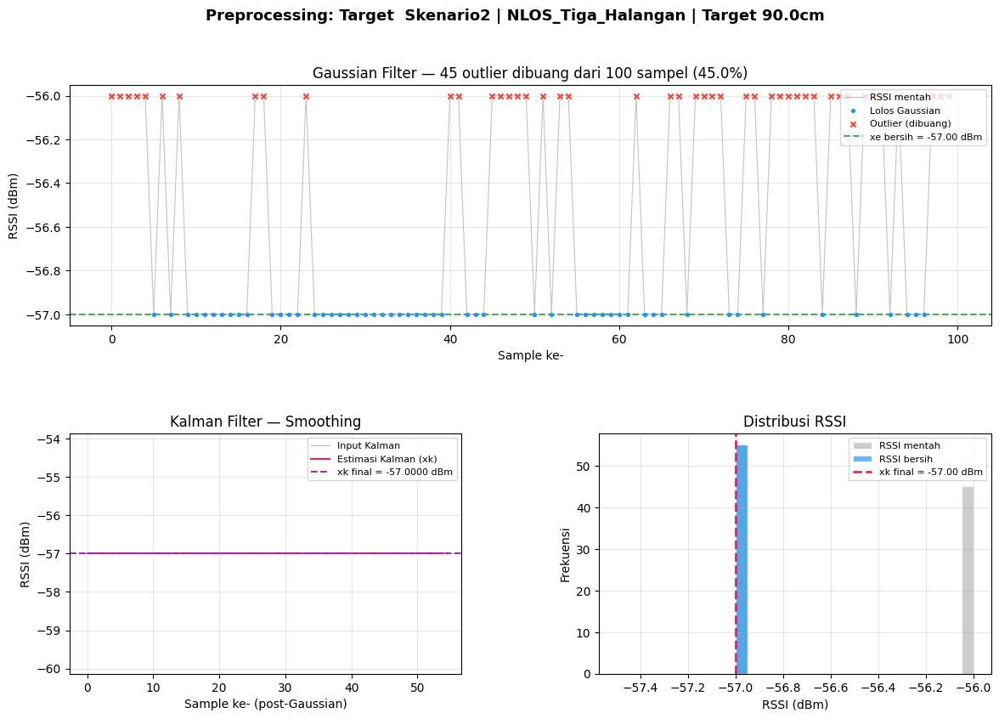

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Tiga_Halangan__Target_90.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_90cm_20260511_111045.xlsx → R1


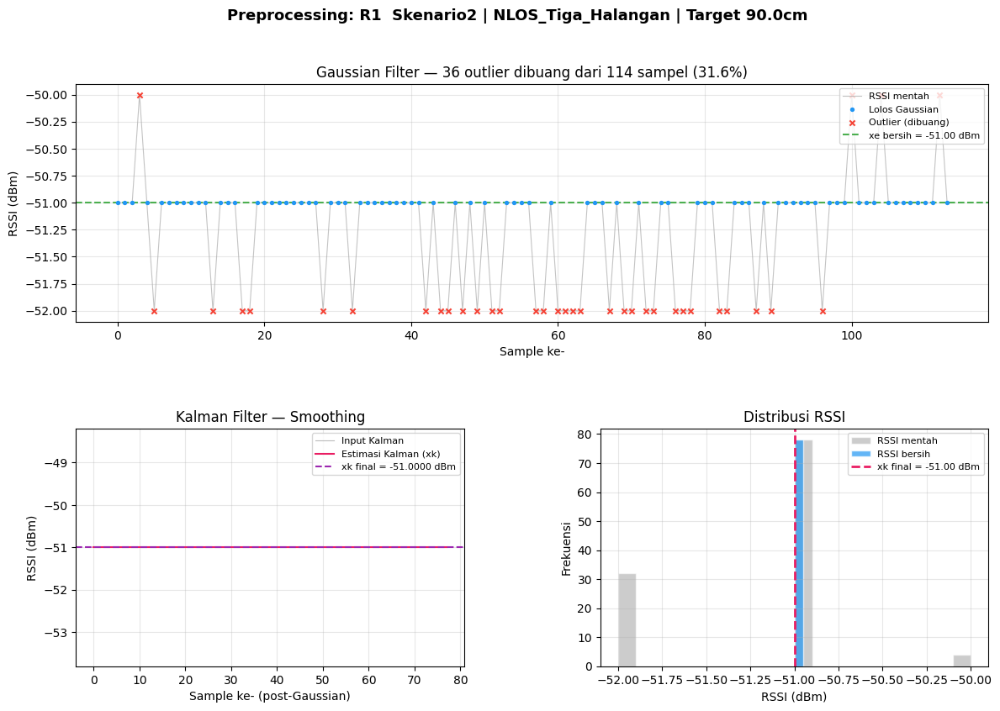

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Tiga_Halangan__Target_90.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_90cm_20260511_111045.xlsx → R2


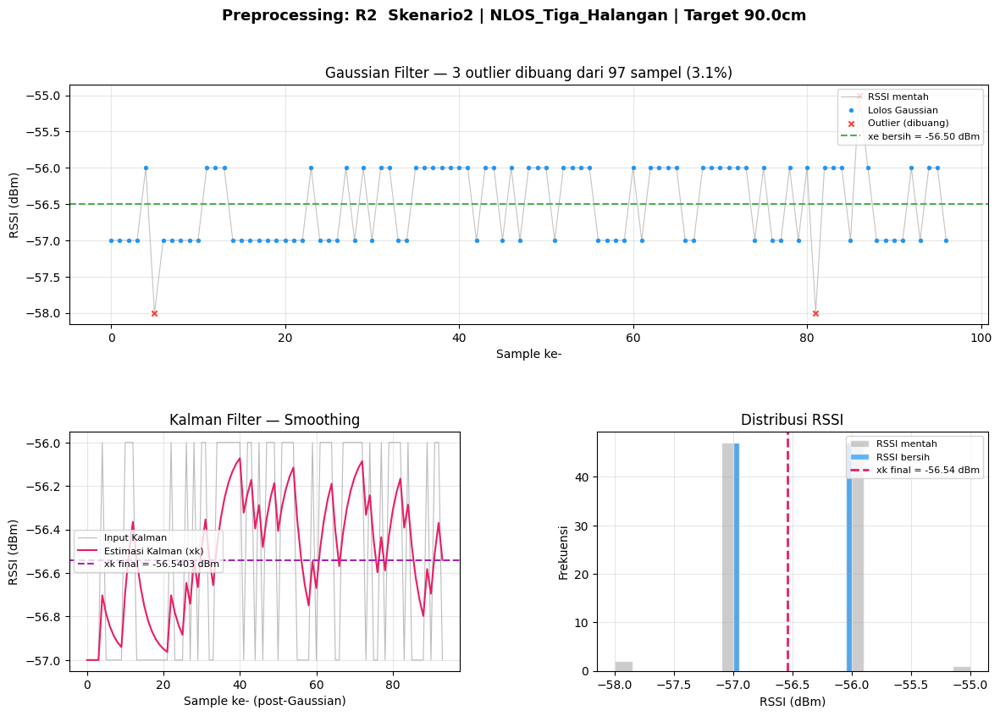

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Tiga_Halangan__Target_90.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_90cm_20260511_111045.xlsx → R3


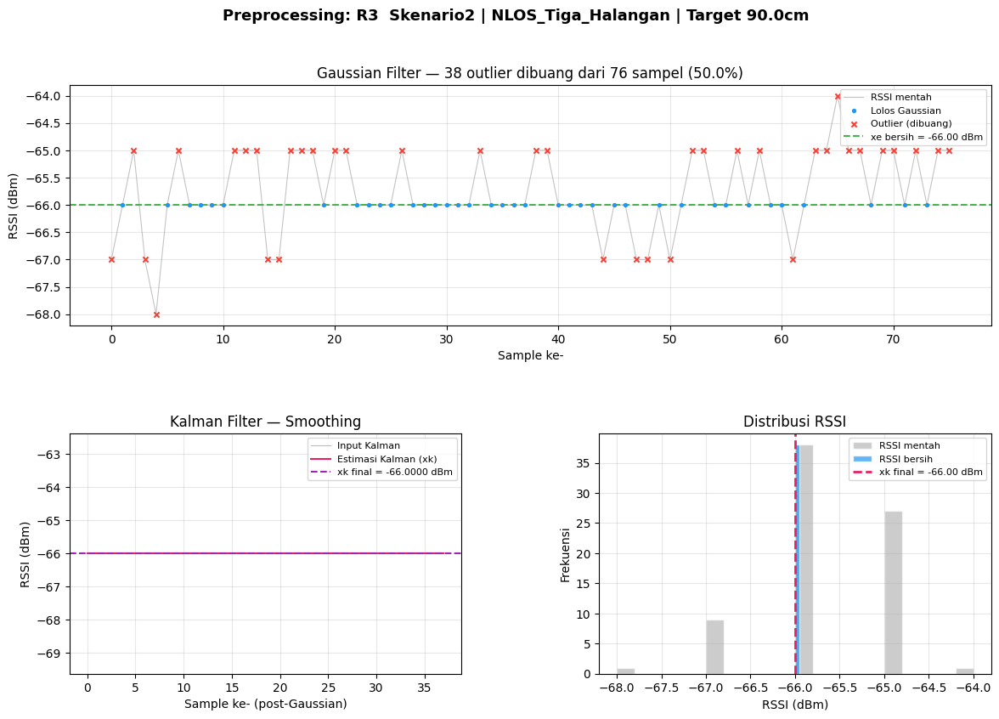

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Tiga_Halangan__Target_90.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_100cm_20260511_023553.xlsx → Target


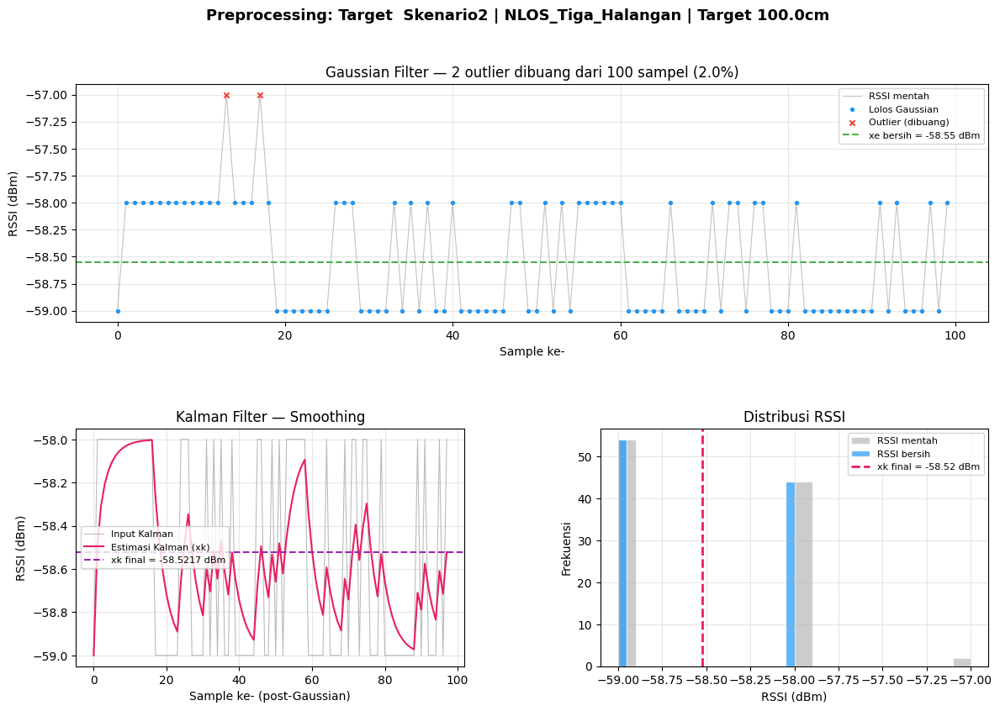

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Tiga_Halangan__Target_100.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_100cm_20260511_023553.xlsx → R1


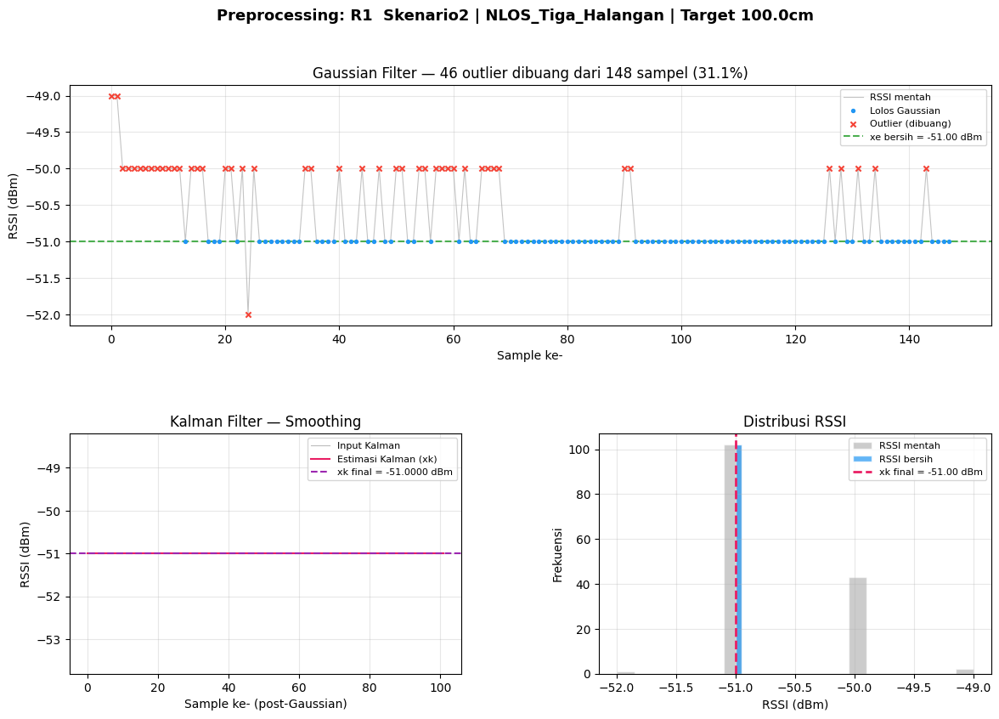

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Tiga_Halangan__Target_100.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_100cm_20260511_023553.xlsx → R2


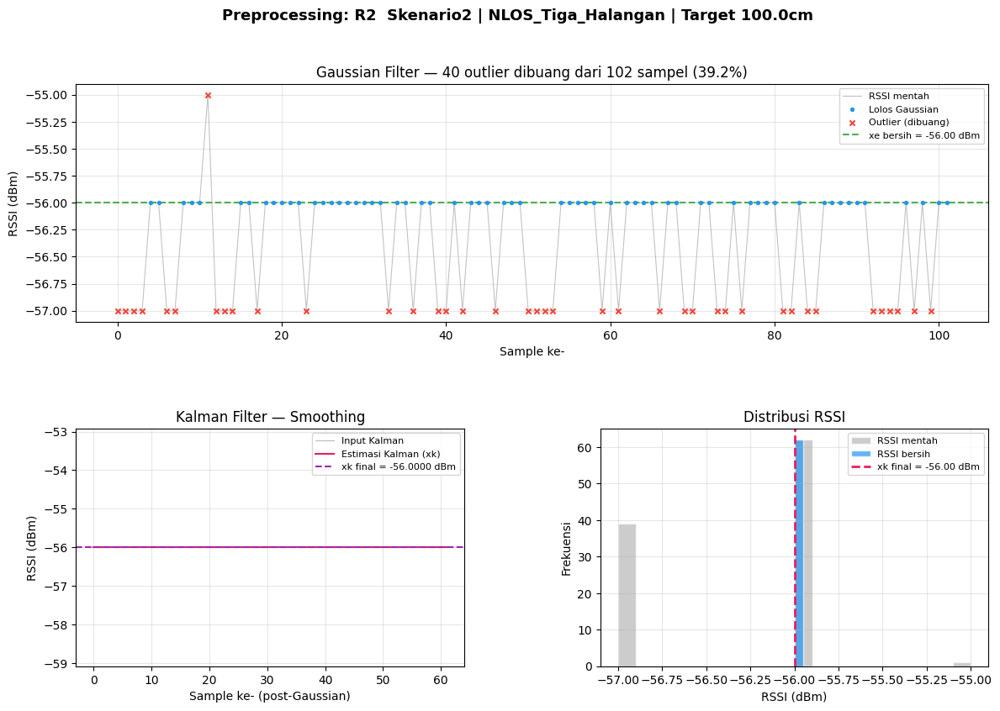

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Tiga_Halangan__Target_100.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_100cm_20260511_023553.xlsx → R3


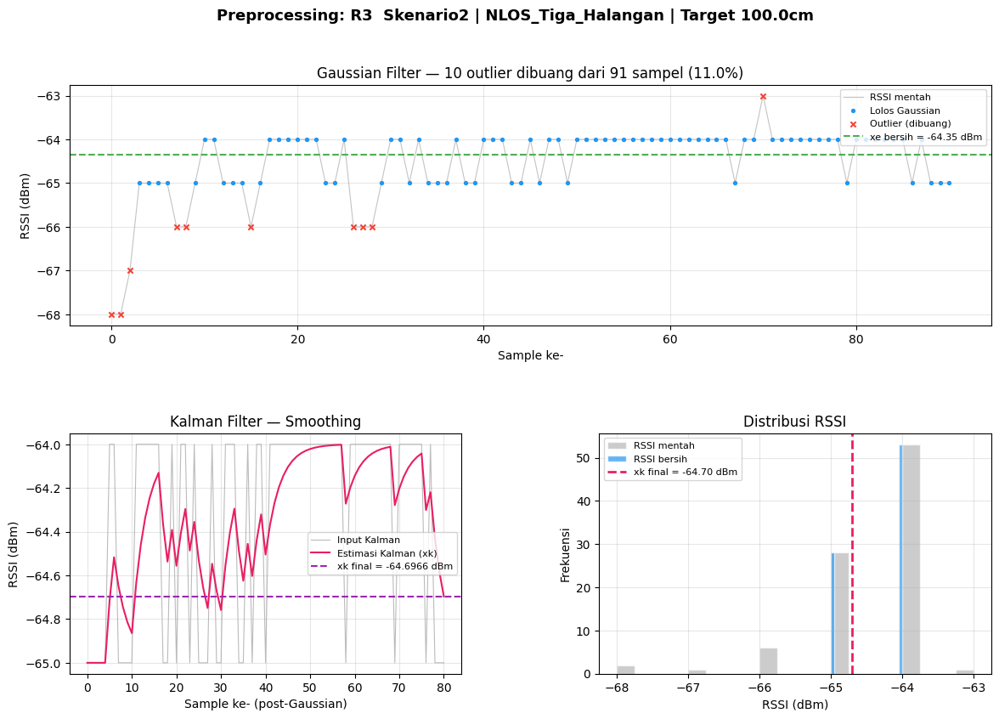

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Tiga_Halangan__Target_100.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_110cm_20260511_111823.xlsx → Target


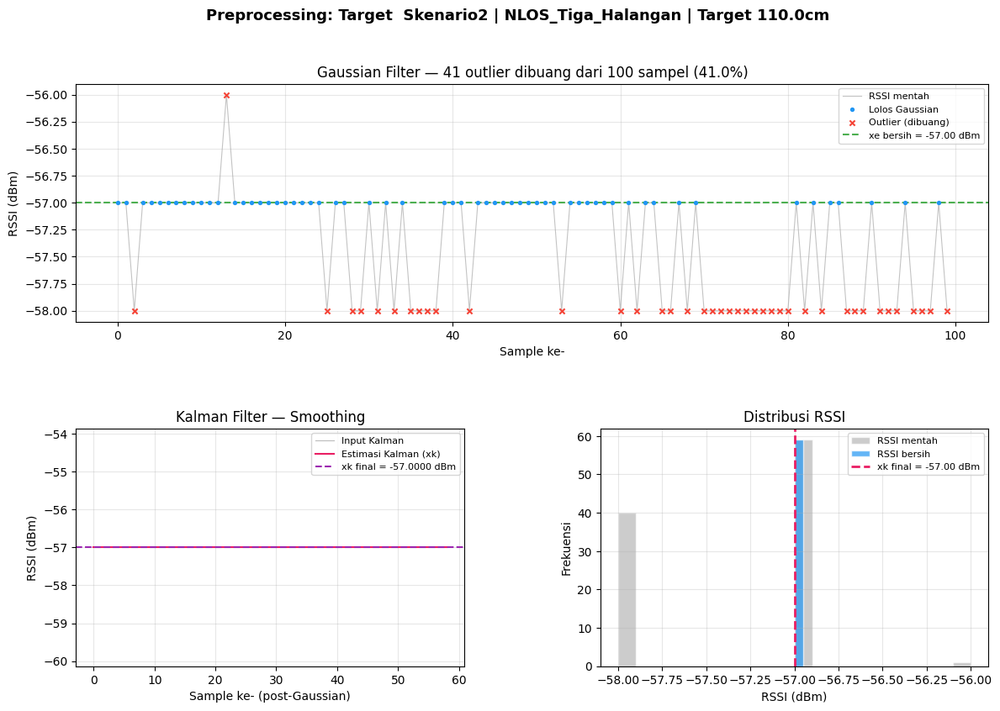

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Tiga_Halangan__Target_110.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_110cm_20260511_111823.xlsx → R1


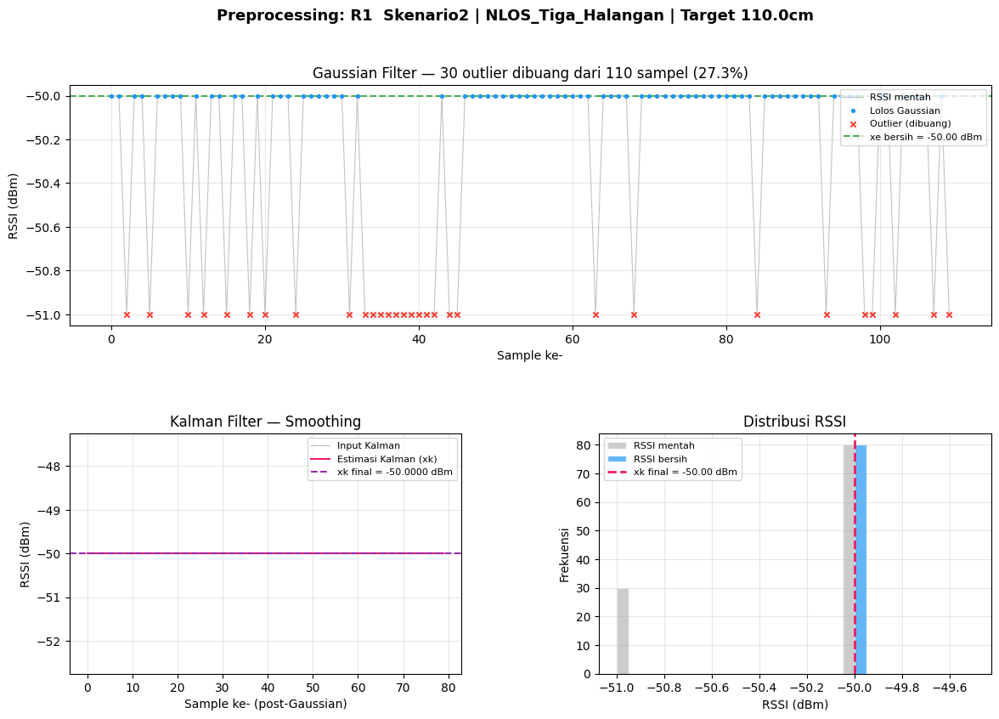

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Tiga_Halangan__Target_110.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_110cm_20260511_111823.xlsx → R2


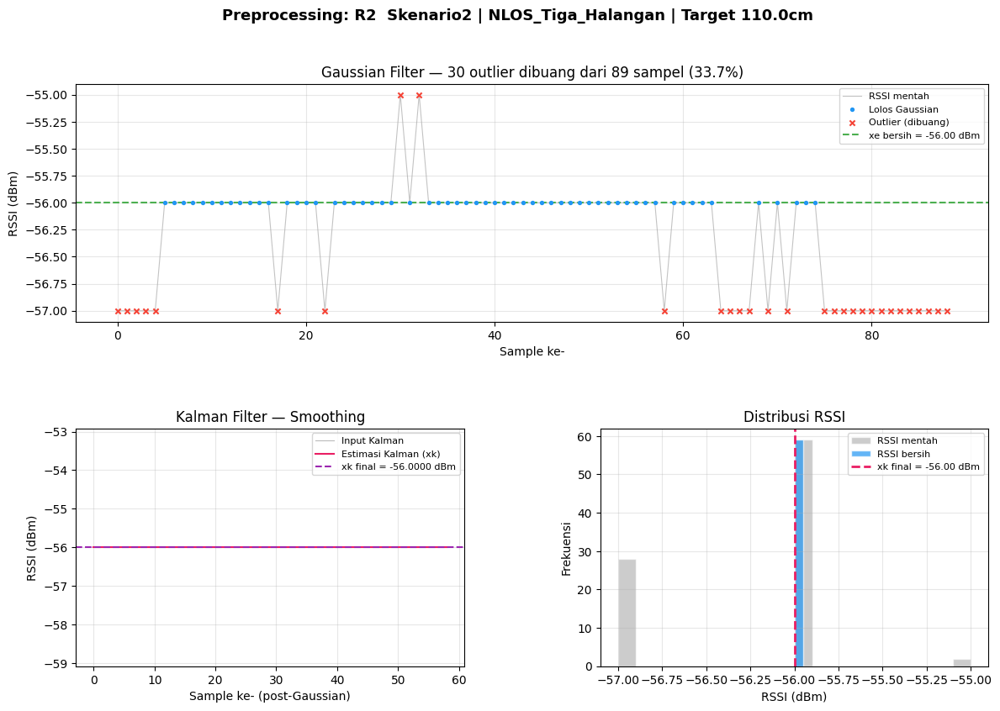

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Tiga_Halangan__Target_110.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_110cm_20260511_111823.xlsx → R3


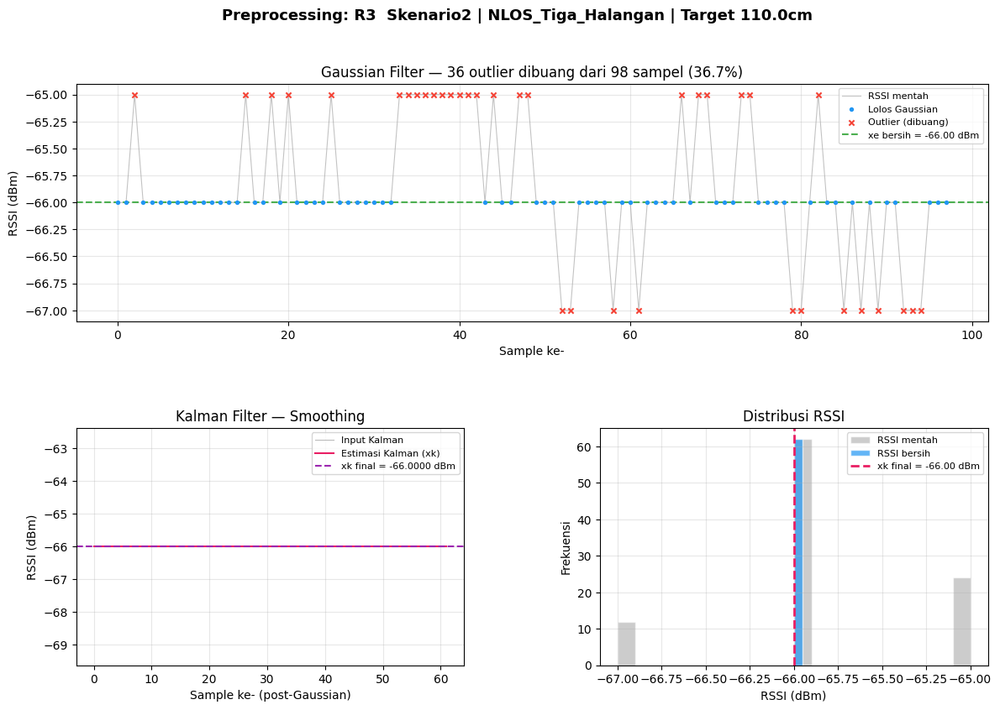

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Tiga_Halangan__Target_110.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_140cm_20260511_105103.xlsx → Target


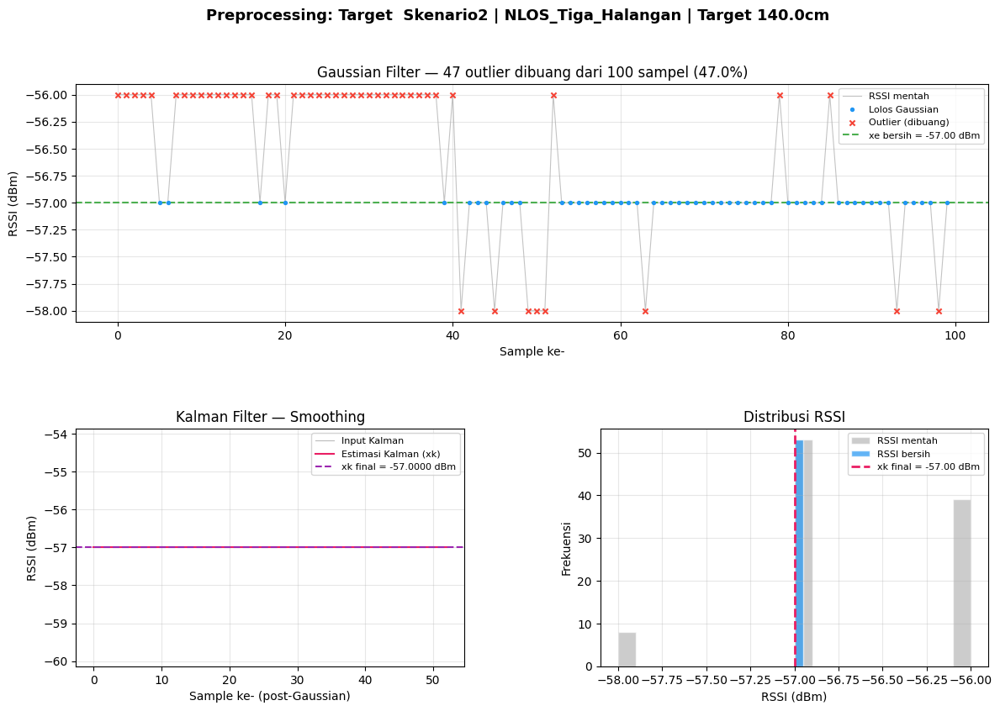

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Tiga_Halangan__Target_140.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_140cm_20260511_105103.xlsx → R1


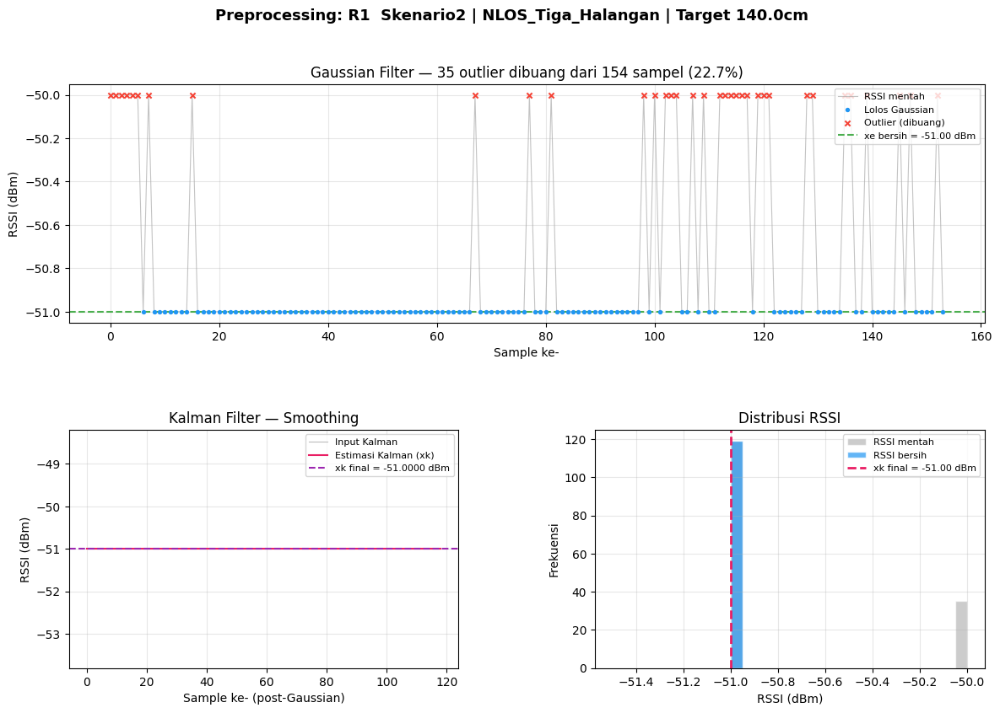

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Tiga_Halangan__Target_140.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_140cm_20260511_105103.xlsx → R2


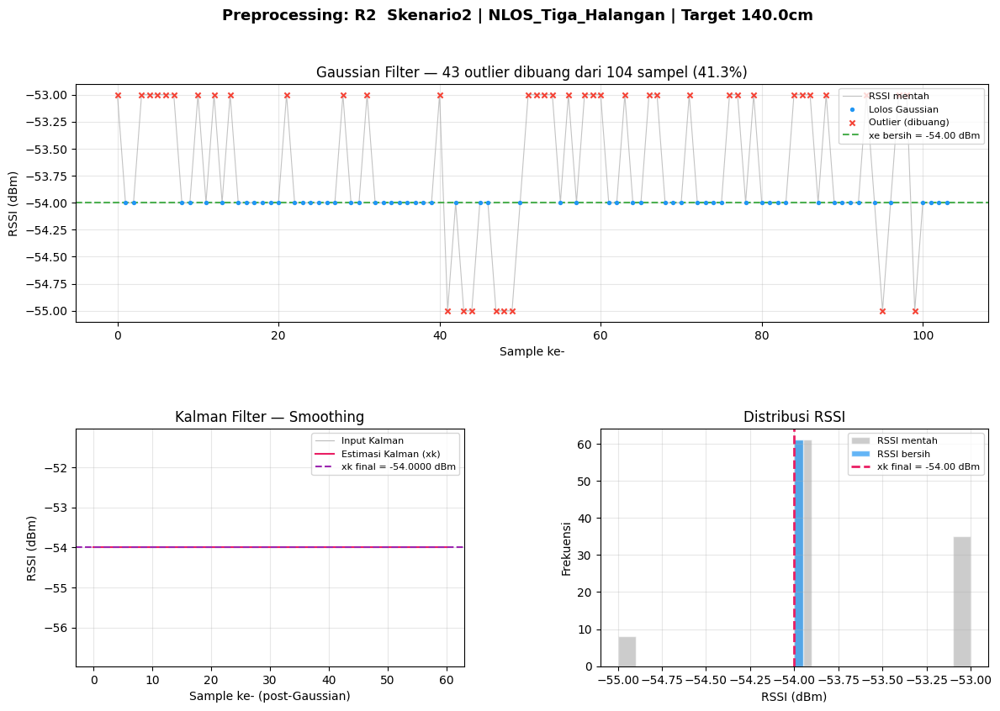

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Tiga_Halangan__Target_140.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_140cm_20260511_105103.xlsx → R3


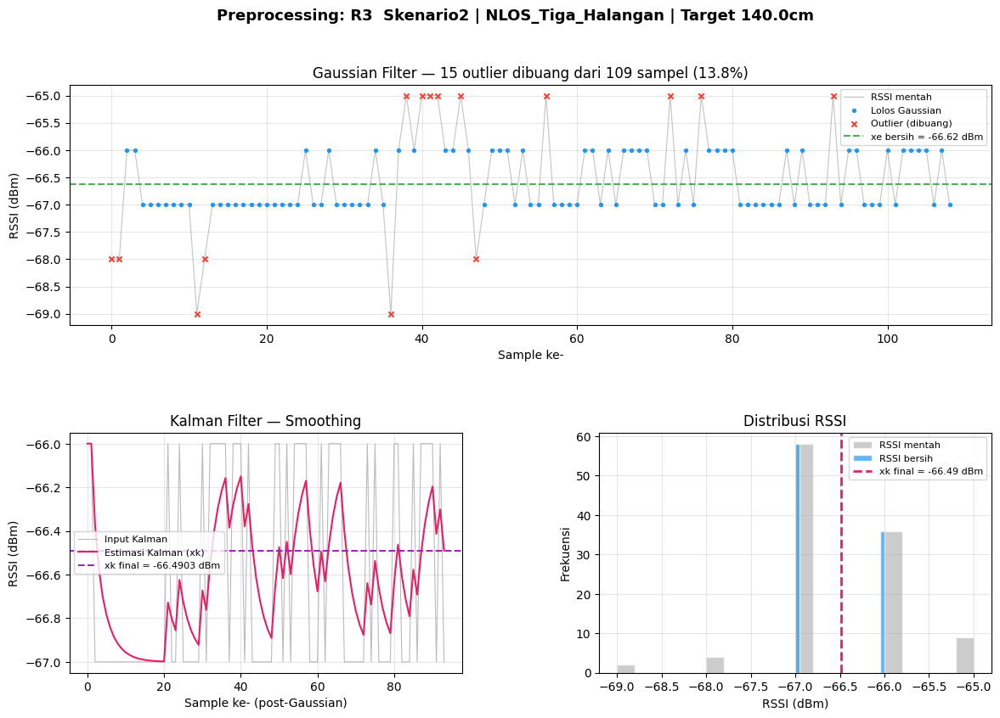

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Tiga_Halangan__Target_140.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_170cm_20260511_110337.xlsx → Target


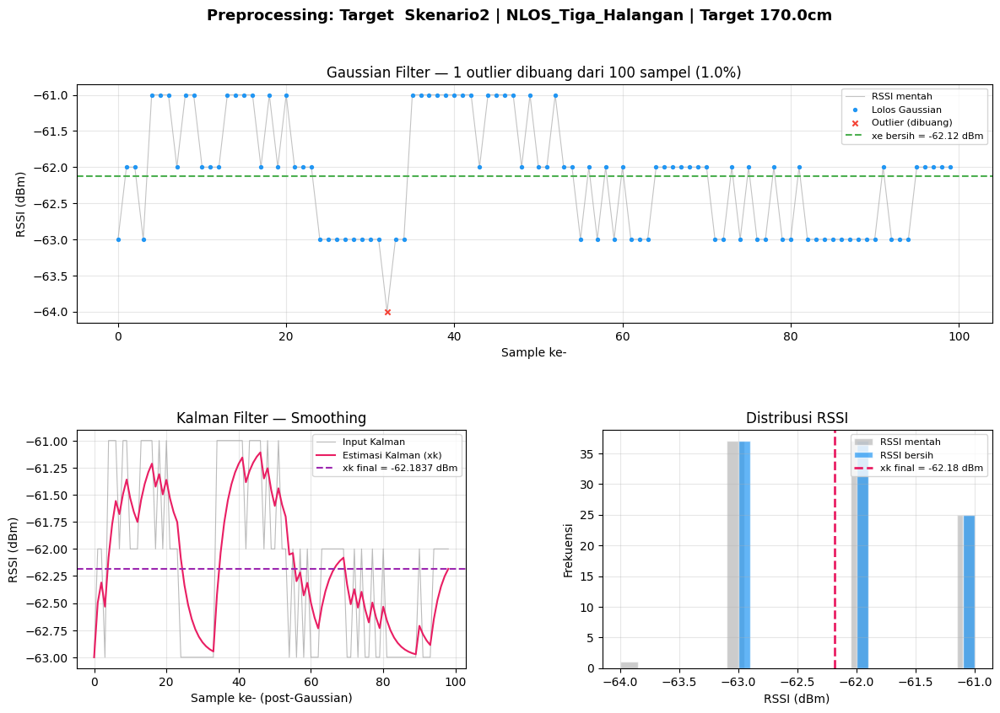

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Tiga_Halangan__Target_170.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_170cm_20260511_110337.xlsx → R1


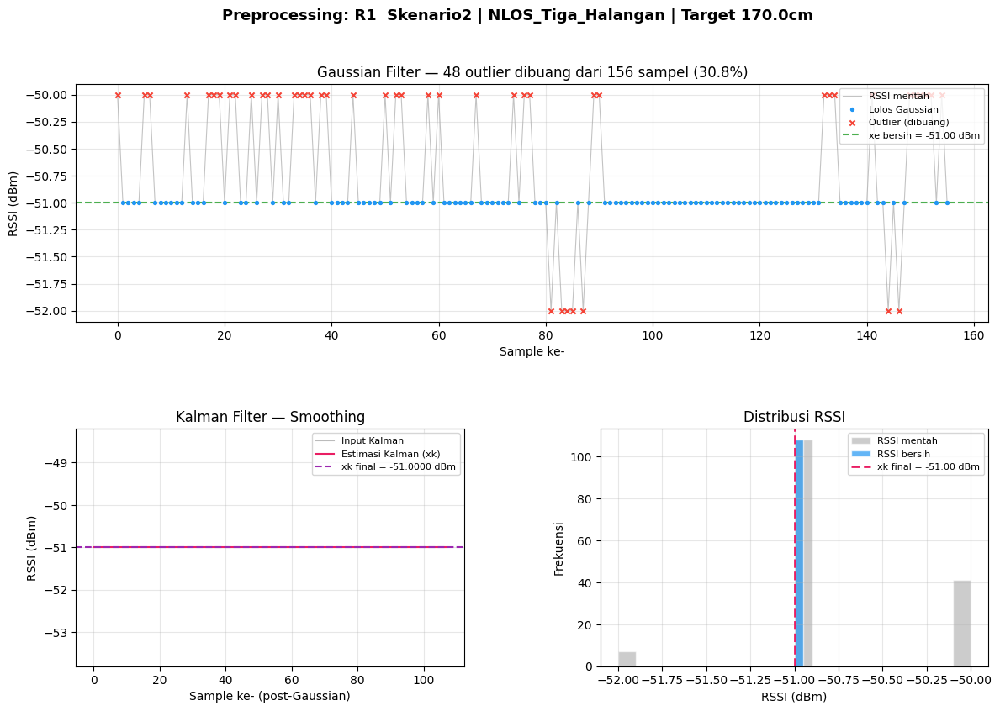

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Tiga_Halangan__Target_170.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_170cm_20260511_110337.xlsx → R2


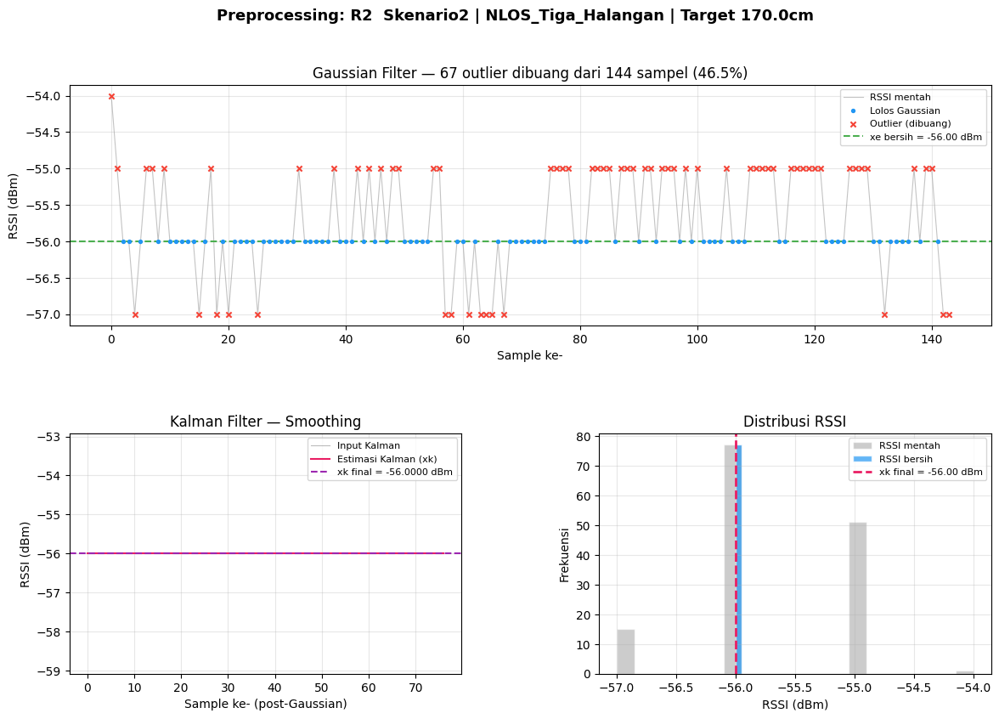

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Tiga_Halangan__Target_170.0cm.png

📊 data_Skenario2_NLOS_Sedang_Target_170cm_20260511_110337.xlsx → R3


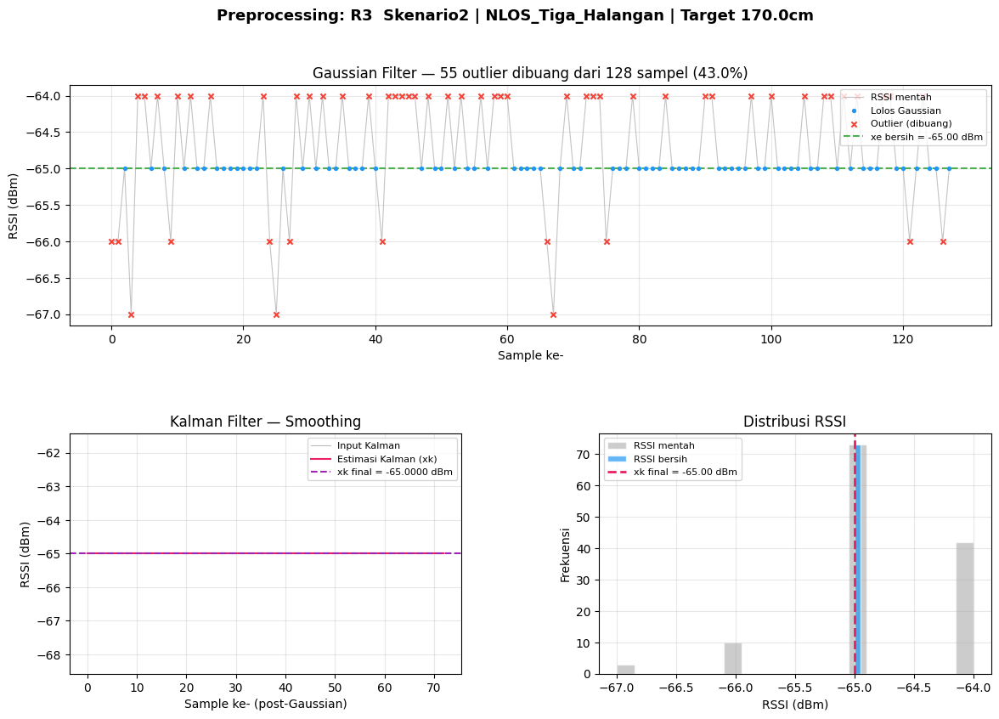

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Tiga_Halangan__Target_170.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_80cm_20260511_114537.xlsx → Target


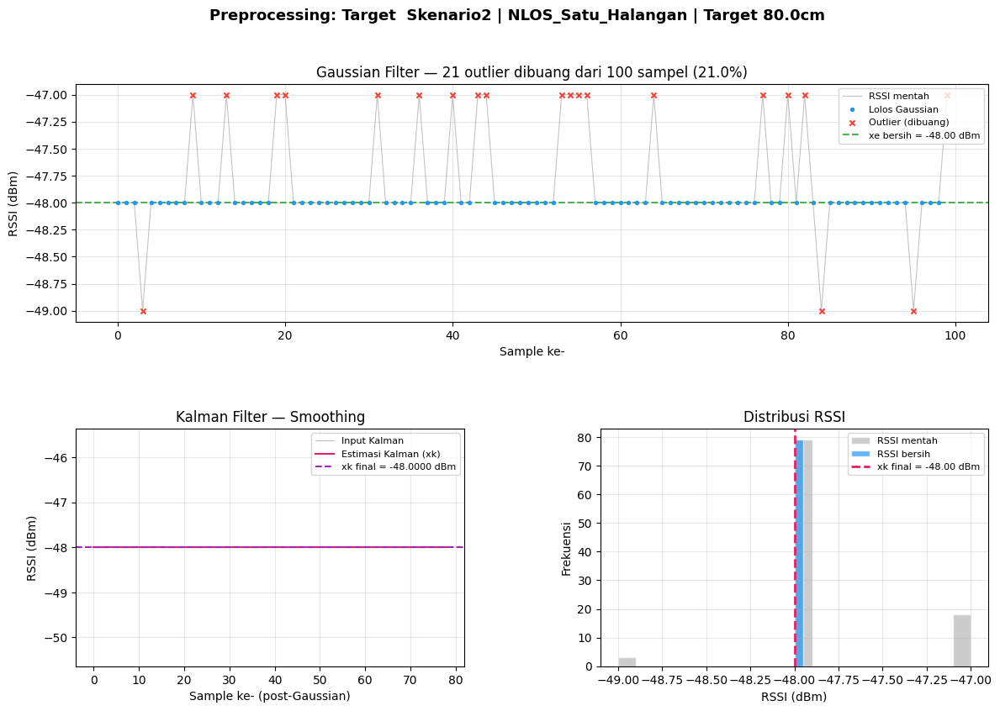

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Satu_Halangan__Target_80.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_80cm_20260511_114537.xlsx → R1


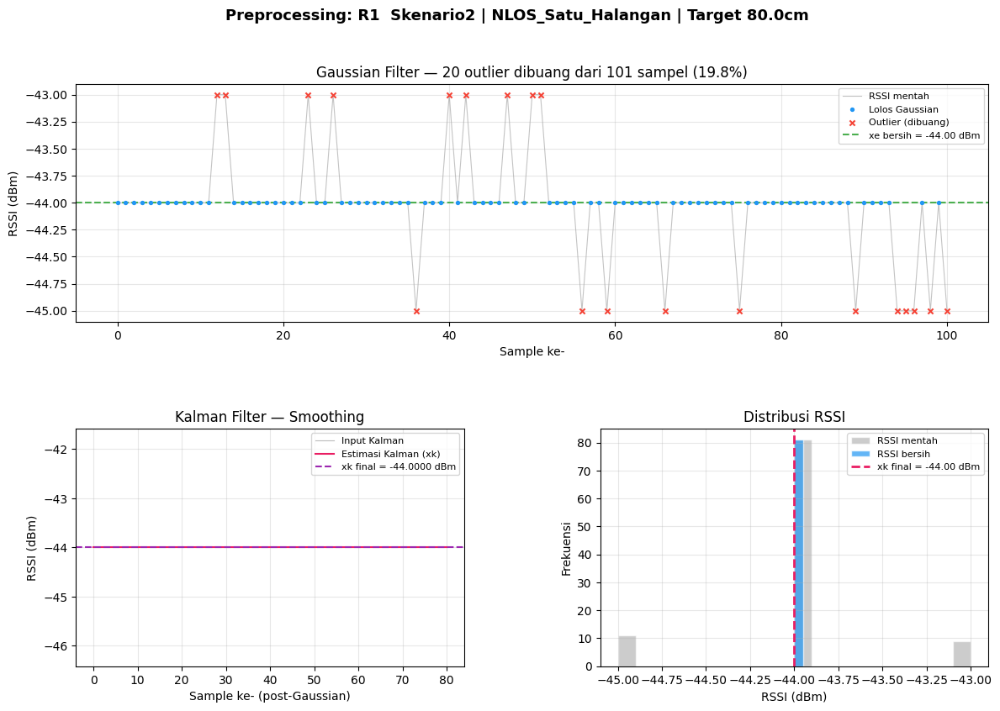

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Satu_Halangan__Target_80.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_80cm_20260511_114537.xlsx → R2


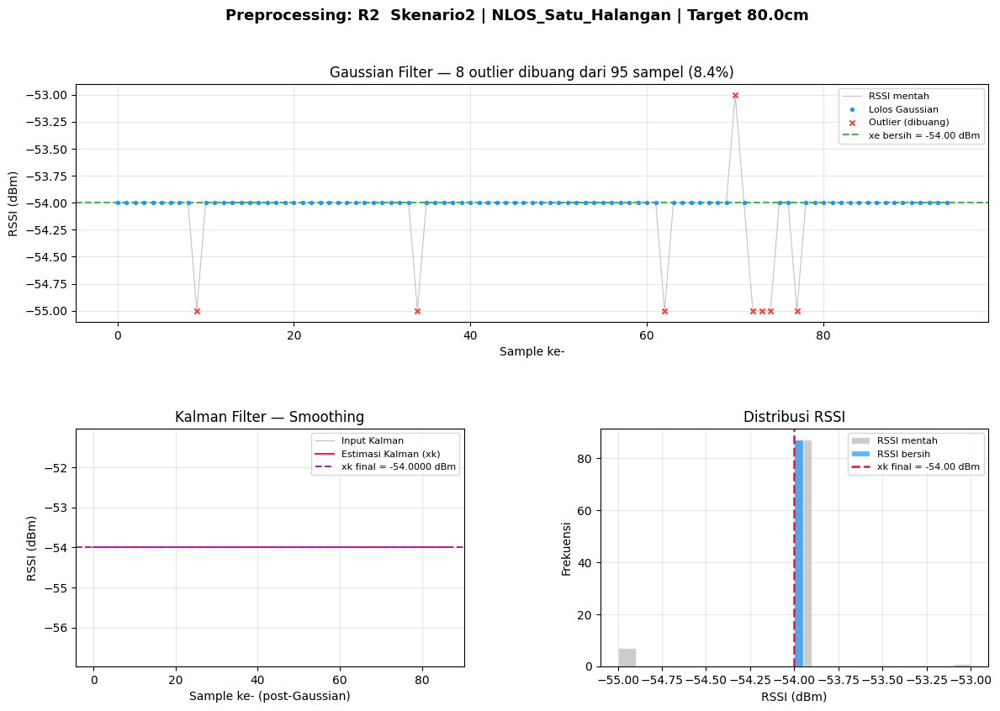

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Satu_Halangan__Target_80.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_80cm_20260511_114537.xlsx → R3


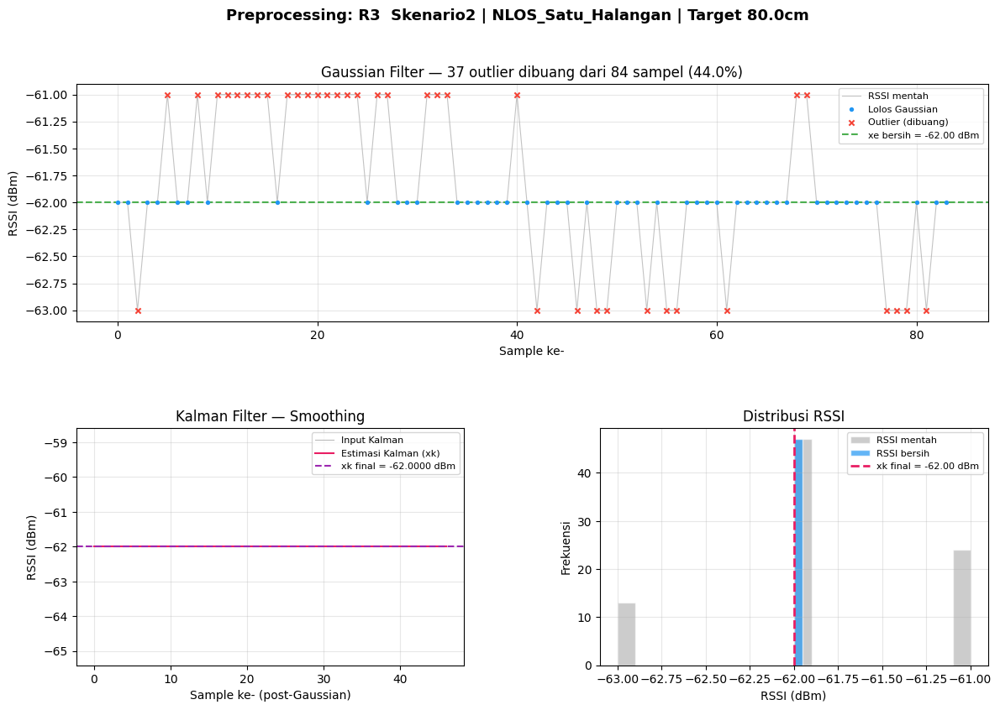

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Satu_Halangan__Target_80.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_90cm_20260511_121623.xlsx → Target


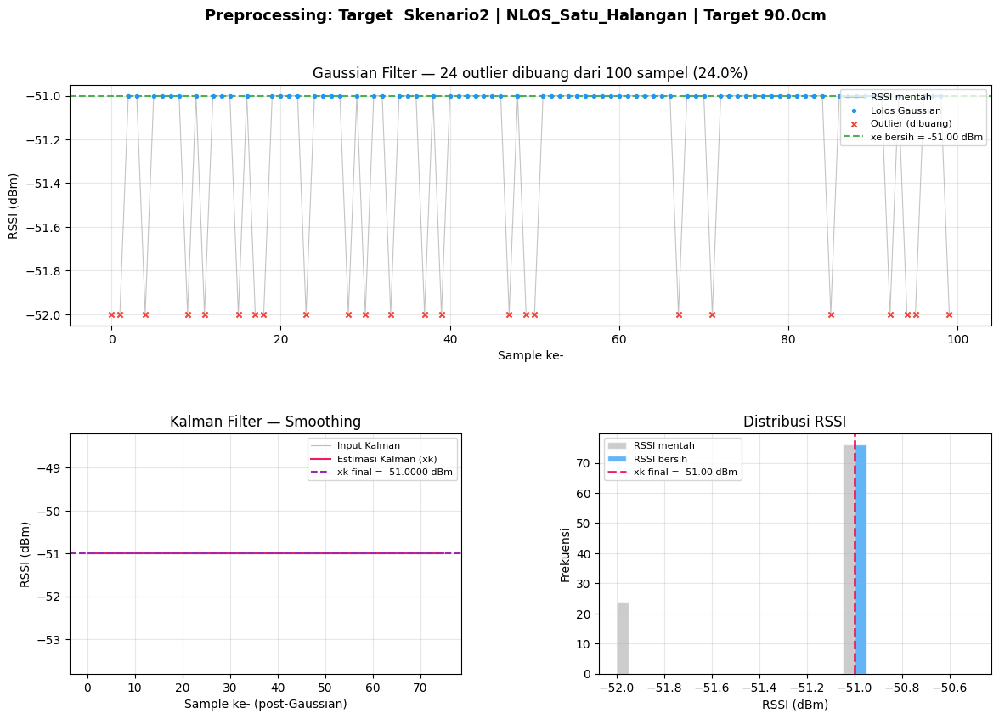

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Satu_Halangan__Target_90.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_90cm_20260511_121623.xlsx → R1


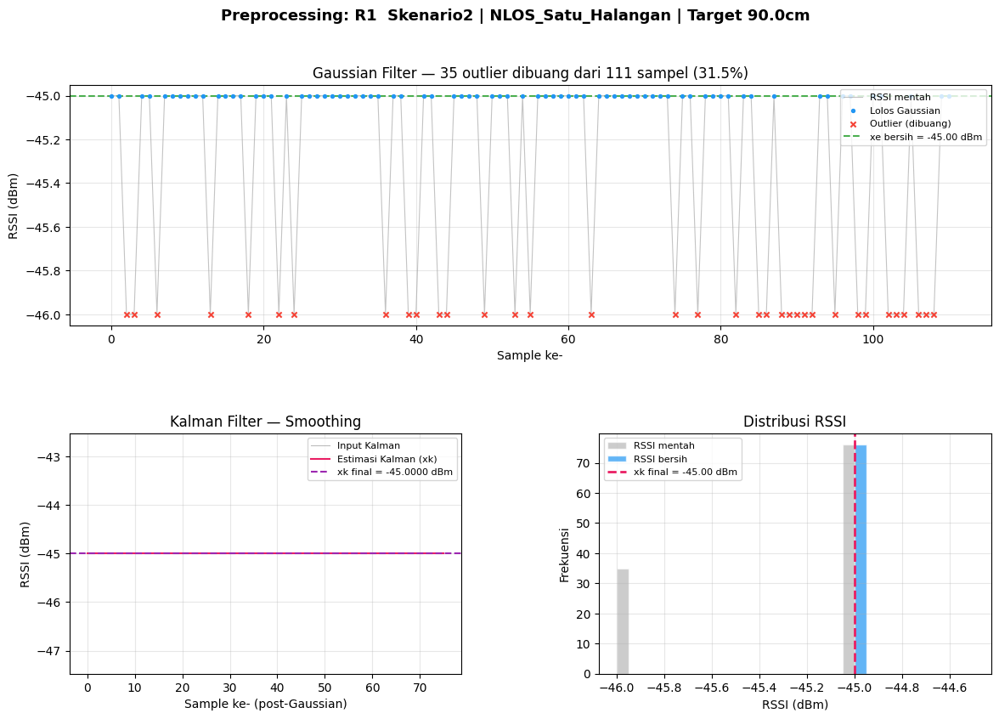

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Satu_Halangan__Target_90.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_90cm_20260511_121623.xlsx → R2


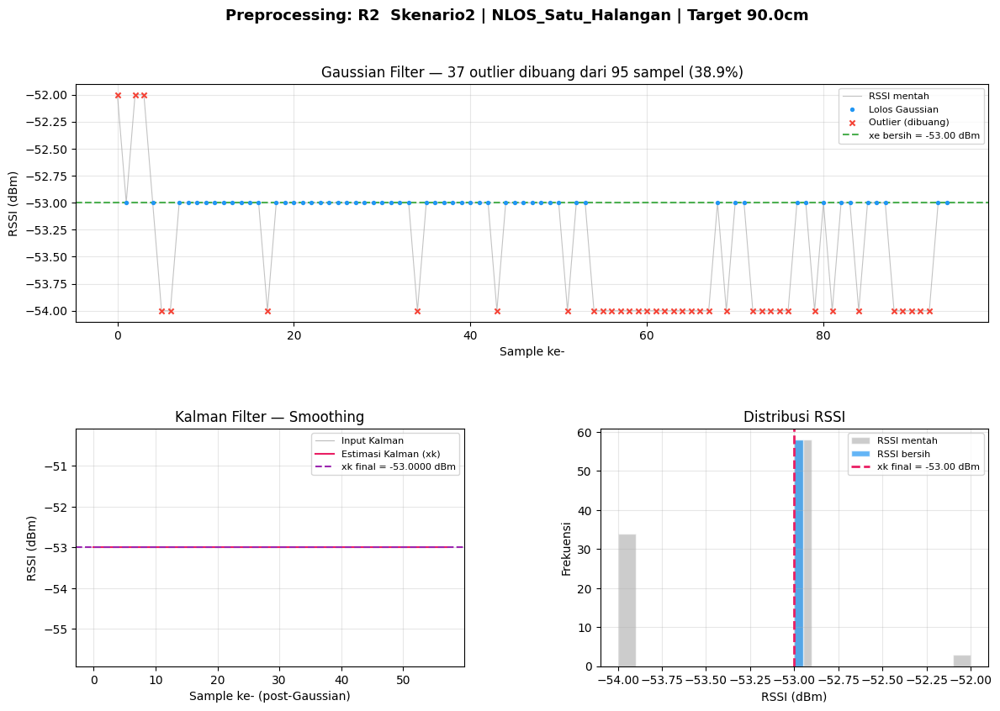

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Satu_Halangan__Target_90.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_90cm_20260511_121623.xlsx → R3


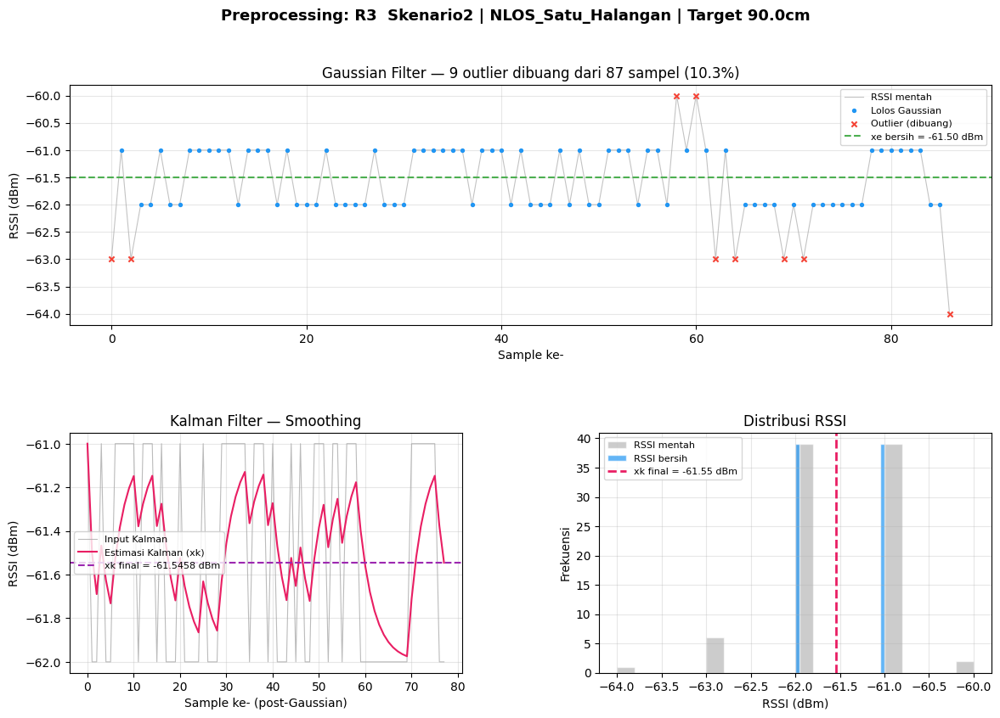

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Satu_Halangan__Target_90.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_100cm_20260511_115343.xlsx → Target


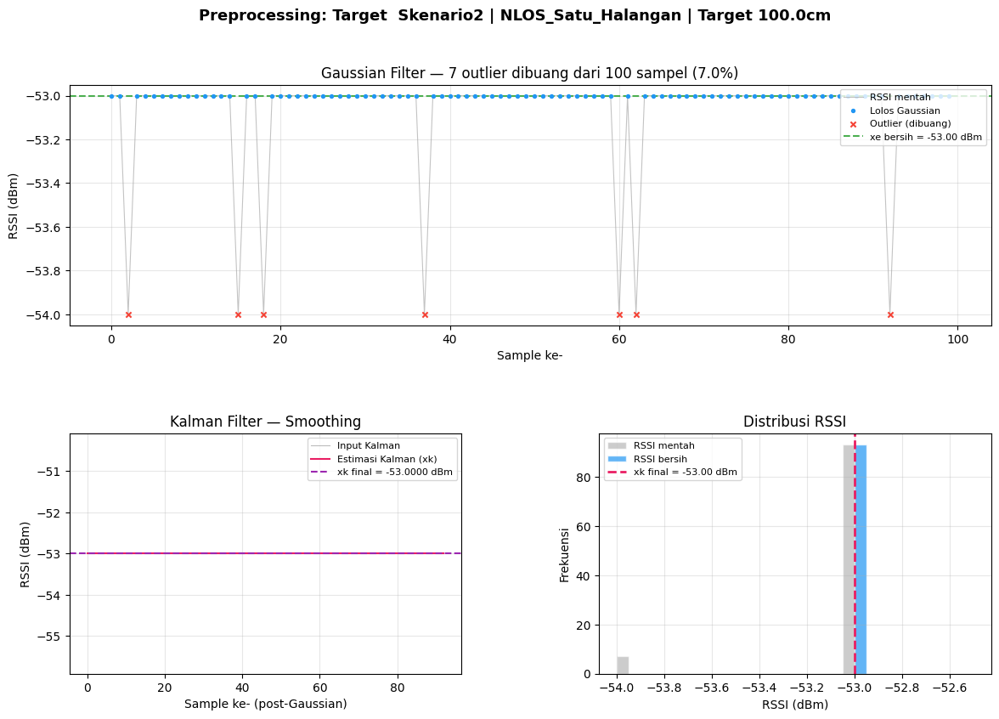

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Satu_Halangan__Target_100.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_100cm_20260511_115343.xlsx → R1


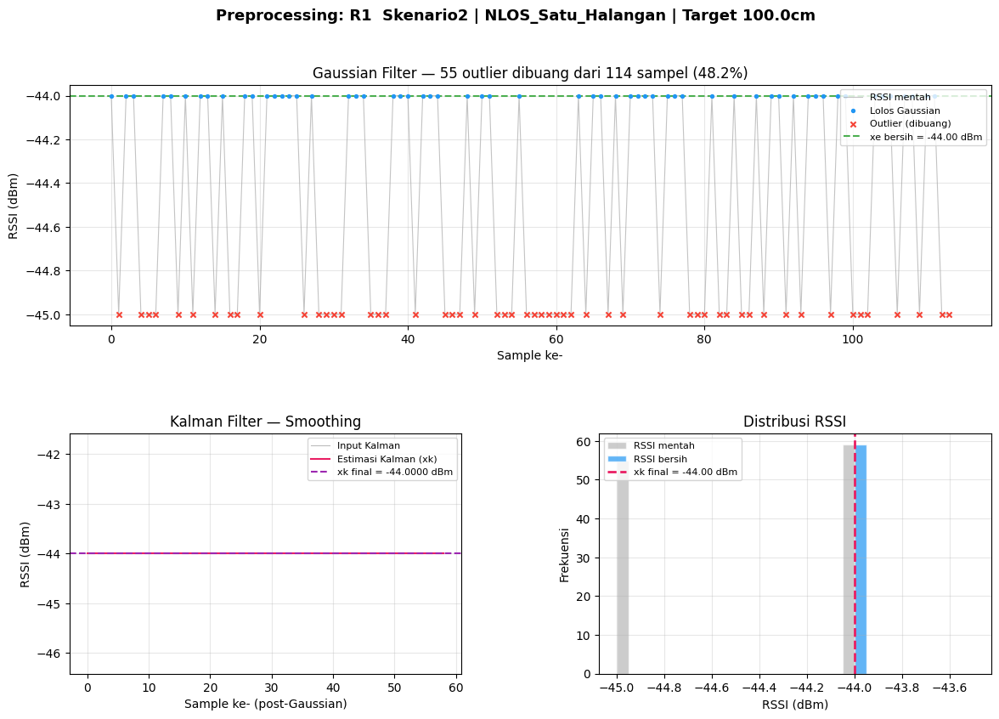

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Satu_Halangan__Target_100.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_100cm_20260511_115343.xlsx → R2


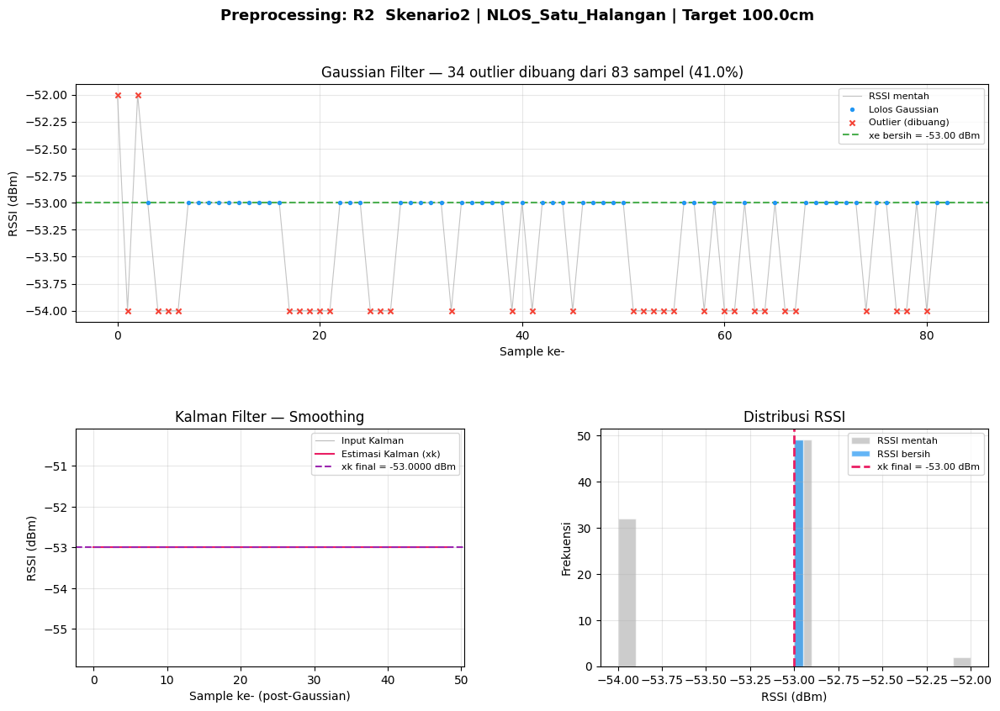

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Satu_Halangan__Target_100.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_100cm_20260511_115343.xlsx → R3


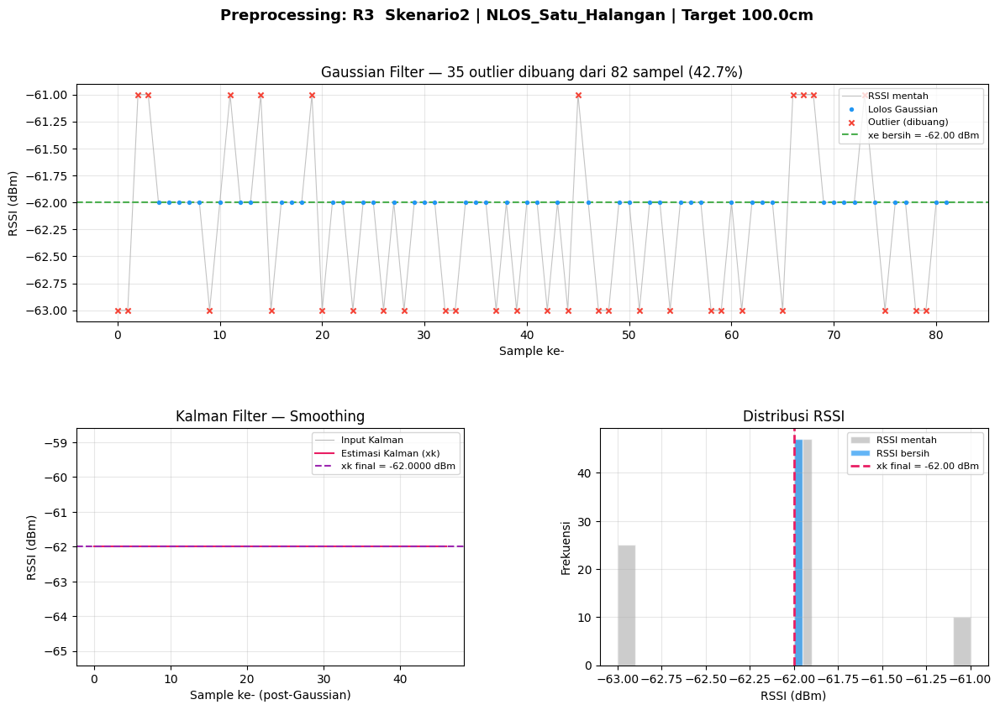

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Satu_Halangan__Target_100.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_110cm_20260511_122408.xlsx → Target


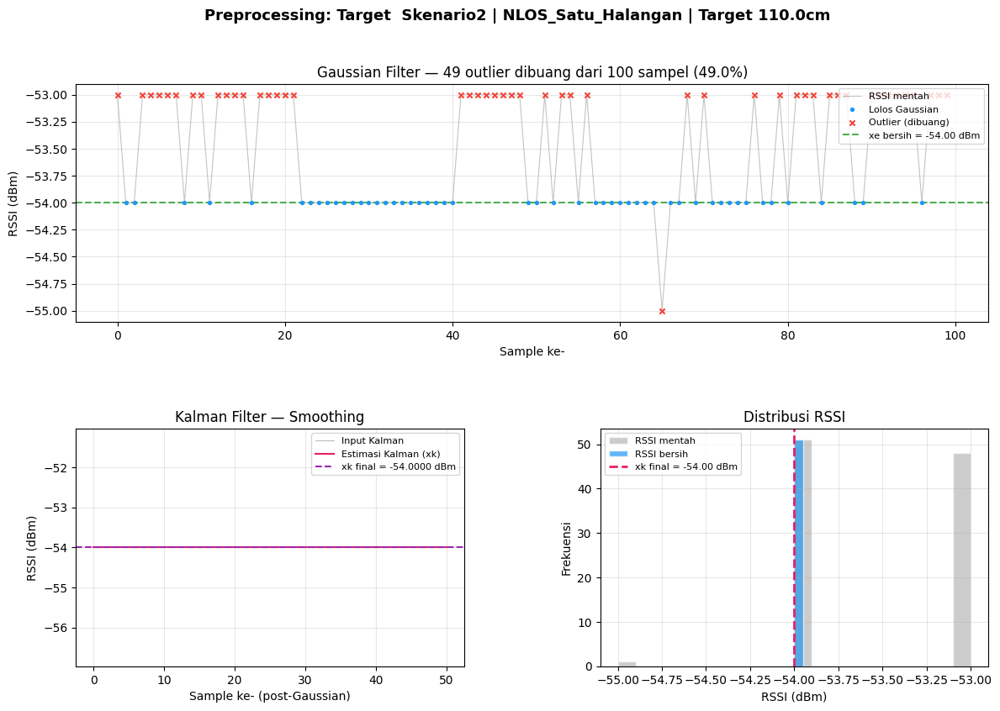

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Satu_Halangan__Target_110.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_110cm_20260511_122408.xlsx → R1


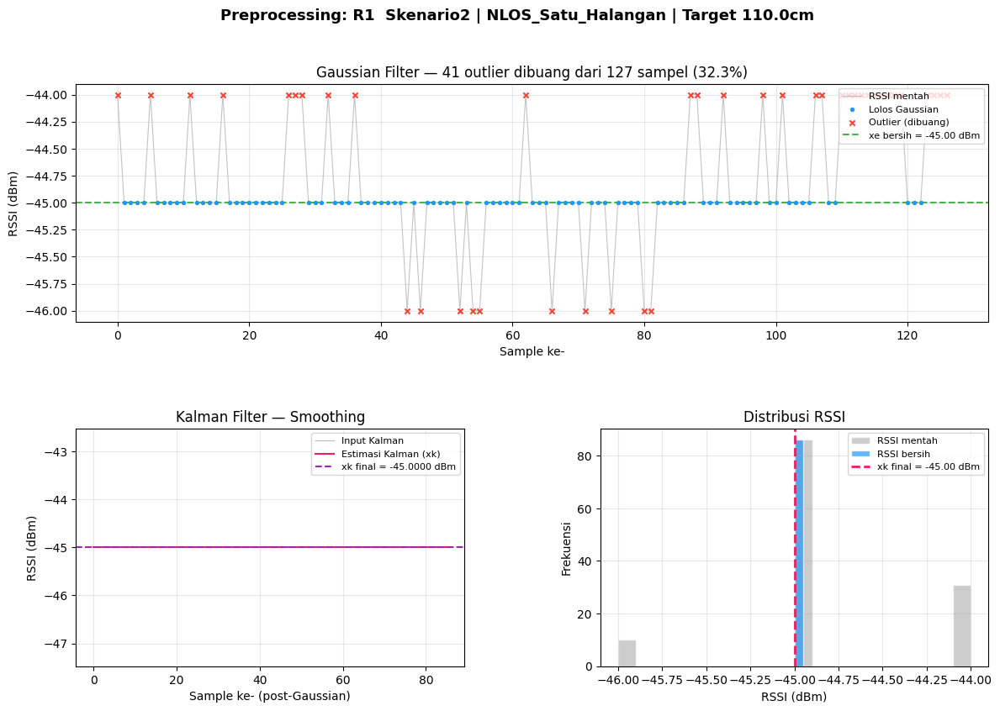

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Satu_Halangan__Target_110.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_110cm_20260511_122408.xlsx → R2


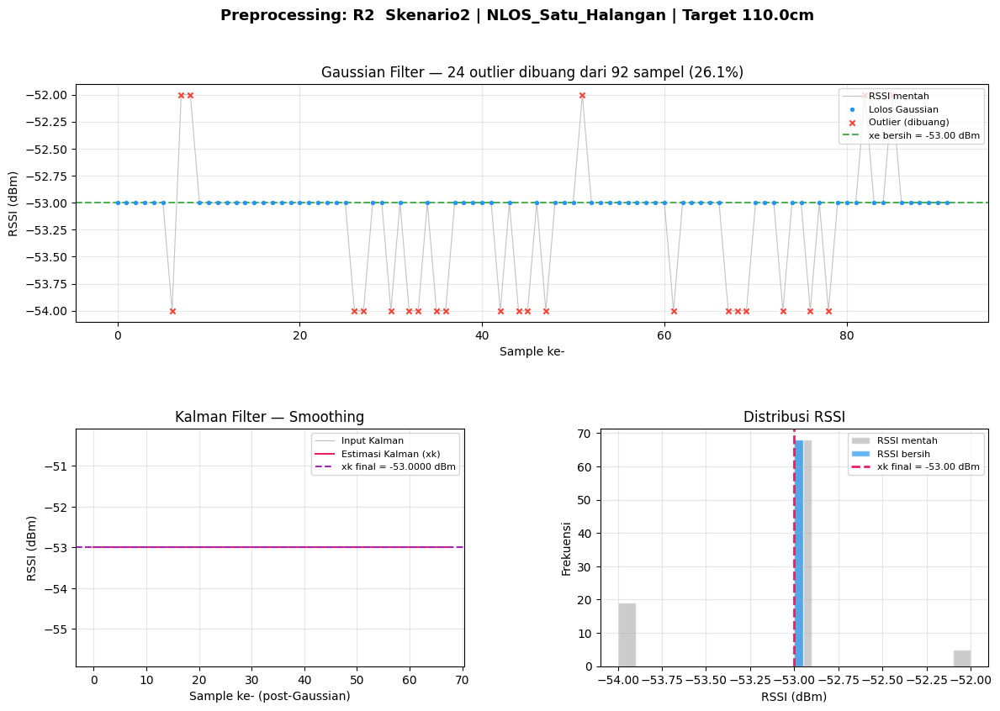

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Satu_Halangan__Target_110.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_110cm_20260511_122408.xlsx → R3


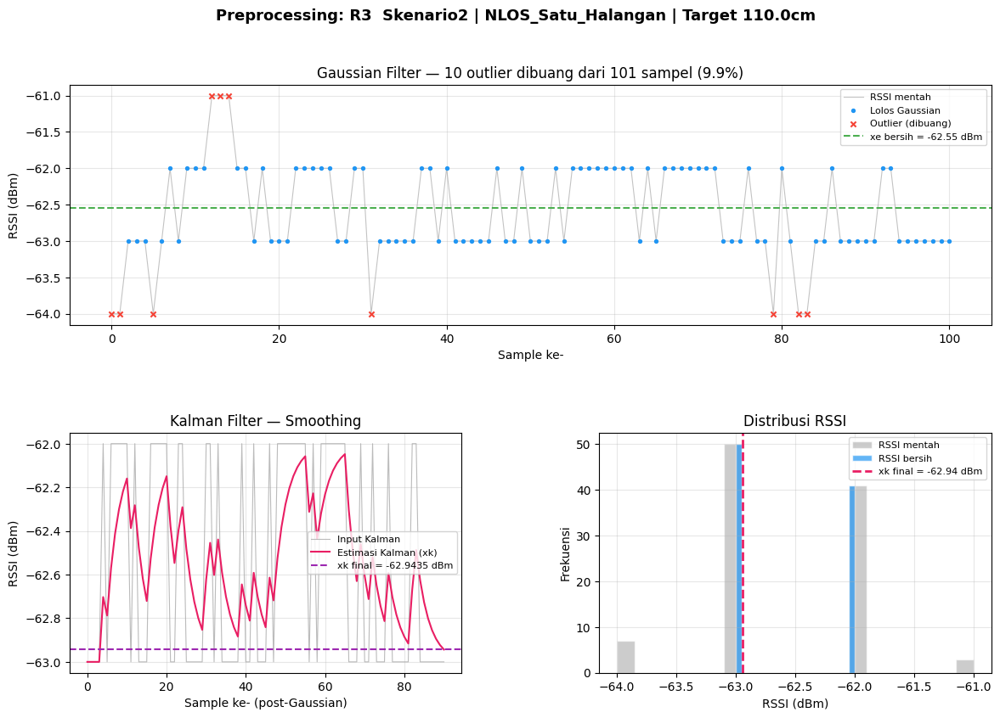

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Satu_Halangan__Target_110.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_140cm_20260511_120132.xlsx → Target


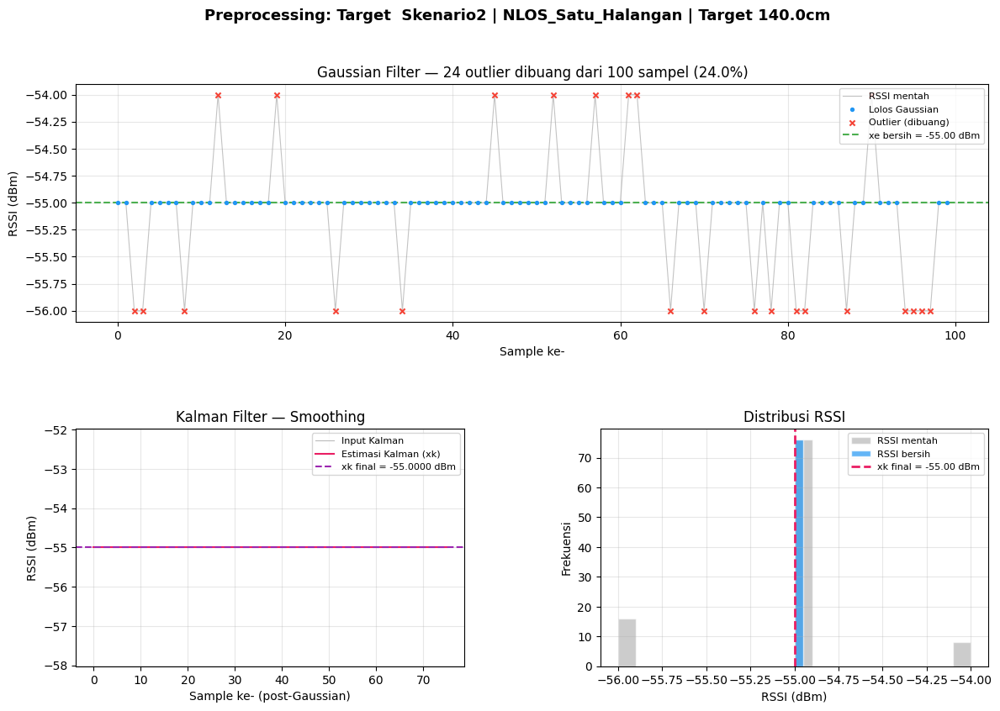

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Satu_Halangan__Target_140.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_140cm_20260511_120132.xlsx → R1


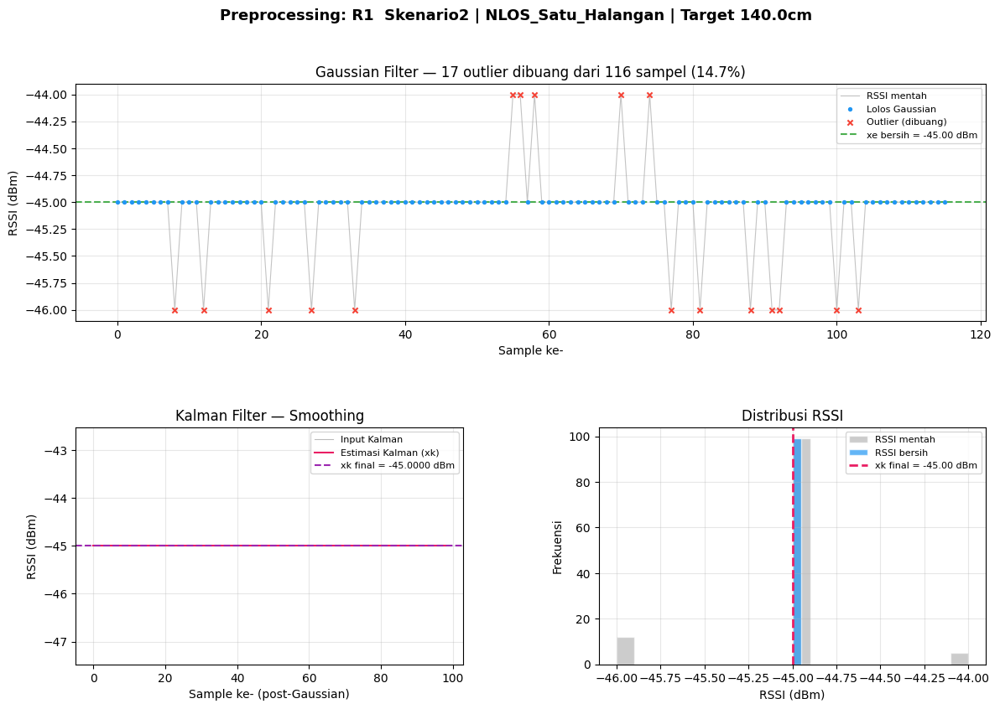

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Satu_Halangan__Target_140.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_140cm_20260511_120132.xlsx → R2


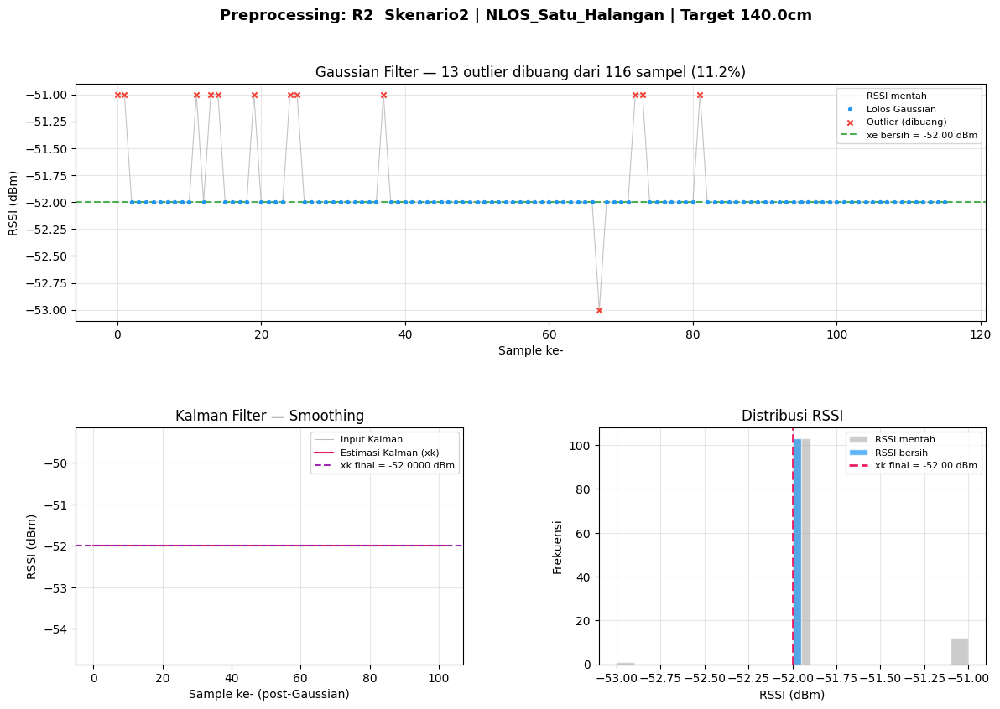

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Satu_Halangan__Target_140.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_140cm_20260511_120132.xlsx → R3


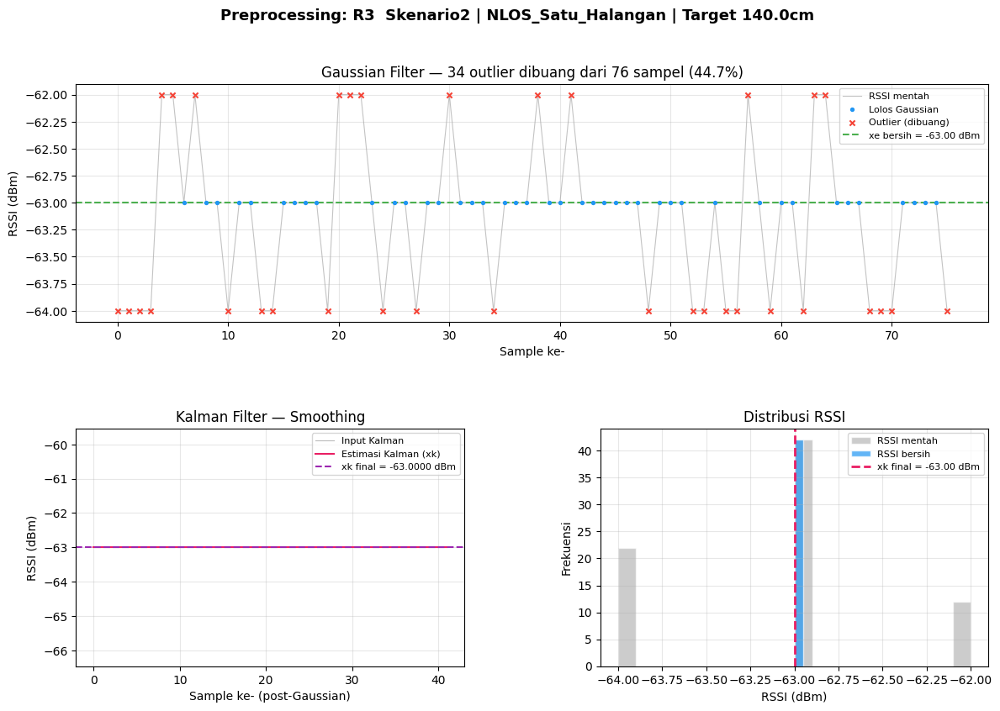

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Satu_Halangan__Target_140.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_170cm_20260511_120850.xlsx → Target


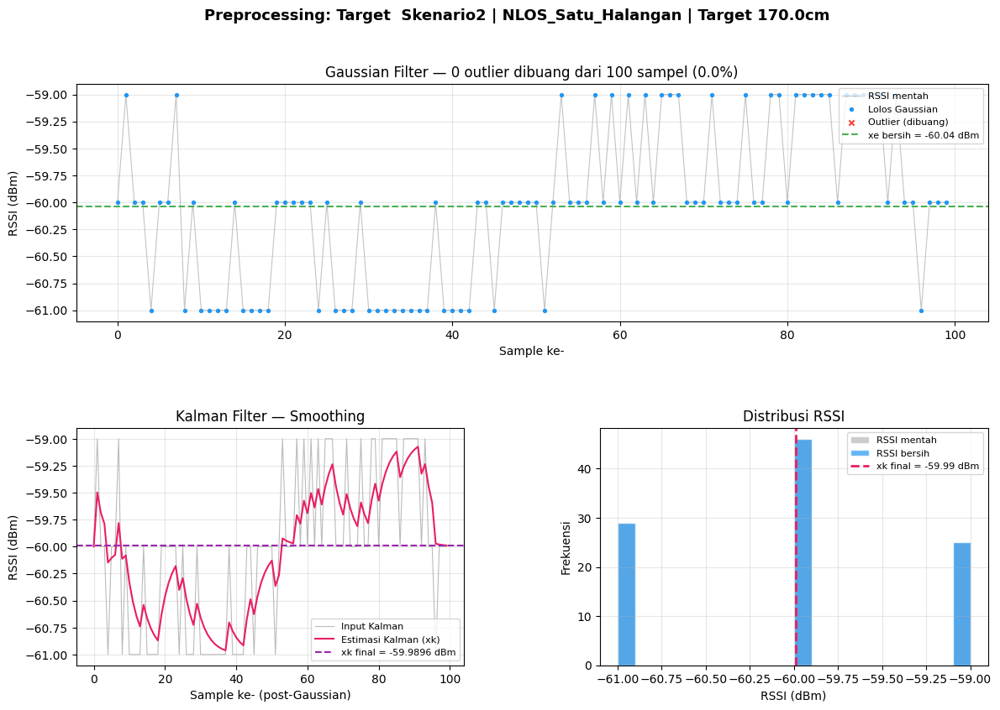

  ✅ Plot disimpan: preprocessing_Target_Skenario2__NLOS_Satu_Halangan__Target_170.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_170cm_20260511_120850.xlsx → R1


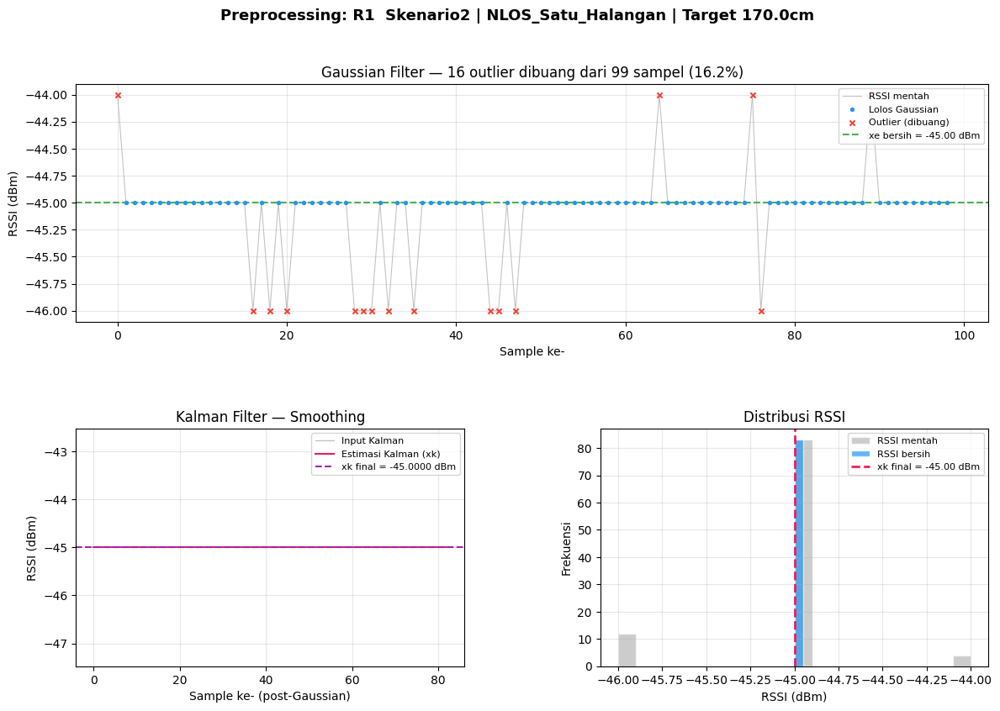

  ✅ Plot disimpan: preprocessing_R1_Skenario2__NLOS_Satu_Halangan__Target_170.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_170cm_20260511_120850.xlsx → R2


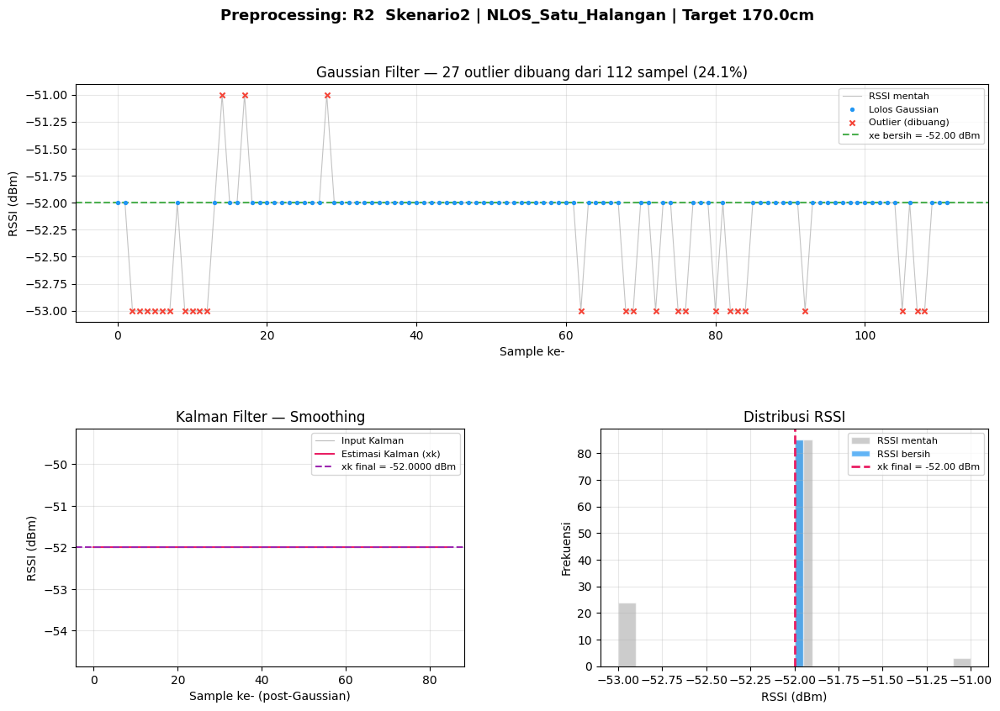

  ✅ Plot disimpan: preprocessing_R2_Skenario2__NLOS_Satu_Halangan__Target_170.0cm.png

📊 data_Skenario2_NLOS_Sedikit_Target_170cm_20260511_120850.xlsx → R3


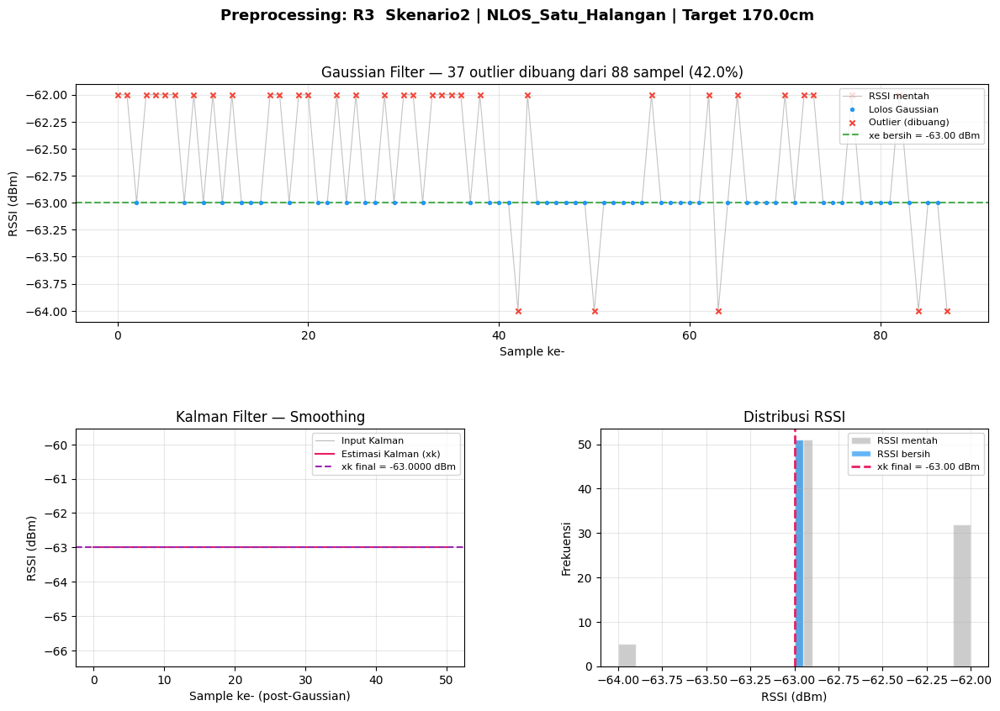

  ✅ Plot disimpan: preprocessing_R3_Skenario2__NLOS_Satu_Halangan__Target_170.0cm.png


In [ ]:
"""
    Plot 3 panel untuk satu sheet/tag:
      1. RSSI mentah vs Gaussian (outlier ditandai merah)
      2. Smoothing Kalman Filter
      3. Histogram distribusi RSSI
"""
def visualisasi_preprocessing(hasil: dict, judul_extra: str = ""):
    label = hasil['label']
    rssi_mentah = hasil['rssi_mentah']
    mask = hasil['mask_gauss']
    x_update = hasil['x_update_seq']
    xe_bersih = hasil['xe_bersih']
    xk_final = hasil['xk_final']

    n = len(rssi_mentah)
    idx_semua = np.arange(n)
    rssi_bersih = rssi_mentah[mask]

    fig = plt.figure(figsize=(14, 9))
    fig.suptitle(f'Preprocessing: {label}  {judul_extra}', fontsize=13, fontweight='bold', y=0.98)
    gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)

    # Panel 1 — RSSI mentah + outlier
    ax1 = fig.add_subplot(gs[0, :])
    ax1.plot(idx_semua, rssi_mentah, color='#aaaaaa', lw=0.8, alpha=0.7, label='RSSI mentah')
    ax1.scatter(idx_semua[mask], rssi_mentah[mask], color='#2196F3', s=8, zorder=3, label='Lolos Gaussian')
    ax1.scatter(idx_semua[~mask], rssi_mentah[~mask], color='#F44336', s=20, marker='x', zorder=4, label='Outlier (dibuang)')
    ax1.axhline(xe_bersih, color='#4CAF50', lw=1.5, ls='--', label=f'xe bersih = {xe_bersih:.2f} dBm')
    ax1.set_xlabel('Sample ke-')
    ax1.set_ylabel('RSSI (dBm)')
    ax1.set_title(f'Gaussian Filter — {hasil["n_buang"]} outlier dibuang dari {n} sampel ({100 - hasil["P_retensi"]:.1f}%)')
    ax1.legend(loc='upper right', fontsize=8)
    ax1.grid(True, alpha=0.3)

    # Panel 2 — Kalman smoothing
    ax2 = fig.add_subplot(gs[1, 0])
    ax2.plot(rssi_bersih, color='#aaaaaa', lw=0.8, alpha=0.8, label='Input Kalman')
    ax2.plot(x_update, color='#E91E63', lw=1.5, label='Estimasi Kalman (xk)')
    ax2.axhline(xk_final, color='#9C27B0', lw=1.5, ls='--', label=f'xk final = {xk_final:.4f} dBm')
    ax2.set_xlabel('Sample ke- (post-Gaussian)')
    ax2.set_ylabel('RSSI (dBm)')
    ax2.set_title('Kalman Filter — Smoothing')
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3)

    # Panel 3 — Histogram
    ax3 = fig.add_subplot(gs[1, 1])
    ax3.hist(rssi_mentah, bins=20, color='#aaaaaa', alpha=0.6, edgecolor='white', label='RSSI mentah')
    ax3.hist(rssi_bersih, bins=20, color='#2196F3', alpha=0.7, edgecolor='white', label='RSSI bersih')
    ax3.axvline(xk_final, color='#E91E63', lw=2, ls='--', label=f'xk final = {xk_final:.2f} dBm')
    ax3.set_xlabel('RSSI (dBm)')
    ax3.set_ylabel('Frekuensi')
    ax3.set_title('Distribusi RSSI')
    ax3.legend(fontsize=8)
    ax3.grid(True, alpha=0.3)

    plt.tight_layout()
    fname_plot = f"preprocessing_{label}_{judul_extra}".replace(' ', '_').replace('|', '') + ".png"
    plt.savefig(fname_plot, dpi=120, bbox_inches='tight')
    plt.show()
    print(f"  ✅ Plot disimpan: {fname_plot}")


print("=" * 60)
print("  VISUALISASI PREPROCESSING")
print("=" * 60)

for f in hasil_preprocessing['referensi']:
    extra = f"{f['skenario']} | {f['kondisi']}"
    for sheet_name, h in f['hasil'].items():
        print(f"\n📊 {f['filename']} → {sheet_name}")
        visualisasi_preprocessing(h, judul_extra=extra)

for f in hasil_preprocessing['target']:
    extra = f"{f['skenario']} | {f['kondisi']} | Target {f['jarak_cm']}cm"
    for sheet_name, h in f['hasil'].items():
        print(f"\n📊 {f['filename']} → {sheet_name}")
        visualisasi_preprocessing(h, judul_extra=extra)

CELL 9 — SIMPAN HASIL PREPROCESSING KE EXCEL

In [ ]:
def simpan_hasil_preprocessing(hasil_preprocessing: dict) -> str:
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    filename = f"hasil_preprocessing_{ts}.xlsx"

    wb = Workbook()
    wb.remove(wb.active)

    # Sheet referensi
    ws_ref = wb.create_sheet(title="Referensi")
    ws_ref.append([
        "File", "Skenario", "Kondisi", "Tag", "N Asli", "N Bersih", "N Buang",
        "P Retensi (%)", "xe Asli (dBm)", "omega", "xe Bersih (dBm)",
        "xk Final (dBm)", "Pk Final"
    ])

    for f in hasil_preprocessing['referensi']:
        for sheet_name, h in f['hasil'].items():
            ws_ref.append([
                f['filename'], f['skenario'], f['kondisi'], sheet_name,
                h['n_asli'], h['n_bersih'], h['n_buang'], round(h['P_retensi'], 2),
                round(h['xe_asli'], 4), round(h['omega'], 4), round(h['xe_bersih'], 4),
                round(h['xk_final'], 5), round(h['Pk_final'], 5)
            ])

    # Sheet target
    ws_tgt = wb.create_sheet(title="Target")
    ws_tgt.append([
        "File", "Skenario", "Kondisi", "Jarak Target (cm)", "Sheet",
        "N Asli", "N Bersih", "N Buang", "P Retensi (%)",
        "xe Asli (dBm)", "xe Bersih (dBm)", "xk Final (dBm)"
    ])

    for f in hasil_preprocessing['target']:
        for sheet_name, h in f['hasil'].items():
            ws_tgt.append([
                f['filename'], f['skenario'], f['kondisi'], f['jarak_cm'], sheet_name,
                h['n_asli'], h['n_bersih'], h['n_buang'], round(h['P_retensi'], 2),
                round(h['xe_asli'], 4), round(h['xe_bersih'], 4), round(h['xk_final'], 5)
            ])

    for ws in wb.worksheets:
        for col in ws.columns:
            width = max((len(str(cell.value or '')) for cell in col), default=0)
            ws.column_dimensions[col[0].column_letter].width = min(width + 4, 40)

    wb.save(filename)
    print(f"✅ Hasil disimpan: {filename}")
    return filename


output_file = simpan_hasil_preprocessing(hasil_preprocessing)
files.download(output_file)
print("✅ File didownload ke komputer.")

✅ Hasil disimpan: hasil_preprocessing_20260930_165952.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ File didownload ke komputer.


CELL 10 — RINGKASAN NILAI xk FINAL

In [ ]:
print("\n" + "=" * 60)
print("  RINGKASAN NILAI xk FINAL")
print("  (Hasil Gaussian Filter → Kalman Filter)")
print("=" * 60)

print("\n── TAG REFERENSI ──")
for f in hasil_preprocessing['referensi']:
    print(f"\n📄 {f['skenario']} | {f['kondisi']}")
    print(f"  {'Tag':<8} {'xk Final (dBm)':>16}")
    print(f"  {'-' * 8} {'-' * 16}")

    for sheet_name, h in f['hasil'].items():
        print(f"  {sheet_name:<8} {h['xk_final']:>16.5f}")

print("\n── TAG TARGET ──")
for f in sorted(hasil_preprocessing['target'], key=lambda x: (x['kondisi'], x['jarak_cm'])):
    print(f"\n📄 {f['skenario']} | {f['kondisi']} | Jarak: {f['jarak_cm']} cm")
    print(f"  {'Sheet':<8} {'xk Final (dBm)':>16}")
    print(f"  {'-' * 8} {'-' * 16}")

    for sheet_name, h in f['hasil'].items():
        print(f"  {sheet_name:<8} {h['xk_final']:>16.5f}")

print("\n" + "=" * 60)
print("  ✅ Preprocessing selesai!")
print("=" * 60)


  RINGKASAN NILAI xk FINAL
  (Hasil Gaussian Filter → Kalman Filter)

── TAG REFERENSI ──

📄 Skenario2 | LOS
  Tag        xk Final (dBm)
  -------- ----------------
  R1              -42.00000
  R2              -51.48016
  R3              -61.00000

📄 Skenario2 | NLOS_Lima_Halangan
  Tag        xk Final (dBm)
  -------- ----------------
  R1              -53.00000
  R2              -59.09457
  R3              -67.00000

📄 Skenario2 | NLOS_Tiga_Halangan
  Tag        xk Final (dBm)
  -------- ----------------
  R1              -51.00000
  R2              -56.34980
  R3              -64.09826

📄 Skenario2 | NLOS_Satu_Halangan
  Tag        xk Final (dBm)
  -------- ----------------
  R1              -45.00000
  R2              -53.00000
  R3              -62.00000

── TAG TARGET ──

📄 Skenario2 | LOS | Jarak: 80.0 cm
  Sheet      xk Final (dBm)
  -------- ----------------
  Target          -46.00000
  R1              -42.00000
  R2              -52.00000
  R3              -60.00000

📄 Ske